In [ ]:
# ============================================================
# STEP 1 — MASTER SETUP
# BTC_Master_Final_Reanalysis.ipynb
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import random
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Project folders
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/BTC_Master_Final_Reanalysis"
)

INPUT_DIR = PROJECT_DIR / "01_Input"
PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
FIGURES_DIR = PROJECT_DIR / "04_Figures"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"
REVISION_DIR = PROJECT_DIR / "07_Manuscript_Revision"

for folder in [
    INPUT_DIR,
    PROCESSED_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    FORECASTS_DIR,
    REVISION_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. Input files
# ------------------------------------------------------------

RAW_DATA_FILE = (
    INPUT_DIR
    / "2nd Updated merged_bitcoin_final.csv"
)

MANUSCRIPT_FILE = (
    INPUT_DIR
    / "Manuscript without author details- 2026.docx"
)

SUPPLEMENT_FILE = (
    INPUT_DIR
    / "Supplementary Material of Information-Set-Driven and Regime-Dependent Bitcoin Volatility Forecasting.docx"
)

required_files = {
    "Raw data": RAW_DATA_FILE,
    "Manuscript": MANUSCRIPT_FILE,
    "Supplementary material": SUPPLEMENT_FILE
}

for label, file_path in required_files.items():
    print(label, "exists:", file_path.exists(), "|", file_path)

missing_files = [
    label
    for label, file_path in required_files.items()
    if not file_path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files in 01_Input: {missing_files}"
    )

# ------------------------------------------------------------
# 3. Reproducibility
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)

try:
    import tensorflow as tf

    tf.keras.utils.set_random_seed(SEED)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    print("TensorFlow seed fixed:", SEED)

except Exception:
    print("TensorFlow not loaded yet. Seed will be applied again later.")

print("\nProject setup completed successfully.")
print("Project folder:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw data exists: True | /content/drive/MyDrive/BTC_Master_Final_Reanalysis/01_Input/2nd Updated merged_bitcoin_final.csv
Manuscript exists: True | /content/drive/MyDrive/BTC_Master_Final_Reanalysis/01_Input/Manuscript without author details- 2026.docx
Supplementary material exists: True | /content/drive/MyDrive/BTC_Master_Final_Reanalysis/01_Input/Supplementary Material of Information-Set-Driven and Regime-Dependent Bitcoin Volatility Forecasting.docx
TensorFlow seed fixed: 42

Project setup completed successfully.
Project folder: /content/drive/MyDrive/BTC_Master_Final_Reanalysis


In [ ]:
# ============================================================
# STEP 2 — LOAD DATA AND CREATE ANALYSIS DATASETS
# Descriptive dataset: all available observations per variable
# Balanced dataset: complete observations for model estimation
# ============================================================

import json
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis, jarque_bera
from IPython.display import display


# ------------------------------------------------------------
# 1. Load raw CSV safely
# ------------------------------------------------------------

probe = pd.read_csv(
    RAW_DATA_FILE,
    nrows=1
)

if (
    len(probe.columns) == 1
    and probe.columns[0] == "merged_bitcoin_final"
):
    raw_data = pd.read_csv(
        RAW_DATA_FILE,
        skiprows=1
    )
else:
    raw_data = pd.read_csv(
        RAW_DATA_FILE
    )


# ------------------------------------------------------------
# 2. Standardize date column
# ------------------------------------------------------------

if "Date" in raw_data.columns and "date" not in raw_data.columns:
    raw_data = raw_data.rename(
        columns={
            "Date": "date"
        }
    )

if "date" not in raw_data.columns:
    raise ValueError(
        "No date column found. Expected column name: date or Date."
    )

raw_data["date"] = pd.to_datetime(
    raw_data["date"],
    errors="coerce"
)

raw_data = raw_data.sort_values(
    "date"
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Convert all non-date columns to numeric
# ------------------------------------------------------------

for column in raw_data.columns:

    if column != "date":

        raw_data[column] = pd.to_numeric(
            raw_data[column],
            errors="coerce"
        )


raw_data = raw_data.replace(
    [np.inf, -np.inf],
    np.nan
)


# ------------------------------------------------------------
# 4. Define variables required by the methodology
# ------------------------------------------------------------

TARGET_COLUMN = "Volatility"

RETURN_COLUMN = "log_return"

T_FEATURES = [
    "close_to_close_vol",
    "high_low_range_pct",
    "bb_width",
    "RSI_14"
]

TS_FEATURES = T_FEATURES + [
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index"
]

TSB_FEATURES = TS_FEATURES + [
    "tx_count_ma7",
    "hashrate_ehs"
]

MODEL_REQUIRED_COLUMNS = [
    "date",
    RETURN_COLUMN,
    TARGET_COLUMN
] + TSB_FEATURES


missing_columns = [
    column
    for column in MODEL_REQUIRED_COLUMNS
    if column not in raw_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required methodology columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 5. Descriptive statistics using all available observations
# ------------------------------------------------------------

numeric_columns = [
    column
    for column in raw_data.columns
    if column != "date"
]

descriptive_rows = []

for column in numeric_columns:

    series = raw_data[column].dropna()

    if len(series) == 0:
        continue

    jb_statistic, jb_pvalue = jarque_bera(
        series
    )

    descriptive_rows.append({

        "Variable":
            column,

        "N":
            int(len(series)),

        "Mean":
            float(series.mean()),

        "Median":
            float(series.median()),

        "Std. Dev.":
            float(series.std(ddof=1)),

        "Min":
            float(series.min()),

        "Max":
            float(series.max()),

        "Skewness":
            float(skew(series, bias=False)),

        "Kurtosis":
            float(kurtosis(series, fisher=False, bias=False)),

        "JB Stat.":
            float(jb_statistic),

        "JB p-value":
            float(jb_pvalue)
    })


descriptive_statistics = pd.DataFrame(
    descriptive_rows
)


# ------------------------------------------------------------
# 6. Balanced dataset for model estimation
# ------------------------------------------------------------

balanced_data = (
    raw_data[
        MODEL_REQUIRED_COLUMNS
    ]
    .dropna()
    .sort_values("date")
    .drop_duplicates(
        subset="date",
        keep="last"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Save outputs
# ------------------------------------------------------------

RAW_CLEAN_FILE = (
    PROCESSED_DIR
    / "Raw_Data_Cleaned_All_Available.csv"
)

DESCRIPTIVE_FILE = (
    TABLES_DIR
    / "Table_S1_Descriptive_Statistics.csv"
)

BALANCED_FILE = (
    PROCESSED_DIR
    / "Balanced_Model_Data.csv"
)

CONFIG_FILE = (
    PROCESSED_DIR
    / "Variable_Sets_and_Sample_Config.json"
)


raw_data.to_csv(
    RAW_CLEAN_FILE,
    index=False
)

descriptive_statistics.to_csv(
    DESCRIPTIVE_FILE,
    index=False
)

balanced_data.to_csv(
    BALANCED_FILE,
    index=False
)


configuration = {

    "raw_observations":
        int(len(raw_data)),

    "raw_period_start":
        str(raw_data["date"].min().date()),

    "raw_period_end":
        str(raw_data["date"].max().date()),

    "balanced_observations":
        int(len(balanced_data)),

    "balanced_period_start":
        str(balanced_data["date"].min().date()),

    "balanced_period_end":
        str(balanced_data["date"].max().date()),

    "target_column":
        TARGET_COLUMN,

    "return_column":
        RETURN_COLUMN,

    "T_features":
        T_FEATURES,

    "TS_features":
        TS_FEATURES,

    "TSB_features":
        TSB_FEATURES
}


with open(
    CONFIG_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        configuration,
        file,
        indent=4
    )


# ------------------------------------------------------------
# 8. Display verification
# ------------------------------------------------------------

print("Raw observations:", len(raw_data))

print(
    "Raw period:",
    raw_data["date"].min().date(),
    "to",
    raw_data["date"].max().date()
)

print("\nBalanced observations:", len(balanced_data))

print(
    "Balanced period:",
    balanced_data["date"].min().date(),
    "to",
    balanced_data["date"].max().date()
)

print(
    "\nMissing values in balanced data:",
    int(balanced_data.isna().sum().sum())
)

print(
    "Duplicate dates in balanced data:",
    int(balanced_data["date"].duplicated().sum())
)

print("\nInformation sets:")
print("T:", T_FEATURES)
print("TS:", TS_FEATURES)
print("TSB:", TSB_FEATURES)

print("\nSaved files:")
print(RAW_CLEAN_FILE)
print(DESCRIPTIVE_FILE)
print(BALANCED_FILE)
print(CONFIG_FILE)

print("\nPreview of descriptive statistics:")
display(
    descriptive_statistics.head(10)
)

Raw observations: 2923
Raw period: 2018-02-01 to 2026-02-01

Balanced observations: 2722
Balanced period: 2018-02-01 to 2025-07-19

Missing values in balanced data: 0
Duplicate dates in balanced data: 0

Information sets:
T: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14']
TS: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index']
TSB: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index', 'tx_count_ma7', 'hashrate_ehs']

Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Raw_Data_Cleaned_All_Available.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_S1_Descriptive_Statistics.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Balanced_Model_Data.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Variable_Sets_and_Sample_Config.json

Previe

,Variable,N,Mean,Median,Std. Dev.,Min,Max,Skewness,Kurtosis,JB Stat.,JB p-value
0,Open,2923,3.808661e+04,2.803897e+04,3.257214e+04,3.236275e+03,1.247521e+05,0.931791,2.767960,429.192719,6.338483e-94
1,High,2923,3.883102e+04,2.850269e+04,3.309458e+04,3.275378e+03,1.261981e+05,0.917358,2.732103,418.397110,1.400303e-91
2,Low,2923,3.729474e+04,2.740031e+04,3.200631e+04,3.191303e+03,1.231960e+05,0.947455,2.808207,441.427211,1.397330e-96
3,Close,2923,3.810855e+04,2.804414e+04,3.257595e+04,3.236762e+03,1.247525e+05,0.930282,2.764781,428.006317,1.147121e-93
4,log_return,2923,6.965149e-04,7.241750e-04,3.366156e-02,-4.647302e-01,1.718206e-01,-0.950565,18.399192,29214.460454,0.000000e+00
5,volume_usd,2923,1.577102e+15,6.559486e+14,2.201205e+15,1.149621e+13,2.178225e+16,2.493540,11.268929,11320.918415,0.000000e+00
6,Volatility,2722,3.151856e+00,2.944875e+00,1.613333e+00,5.944783e-01,1.598633e+01,3.574818,26.932680,70502.934201,0.000000e+00
7,close_to_close_vol,2923,3.038102e+00,2.784662e+00,1.381191e+00,5.820070e-01,1.090761e+01,1.560534,7.669791,3829.663428,0.000000e+00
8,high_low_range_pct,2923,4.234155e+00,3.446706e+00,3.298664e+00,3.587490e-01,6.173593e+01,3.837670,42.261984,194248.727007,0.000000e+00
9,atr (Overlap with H-L),2923,1.531341e+03,1.046724e+03,1.304894e+03,5.792372e+01,6.057947e+03,0.822761,2.730920,338.364910,3.349603e-74


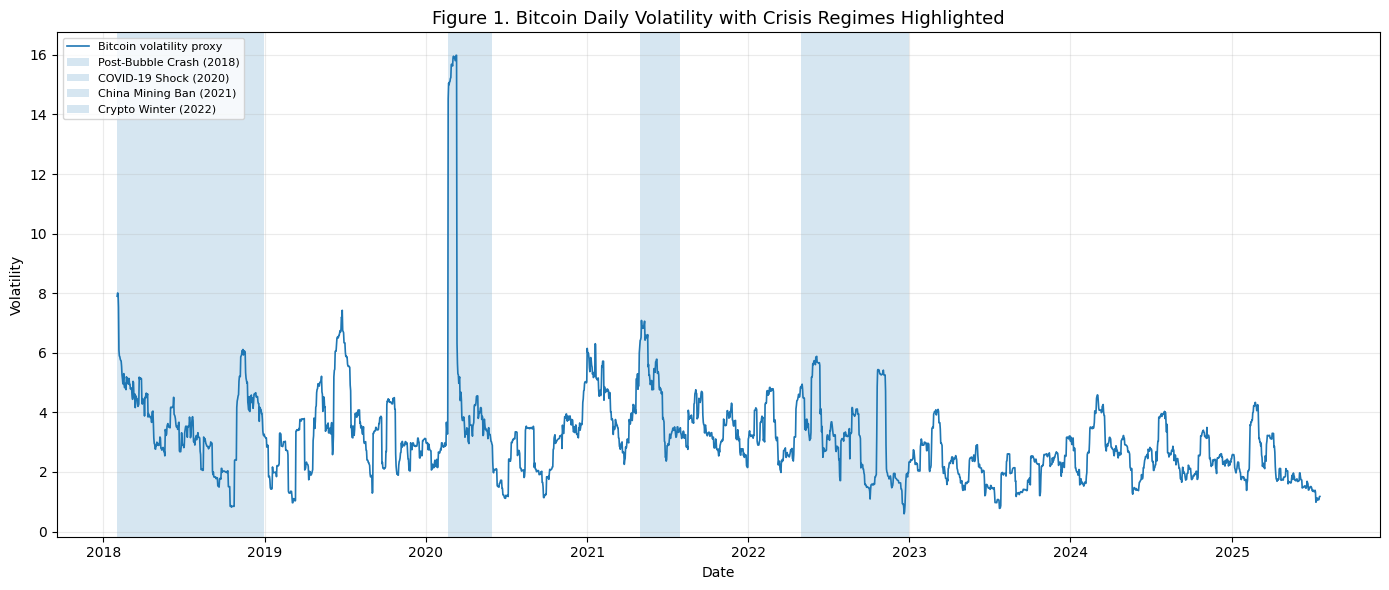

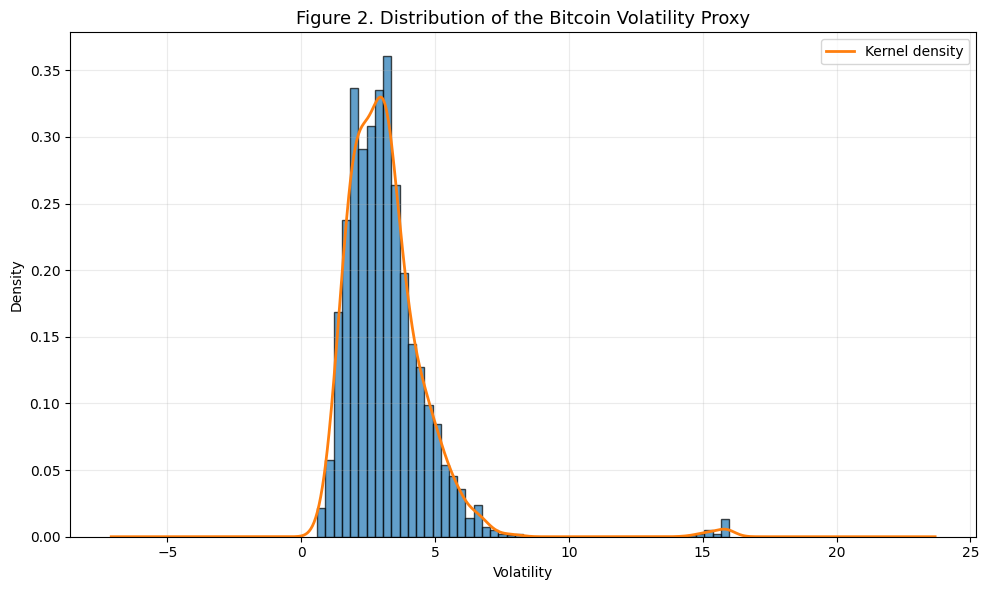

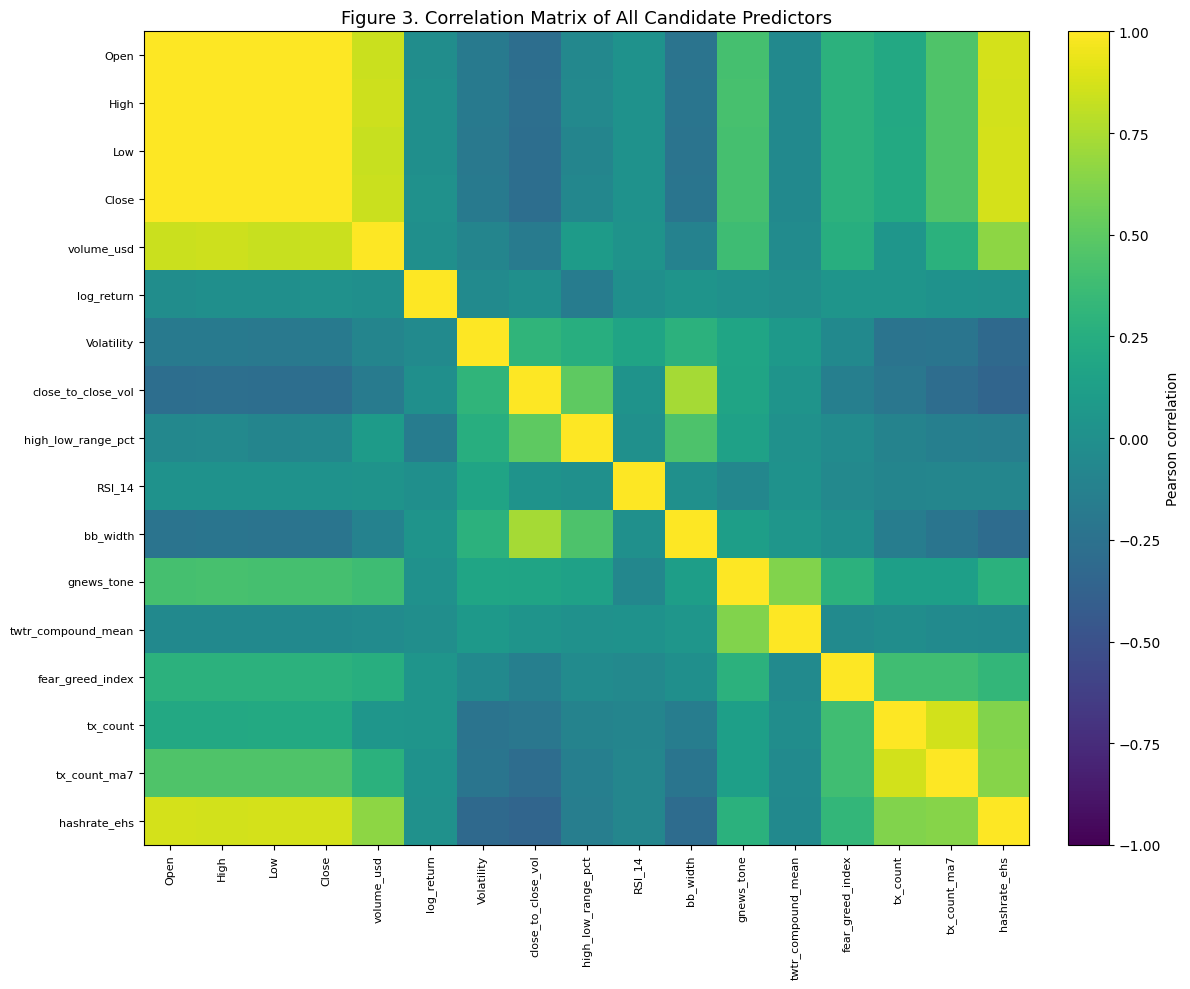

Descriptive regime counts:


,Regime,Observations
0,Normal,1952
1,Post-Bubble Crash (2018),331
2,Crypto Winter (2022),245
3,COVID-19 Shock (2020),102
4,China Mining Ban (2021),92



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Balanced_Data_With_Descriptive_Regimes.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Figure_1_Bitcoin_Daily_Volatility_Crisis_Regimes.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Figure_2_Distribution_Bitcoin_Volatility_Proxy.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Figure_3_Correlation_Matrix_All_Features.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Figure_3_Correlation_Matrix_Values.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Descriptive_Regime_Counts.csv


In [ ]:
# ============================================================
# STEP 3 — DESCRIPTIVE FIGURES AND CRISIS REGIMES
# Figures 1–3
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load cleaned files from Step 2
# ------------------------------------------------------------

raw_data = pd.read_csv(
    PROCESSED_DIR / "Raw_Data_Cleaned_All_Available.csv"
)

balanced_data = pd.read_csv(
    PROCESSED_DIR / "Balanced_Model_Data.csv"
)

raw_data["date"] = pd.to_datetime(
    raw_data["date"]
)

balanced_data["date"] = pd.to_datetime(
    balanced_data["date"]
)


# ------------------------------------------------------------
# 2. Crisis windows for descriptive analysis
# These appear in the manuscript figures and discussion
# ------------------------------------------------------------

CRISIS_WINDOWS_DESCRIPTIVE = {

    "Post-Bubble Crash (2018)": (
        pd.Timestamp("2018-02-01"),
        pd.Timestamp("2018-12-31")
    ),

    "COVID-19 Shock (2020)": (
        pd.Timestamp("2020-02-20"),
        pd.Timestamp("2020-05-31")
    ),

    "China Mining Ban (2021)": (
        pd.Timestamp("2021-05-01"),
        pd.Timestamp("2021-07-31")
    ),

    "Crypto Winter (2022)": (
        pd.Timestamp("2022-05-01"),
        pd.Timestamp("2022-12-31")
    )
}


def assign_descriptive_regime(date):

    for regime_name, (start_date, end_date) in CRISIS_WINDOWS_DESCRIPTIVE.items():

        if start_date <= date <= end_date:
            return regime_name

    return "Normal"


balanced_data["Descriptive_Regime"] = (
    balanced_data["date"]
    .map(assign_descriptive_regime)
)


# ------------------------------------------------------------
# 3. Save regime-labelled descriptive data
# ------------------------------------------------------------

REGIME_DATA_FILE = (
    PROCESSED_DIR
    / "Balanced_Data_With_Descriptive_Regimes.csv"
)

balanced_data.to_csv(
    REGIME_DATA_FILE,
    index=False
)


# ------------------------------------------------------------
# 4. Figure 1 — Bitcoin daily volatility with crises highlighted
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 6)
)

ax.plot(
    balanced_data["date"],
    balanced_data["Volatility"],
    linewidth=1.2,
    label="Bitcoin volatility proxy"
)

for crisis_name, (start_date, end_date) in CRISIS_WINDOWS_DESCRIPTIVE.items():

    ax.axvspan(
        start_date,
        end_date,
        alpha=0.18,
        label=crisis_name
    )

ax.set_title(
    "Figure 1. Bitcoin Daily Volatility with Crisis Regimes Highlighted",
    fontsize=13
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Volatility"
)

ax.legend(
    loc="upper left",
    fontsize=8,
    frameon=True
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

FIGURE_1_FILE = (
    FIGURES_DIR
    / "Figure_1_Bitcoin_Daily_Volatility_Crisis_Regimes.png"
)

plt.savefig(
    FIGURE_1_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. Figure 2 — Distribution of volatility proxy
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.hist(
    balanced_data["Volatility"],
    bins=50,
    density=True,
    alpha=0.70,
    edgecolor="black"
)

balanced_data["Volatility"].plot(
    kind="kde",
    ax=ax,
    linewidth=2,
    label="Kernel density"
)

ax.set_title(
    "Figure 2. Distribution of the Bitcoin Volatility Proxy",
    fontsize=13
)

ax.set_xlabel(
    "Volatility"
)

ax.set_ylabel(
    "Density"
)

ax.legend(
    frameon=True
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

FIGURE_2_FILE = (
    FIGURES_DIR
    / "Figure_2_Distribution_Bitcoin_Volatility_Proxy.png"
)

plt.savefig(
    FIGURE_2_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. Figure 3 — Correlation matrix of candidate predictors
# ------------------------------------------------------------

candidate_predictors = [

    "Open",
    "High",
    "Low",
    "Close",
    "volume_usd",
    "log_return",
    "Volatility",
    "close_to_close_vol",
    "high_low_range_pct",
    "atr",
    "RSI_14",
    "bb_width",
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index",
    "tx_count",
    "tx_count_ma7",
    "tx_volume_usd",
    "hashrate_ehs"
]

candidate_predictors = [
    column
    for column in candidate_predictors
    if column in raw_data.columns
]

correlation_matrix = (
    raw_data[
        candidate_predictors
    ]
    .corr()
)

CORRELATION_FILE = (
    TABLES_DIR
    / "Figure_3_Correlation_Matrix_Values.csv"
)

correlation_matrix.to_csv(
    CORRELATION_FILE
)


fig, ax = plt.subplots(
    figsize=(12, 10)
)

image = ax.imshow(
    correlation_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    np.arange(
        len(correlation_matrix.columns)
    )
)

ax.set_yticks(
    np.arange(
        len(correlation_matrix.index)
    )
)

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    correlation_matrix.index,
    fontsize=8
)

plt.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
    label="Pearson correlation"
)

ax.set_title(
    "Figure 3. Correlation Matrix of All Candidate Predictors",
    fontsize=13
)

plt.tight_layout()

FIGURE_3_FILE = (
    FIGURES_DIR
    / "Figure_3_Correlation_Matrix_All_Features.png"
)

plt.savefig(
    FIGURE_3_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Display and save regime counts
# ------------------------------------------------------------

regime_counts = (
    balanced_data["Descriptive_Regime"]
    .value_counts()
    .rename_axis("Regime")
    .reset_index(name="Observations")
)

REGIME_COUNTS_FILE = (
    TABLES_DIR
    / "Descriptive_Regime_Counts.csv"
)

regime_counts.to_csv(
    REGIME_COUNTS_FILE,
    index=False
)

print("Descriptive regime counts:")
display(regime_counts)

print("\nSaved files:")
print(REGIME_DATA_FILE)
print(FIGURE_1_FILE)
print(FIGURE_2_FILE)
print(FIGURE_3_FILE)
print(CORRELATION_FILE)
print(REGIME_COUNTS_FILE)

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# ------------------------------------------------------------
# Reconnect Google Drive and redefine project paths
# ------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

INPUT_DIR = PROJECT_DIR / "01_Input"
PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
FIGURES_DIR = PROJECT_DIR / "04_Figures"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Paths are ready.")
print(PROCESSED_DIR)
print(FIGURES_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Paths are ready.
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures


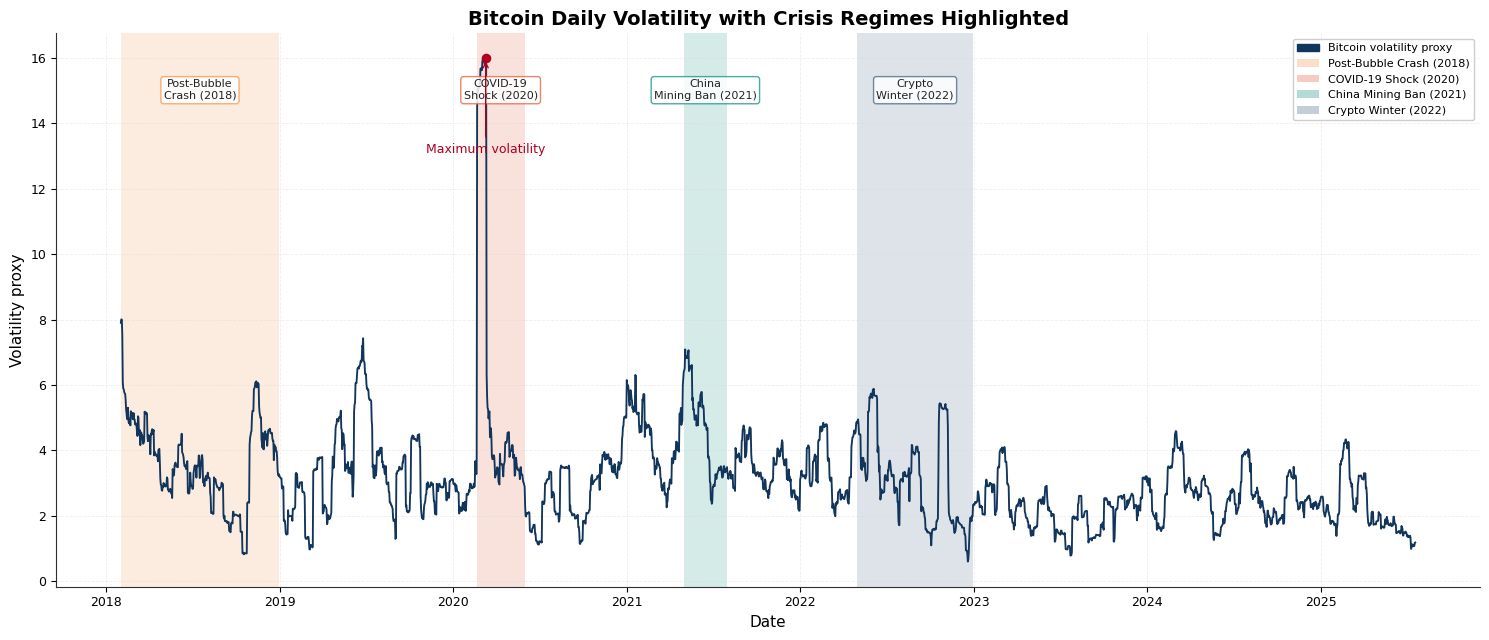

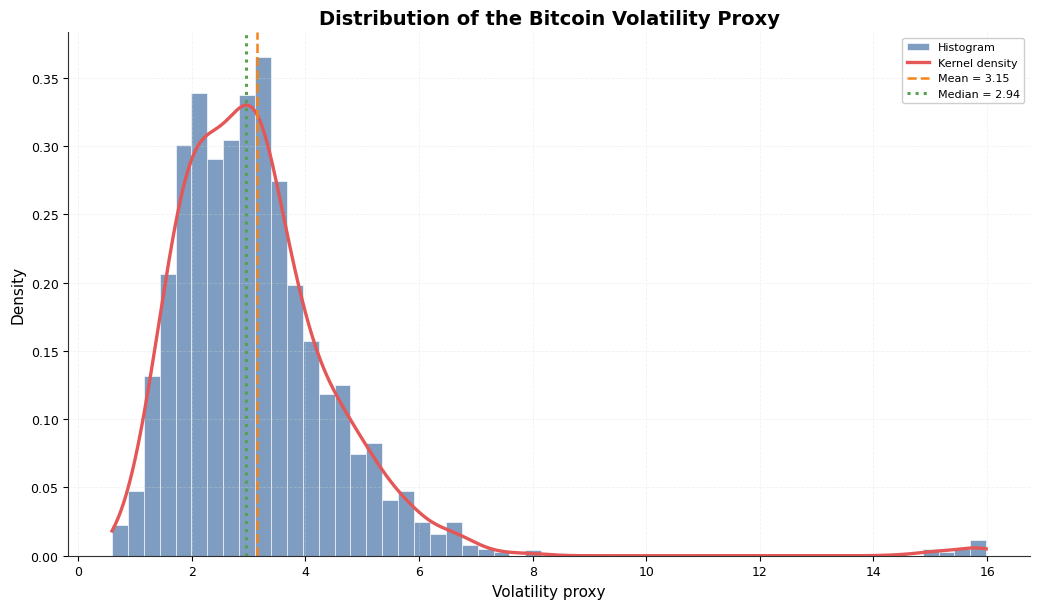

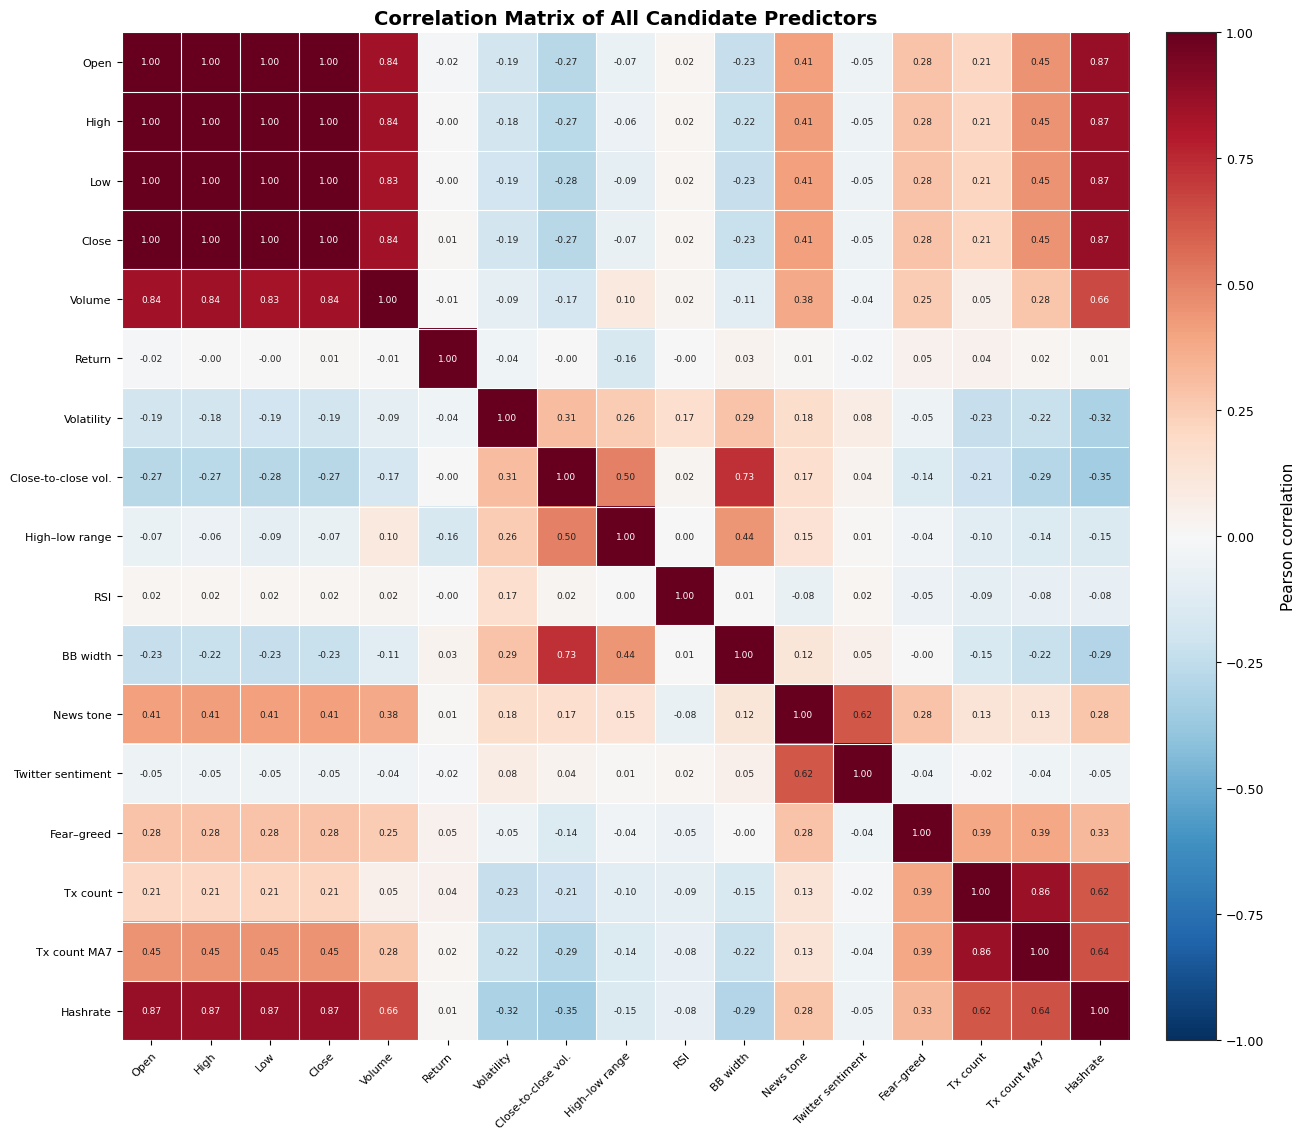

Descriptive regime counts:


,Regime,Observations
0,Normal,1952
1,Post-Bubble Crash (2018),331
2,Crypto Winter (2022),245
3,COVID-19 Shock (2020),102
4,China Mining Ban (2021),92



Saved professional figures:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Bitcoin_Daily_Volatility_Crisis_Regimes.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Bitcoin_Daily_Volatility_Crisis_Regimes.pdf
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Distribution_Bitcoin_Volatility_Proxy.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Distribution_Bitcoin_Volatility_Proxy.pdf
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Correlation_Matrix_All_Features.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Correlation_Matrix_All_Features.pdf
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Figure_3_Correlation_Matrix_Values.csv


In [4]:
# ============================================================
# STEP 3 — PROFESSIONAL DESCRIPTIVE FIGURES AND CRISIS REGIMES
# Figures 1–3
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import gaussian_kde
from matplotlib.patches import Patch


# ------------------------------------------------------------
# 1. Professional figure style
# ------------------------------------------------------------

plt.rcParams.update({

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "axes.edgecolor": "#2F2F2F",
    "axes.linewidth": 0.8,

    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,

    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "legend.fontsize": 8,
    "font.family": "DejaVu Sans",

    "grid.color": "#D9D9D9",
    "grid.linestyle": "--",
    "grid.linewidth": 0.6,

    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})


# ------------------------------------------------------------
# 2. Load cleaned files from Step 2
# ------------------------------------------------------------

raw_data = pd.read_csv(
    PROCESSED_DIR / "Raw_Data_Cleaned_All_Available.csv"
)

balanced_data = pd.read_csv(
    PROCESSED_DIR / "Balanced_Model_Data.csv"
)

raw_data["date"] = pd.to_datetime(
    raw_data["date"]
)

balanced_data["date"] = pd.to_datetime(
    balanced_data["date"]
)


# ------------------------------------------------------------
# 3. Crisis windows and colours
# ------------------------------------------------------------

CRISIS_WINDOWS_DESCRIPTIVE = {

    "Post-Bubble Crash (2018)": (
        pd.Timestamp("2018-02-01"),
        pd.Timestamp("2018-12-31")
    ),

    "COVID-19 Shock (2020)": (
        pd.Timestamp("2020-02-20"),
        pd.Timestamp("2020-05-31")
    ),

    "China Mining Ban (2021)": (
        pd.Timestamp("2021-05-01"),
        pd.Timestamp("2021-07-31")
    ),

    "Crypto Winter (2022)": (
        pd.Timestamp("2022-05-01"),
        pd.Timestamp("2022-12-31")
    )
}


CRISIS_COLORS = {

    "Post-Bubble Crash (2018)":
        "#F4A261",

    "COVID-19 Shock (2020)":
        "#E76F51",

    "China Mining Ban (2021)":
        "#2A9D8F",

    "Crypto Winter (2022)":
        "#577590"
}


def assign_descriptive_regime(date):

    for regime_name, (
        start_date,
        end_date
    ) in CRISIS_WINDOWS_DESCRIPTIVE.items():

        if start_date <= date <= end_date:
            return regime_name

    return "Normal"


balanced_data["Descriptive_Regime"] = (
    balanced_data["date"]
    .map(assign_descriptive_regime)
)


REGIME_DATA_FILE = (
    PROCESSED_DIR
    / "Balanced_Data_With_Descriptive_Regimes.csv"
)

balanced_data.to_csv(
    REGIME_DATA_FILE,
    index=False
)


# ------------------------------------------------------------
# 4. Figure 1 — Bitcoin volatility with crisis regimes
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 6.5)
)

ax.plot(
    balanced_data["date"],
    balanced_data["Volatility"],
    color="#12355B",
    linewidth=1.35,
    label="Bitcoin volatility proxy",
    zorder=3
)

for crisis_name, (
    start_date,
    end_date
) in CRISIS_WINDOWS_DESCRIPTIVE.items():

    ax.axvspan(
        start_date,
        end_date,
        color=CRISIS_COLORS[crisis_name],
        alpha=0.20,
        linewidth=0,
        zorder=1
    )

    middle_date = start_date + (
        end_date - start_date
    ) / 2

    ax.text(
        middle_date,
        balanced_data["Volatility"].max() * 0.96,
        crisis_name.replace(" ", "\n", 1),
        ha="center",
        va="top",
        fontsize=8,
        color="#222222",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=CRISIS_COLORS[crisis_name],
            alpha=0.85
        )
    )

peak_row = balanced_data.loc[
    balanced_data["Volatility"].idxmax()
]

ax.scatter(
    peak_row["date"],
    peak_row["Volatility"],
    color="#B00020",
    s=35,
    zorder=5
)

ax.annotate(
    "Maximum volatility",
    xy=(
        peak_row["date"],
        peak_row["Volatility"]
    ),
    xytext=(
        peak_row["date"],
        peak_row["Volatility"] * 0.82
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#B00020",
        linewidth=1
    ),
    fontsize=9,
    color="#B00020",
    ha="center"
)

legend_elements = [
    Patch(
        facecolor=CRISIS_COLORS[name],
        edgecolor="none",
        alpha=0.35,
        label=name
    )
    for name in CRISIS_WINDOWS_DESCRIPTIVE.keys()
]

legend_elements.insert(
    0,
    Patch(
        facecolor="#12355B",
        edgecolor="#12355B",
        label="Bitcoin volatility proxy"
    )
)

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True,
    framealpha=0.95,
    edgecolor="#CCCCCC"
)

ax.set_title(
    "Bitcoin Daily Volatility with Crisis Regimes Highlighted"
)

ax.set_xlabel(
    "Date"
)

ax.set_ylabel(
    "Volatility proxy"
)

ax.grid(
    True,
    alpha=0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

FIGURE_1_PNG = (
    FIGURES_DIR
    / "Bitcoin_Daily_Volatility_Crisis_Regimes.png"
)

FIGURE_1_PDF = (
    FIGURES_DIR
    / "Bitcoin_Daily_Volatility_Crisis_Regimes.pdf"
)

plt.savefig(FIGURE_1_PNG)
plt.savefig(FIGURE_1_PDF)

plt.show()


# ------------------------------------------------------------
# 5. Figure 2 — Distribution of volatility proxy
# ------------------------------------------------------------

volatility_values = (
    balanced_data["Volatility"]
    .dropna()
    .to_numpy(dtype=float)
)

x_grid = np.linspace(
    volatility_values.min(),
    volatility_values.max(),
    600
)

kde = gaussian_kde(
    volatility_values
)

mean_value = volatility_values.mean()
median_value = np.median(
    volatility_values
)

fig, ax = plt.subplots(
    figsize=(10.5, 6.2)
)

ax.hist(
    volatility_values,
    bins=55,
    density=True,
    color="#4C78A8",
    alpha=0.72,
    edgecolor="white",
    linewidth=0.6,
    label="Histogram"
)

ax.plot(
    x_grid,
    kde(x_grid),
    color="#E45756",
    linewidth=2.4,
    label="Kernel density"
)

ax.axvline(
    mean_value,
    color="#F58518",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_value:.2f}"
)

ax.axvline(
    median_value,
    color="#54A24B",
    linestyle=":",
    linewidth=2.2,
    label=f"Median = {median_value:.2f}"
)

ax.set_title(
    "Distribution of the Bitcoin Volatility Proxy"
)

ax.set_xlabel(
    "Volatility proxy"
)

ax.set_ylabel(
    "Density"
)

ax.legend(
    frameon=True,
    framealpha=0.95,
    edgecolor="#CCCCCC"
)

ax.grid(
    True,
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

FIGURE_2_PNG = (
    FIGURES_DIR
    / "Distribution_Bitcoin_Volatility_Proxy.png"
)

FIGURE_2_PDF = (
    FIGURES_DIR
    / "Distribution_Bitcoin_Volatility_Proxy.pdf"
)

plt.savefig(FIGURE_2_PNG)
plt.savefig(FIGURE_2_PDF)

plt.show()


# ------------------------------------------------------------
# 6. Figure 3 — Professional correlation matrix
# ------------------------------------------------------------

candidate_predictors = [

    "Open",
    "High",
    "Low",
    "Close",
    "volume_usd",
    "log_return",
    "Volatility",
    "close_to_close_vol",
    "high_low_range_pct",
    "atr",
    "RSI_14",
    "bb_width",
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index",
    "tx_count",
    "tx_count_ma7",
    "tx_volume_usd",
    "hashrate_ehs"
]

candidate_predictors = [
    column
    for column in candidate_predictors
    if column in raw_data.columns
]


display_names = {

    "Open": "Open",
    "High": "High",
    "Low": "Low",
    "Close": "Close",
    "volume_usd": "Volume",
    "log_return": "Return",
    "Volatility": "Volatility",
    "close_to_close_vol": "Close-to-close vol.",
    "high_low_range_pct": "High–low range",
    "atr": "ATR",
    "RSI_14": "RSI",
    "bb_width": "BB width",
    "gnews_tone": "News tone",
    "twtr_compound_mean": "Twitter sentiment",
    "fear_greed_index": "Fear–greed",
    "tx_count": "Tx count",
    "tx_count_ma7": "Tx count MA7",
    "tx_volume_usd": "Tx volume",
    "hashrate_ehs": "Hashrate"
}


correlation_matrix = (
    raw_data[candidate_predictors]
    .corr()
)

correlation_matrix_named = correlation_matrix.rename(
    index=display_names,
    columns=display_names
)


CORRELATION_FILE = (
    TABLES_DIR
    / "Figure_3_Correlation_Matrix_Values.csv"
)

correlation_matrix_named.to_csv(
    CORRELATION_FILE
)


fig, ax = plt.subplots(
    figsize=(13.5, 11.5)
)

matrix_values = correlation_matrix_named.to_numpy()

image = ax.imshow(
    matrix_values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    np.arange(
        len(correlation_matrix_named.columns)
    )
)

ax.set_yticks(
    np.arange(
        len(correlation_matrix_named.index)
    )
)

ax.set_xticklabels(
    correlation_matrix_named.columns,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=8
)

ax.set_yticklabels(
    correlation_matrix_named.index,
    fontsize=8
)

# Add correlation values inside the cells
for i in range(matrix_values.shape[0]):

    for j in range(matrix_values.shape[1]):

        value = matrix_values[i, j]

        if np.isfinite(value):

            text_color = (
                "white"
                if abs(value) >= 0.65
                else "#222222"
            )

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=6.5,
                color=text_color
            )


# Add clean grid lines
ax.set_xticks(
    np.arange(
        -0.5,
        len(correlation_matrix_named.columns),
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(correlation_matrix_named.index),
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=0.8
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

colorbar = plt.colorbar(
    image,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

colorbar.set_label(
    "Pearson correlation",
    rotation=90,
    labelpad=12
)

ax.set_title(
    "Correlation Matrix of All Candidate Predictors"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()

FIGURE_3_PNG = (
    FIGURES_DIR
    / "Correlation_Matrix_All_Features.png"
)

FIGURE_3_PDF = (
    FIGURES_DIR
    / "Correlation_Matrix_All_Features.pdf"
)

plt.savefig(FIGURE_3_PNG)
plt.savefig(FIGURE_3_PDF)

plt.show()


# ------------------------------------------------------------
# 7. Save descriptive regime counts
# ------------------------------------------------------------

regime_counts = (
    balanced_data["Descriptive_Regime"]
    .value_counts()
    .rename_axis("Regime")
    .reset_index(name="Observations")
)

REGIME_COUNTS_FILE = (
    TABLES_DIR
    / "Descriptive_Regime_Counts.csv"
)

regime_counts.to_csv(
    REGIME_COUNTS_FILE,
    index=False
)

print("Descriptive regime counts:")
display(regime_counts)

print("\nSaved professional figures:")
print(FIGURE_1_PNG)
print(FIGURE_1_PDF)
print(FIGURE_2_PNG)
print(FIGURE_2_PDF)
print(FIGURE_3_PNG)
print(FIGURE_3_PDF)
print(CORRELATION_FILE)

In [ ]:
# ============================================================
# STEP 4 — FINAL FORECASTING DESIGN
# Same methodology, clean reproducible implementation
# Uses existing log_return variable from the raw dataset
# ============================================================

import json
import numpy as np
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 1. Load balanced dataset
# ------------------------------------------------------------

balanced_data = pd.read_csv(
    PROCESSED_DIR / "Balanced_Model_Data.csv"
)

balanced_data["date"] = pd.to_datetime(
    balanced_data["date"]
)

balanced_data = (
    balanced_data
    .sort_values("date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Return variable
# The dataset already contains daily logarithmic returns.
# We convert them into percentage scale for GARCH estimation.
# ------------------------------------------------------------

if "log_return" not in balanced_data.columns:
    raise ValueError(
        "Column 'log_return' is required but was not found."
    )

balanced_data["Returns"] = (
    pd.to_numeric(
        balanced_data["log_return"],
        errors="coerce"
    )
    * 100.0
)

# The manuscript states that constructing returns removes the first observation.
# Therefore, we drop the first balanced observation for model implementation.
model_data = (
    balanced_data
    .iloc[1:]
    .dropna(
        subset=["Returns"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Information sets
# ------------------------------------------------------------

TARGET_COLUMN = "Volatility"

T_FEATURES = [
    "close_to_close_vol",
    "high_low_range_pct",
    "bb_width",
    "RSI_14"
]

TS_FEATURES = T_FEATURES + [
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index"
]

TSB_FEATURES = TS_FEATURES + [
    "tx_count_ma7",
    "hashrate_ehs"
]

INFORMATION_SETS = {
    "T": T_FEATURES,
    "TS": TS_FEATURES,
    "TSB": TSB_FEATURES
}


required_columns = (
    [
        "date",
        "Returns",
        TARGET_COLUMN
    ]
    + TSB_FEATURES
)

missing_columns = [
    column
    for column in required_columns
    if column not in model_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required model columns: {missing_columns}"
    )


# ------------------------------------------------------------
# 4. Training and out-of-sample design
# ------------------------------------------------------------

TRAIN_END = pd.Timestamp(
    "2019-12-31"
)

OOS_START = pd.Timestamp(
    "2020-01-01"
)

OOS_END = pd.Timestamp(
    "2025-07-19"
)

LOOKBACK = 30

model_data["Sample"] = np.where(
    model_data["date"] <= TRAIN_END,
    "Training",
    "Out-of-sample"
)


# ------------------------------------------------------------
# 5. Forecast evaluation regimes
# 2018 is descriptive only, not formal OOS evaluation
# ------------------------------------------------------------

CRISIS_WINDOWS_FORECASTING = {

    "COVID-19 Shock": (
        pd.Timestamp("2020-02-20"),
        pd.Timestamp("2020-05-31")
    ),

    "China Mining Ban": (
        pd.Timestamp("2021-05-01"),
        pd.Timestamp("2021-07-31")
    ),

    "Crypto Winter": (
        pd.Timestamp("2022-05-01"),
        pd.Timestamp("2022-12-31")
    )
}


def assign_forecast_regime(date):

    if date < OOS_START:
        return "Training"

    for regime_name, (
        start_date,
        end_date
    ) in CRISIS_WINDOWS_FORECASTING.items():

        if start_date <= date <= end_date:
            return regime_name

    return "Normal"


model_data["Forecast_Regime"] = (
    model_data["date"]
    .map(assign_forecast_regime)
)


training_data = (
    model_data
    .loc[
        model_data["date"] <= TRAIN_END
    ]
    .copy()
)

oos_data = (
    model_data
    .loc[
        model_data["date"].between(
            OOS_START,
            OOS_END
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 6. Standard variance-based QLIKE and error metrics
# ------------------------------------------------------------

def qlike_variance_loss(
    actual_volatility,
    forecast_volatility
):

    actual_variance = np.maximum(
        np.asarray(
            actual_volatility,
            dtype=float
        ) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(
            forecast_volatility,
            dtype=float
        ) ** 2,
        1e-12
    )

    ratio = (
        actual_variance
        / forecast_variance
    )

    return float(
        np.mean(
            ratio
            - np.log(ratio)
            - 1.0
        )
    )


def rmse_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(
                        actual_volatility,
                        dtype=float
                    )
                    - np.asarray(
                        forecast_volatility,
                        dtype=float
                    )
                ) ** 2
            )
        )
    )


def mae_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            np.abs(
                np.asarray(
                    actual_volatility,
                    dtype=float
                )
                - np.asarray(
                    forecast_volatility,
                    dtype=float
                )
            )
        )
    )


# ------------------------------------------------------------
# 7. Save forecasting design
# ------------------------------------------------------------

MODEL_DATA_FILE = (
    PROCESSED_DIR
    / "Model_Data_With_Forecast_Regimes.csv"
)

model_data.to_csv(
    MODEL_DATA_FILE,
    index=False
)


forecasting_configuration = {

    "model_observations":
        int(len(model_data)),

    "model_period_start":
        str(model_data["date"].min().date()),

    "model_period_end":
        str(model_data["date"].max().date()),

    "training_observations":
        int(len(training_data)),

    "training_start":
        str(training_data["date"].min().date()),

    "training_end":
        str(training_data["date"].max().date()),

    "out_of_sample_observations":
        int(len(oos_data)),

    "out_of_sample_start":
        str(oos_data["date"].min().date()),

    "out_of_sample_end":
        str(oos_data["date"].max().date()),

    "lookback_days":
        LOOKBACK,

    "target_column":
        TARGET_COLUMN,

    "return_column":
        "Returns",

    "information_sets":
        INFORMATION_SETS,

    "forecasting_crisis_windows": {
        name: [
            str(start.date()),
            str(end.date())
        ]
        for name, (
            start,
            end
        ) in CRISIS_WINDOWS_FORECASTING.items()
    },

    "qlike_formula":
        "mean((actual_volatility^2 / forecast_volatility^2) - log(actual_volatility^2 / forecast_volatility^2) - 1)"
}


CONFIG_FORECASTING_FILE = (
    PROCESSED_DIR
    / "Forecasting_Design_Config.json"
)

with open(
    CONFIG_FORECASTING_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        forecasting_configuration,
        file,
        indent=4
    )


# ------------------------------------------------------------
# 8. Display verification
# ------------------------------------------------------------

print("Model observations:", len(model_data))

print(
    "Model period:",
    model_data["date"].min().date(),
    "to",
    model_data["date"].max().date()
)

print("\nTraining observations:", len(training_data))

print(
    "Training period:",
    training_data["date"].min().date(),
    "to",
    training_data["date"].max().date()
)

print("\nOut-of-sample observations:", len(oos_data))

print(
    "Out-of-sample period:",
    oos_data["date"].min().date(),
    "to",
    oos_data["date"].max().date()
)

print("\nForecast regime counts:")

forecast_regime_counts = (
    oos_data["Forecast_Regime"]
    .value_counts()
    .rename_axis("Regime")
    .reset_index(name="Observations")
)

display(
    forecast_regime_counts
)

print("\nInformation sets:")
print("T:", T_FEATURES)
print("TS:", TS_FEATURES)
print("TSB:", TSB_FEATURES)

print("\nSaved files:")
print(MODEL_DATA_FILE)
print(CONFIG_FORECASTING_FILE)

print("\nForecasting design completed successfully.")

Model observations: 2721
Model period: 2018-02-02 to 2025-07-19

Training observations: 695
Training period: 2018-02-02 to 2019-12-31

Out-of-sample observations: 2026
Out-of-sample period: 2020-01-01 to 2025-07-19

Forecast regime counts:


,Regime,Observations
0,Normal,1587
1,Crypto Winter,245
2,COVID-19 Shock,102
3,China Mining Ban,92



Information sets:
T: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14']
TS: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index']
TSB: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index', 'tx_count_ma7', 'hashrate_ehs']

Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Model_Data_With_Forecast_Regimes.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed/Forecasting_Design_Config.json

Forecasting design completed successfully.


In [ ]:
# ============================================================
# STEP 5 — TRADITIONAL VOLATILITY MODELS
# Rolling one-step-ahead forecasts
# GARCH, iGARCH, TGARCH, GJR-GARCH, APARCH, EGARCH
# ============================================================

!pip install -q arch

import math
import warnings
import numpy as np
import pandas as pd

from pathlib import Path
from arch import arch_model
from scipy.optimize import minimize
from scipy.special import expit, logit
from tqdm.auto import tqdm
from IPython.display import display


# ------------------------------------------------------------
# 1. Load model data from Step 4
# ------------------------------------------------------------

model_data = pd.read_csv(
    PROCESSED_DIR / "Model_Data_With_Forecast_Regimes.csv"
)

model_data["date"] = pd.to_datetime(
    model_data["date"]
)

model_data = (
    model_data
    .sort_values("date")
    .reset_index(drop=True)
)


TRAIN_END = pd.Timestamp("2019-12-31")
OOS_START = pd.Timestamp("2020-01-01")
OOS_END = pd.Timestamp("2025-07-19")

training_data = model_data.loc[
    model_data["date"] <= TRAIN_END
].copy()

oos_data = model_data.loc[
    model_data["date"].between(
        OOS_START,
        OOS_END
    )
].copy()


WINDOW_SIZE = len(training_data)
EPSILON = 1e-10
CHECKPOINT_EVERY = 25

assert WINDOW_SIZE == 695
assert len(oos_data) == 2026


# ------------------------------------------------------------
# 2. Output folder
# ------------------------------------------------------------

TRADITIONAL_DIR = (
    FORECASTS_DIR
    / "Traditional_Models"
)

TRADITIONAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 3. Forecast dates and arrays
# ------------------------------------------------------------

returns_pct = model_data[
    "Returns"
].to_numpy(dtype=float)

forecast_dates = pd.DatetimeIndex(
    oos_data["date"]
)

actual_oos = oos_data[
    TARGET_COLUMN
].to_numpy(dtype=float)

forecast_regimes = oos_data[
    "Forecast_Regime"
].to_numpy()


MODEL_NAMES = [
    "GARCH",
    "iGARCH",
    "TGARCH",
    "GJR-GARCH",
    "APARCH",
    "EGARCH"
]


print("Rolling-window size:", WINDOW_SIZE)
print("Forecast observations:", len(forecast_dates))
print("Forecast period:", forecast_dates.min().date(), "to", forecast_dates.max().date())


# ------------------------------------------------------------
# 4. Standard GARCH-family specifications
# ------------------------------------------------------------

ARCH_SPECIFICATIONS = {

    "GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1,
        "power": 2.0
    },

    # Zakoian-style threshold model on conditional scale
    "TGARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1,
        "power": 1.0
    },

    # GJR-GARCH variance-threshold model
    "GJR-GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1,
        "power": 2.0
    },

    "APARCH": {
        "vol": "APARCH",
        "p": 1,
        "o": 1,
        "q": 1
    },

    "EGARCH": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 1
    }
}


# ------------------------------------------------------------
# 5. Fit one standard ARCH model
# ------------------------------------------------------------

def fit_arch_one_step(
    training_returns,
    model_name,
    previous_parameters=None
):

    specification = ARCH_SPECIFICATIONS[
        model_name
    ]

    arguments = {

        "y":
            pd.Series(
                training_returns,
                dtype=float
            ),

        "mean":
            "Constant",

        "vol":
            specification["vol"],

        "p":
            specification["p"],

        "o":
            specification["o"],

        "q":
            specification["q"],

        "dist":
            "normal",

        "rescale":
            False
    }

    if "power" in specification:

        arguments["power"] = specification[
            "power"
        ]

    model = arch_model(
        **arguments
    )

    starting_attempts = []

    if previous_parameters is not None:

        previous_parameters = np.asarray(
            previous_parameters,
            dtype=float
        )

        if np.isfinite(previous_parameters).all():

            starting_attempts.append(
                previous_parameters
            )

    starting_attempts.append(None)

    best_result = None

    for starting_values in starting_attempts:

        try:

            with warnings.catch_warnings():

                warnings.simplefilter("ignore")

                result = model.fit(
                    disp="off",
                    show_warning=False,
                    update_freq=0,
                    starting_values=starting_values,
                    tol=1e-7,
                    options={
                        "maxiter": 2500,
                        "ftol": 1e-9
                    }
                )

            forecast_object = result.forecast(
                horizon=1,
                method="analytic",
                reindex=False
            )

            forecast_variance = float(
                forecast_object
                .variance
                .iloc[-1, 0]
            )

            valid = bool(
                result.convergence_flag == 0
                and np.isfinite(forecast_variance)
                and forecast_variance > 0
            )

            candidate = {

                "valid":
                    valid,

                "loglikelihood":
                    float(result.loglikelihood),

                "forecast_variance":
                    forecast_variance,

                "parameters":
                    result.params.to_numpy(dtype=float),

                "convergence_flag":
                    int(result.convergence_flag)
            }

            if (
                best_result is None
                or candidate["valid"] > best_result["valid"]
                or (
                    candidate["valid"] == best_result["valid"]
                    and candidate["loglikelihood"] > best_result["loglikelihood"]
                )
            ):

                best_result = candidate

            if valid:
                break

        except Exception:
            continue

    if best_result is None:

        return np.nan, None, 999

    if not best_result["valid"]:

        return (
            np.nan,
            best_result["parameters"],
            best_result["convergence_flag"]
        )

    forecast_volatility = math.sqrt(
        best_result["forecast_variance"]
    )

    return (
        forecast_volatility,
        best_result["parameters"],
        0
    )


# ------------------------------------------------------------
# 6. True iGARCH with alpha + beta = 1
# ------------------------------------------------------------

def igarch_negative_loglikelihood(
    parameters,
    returns
):

    mean_parameter = parameters[0]
    omega = np.exp(parameters[1])
    alpha = expit(parameters[2])
    beta = 1.0 - alpha

    residuals = returns - mean_parameter

    variance = np.empty(
        len(residuals),
        dtype=float
    )

    variance[0] = max(
        np.var(
            residuals,
            ddof=1
        ),
        EPSILON
    )

    for index in range(
        1,
        len(residuals)
    ):

        variance[index] = (
            omega
            + alpha * residuals[index - 1] ** 2
            + beta * variance[index - 1]
        )

        if (
            not np.isfinite(variance[index])
            or variance[index] <= EPSILON
        ):

            return 1e100

    likelihood = 0.5 * np.sum(
        np.log(2.0 * np.pi)
        + np.log(variance)
        + residuals ** 2 / variance
    )

    if not np.isfinite(likelihood):

        return 1e100

    return float(likelihood)


def fit_igarch_one_step(
    training_returns,
    previous_parameters=None
):

    training_returns = np.asarray(
        training_returns,
        dtype=float
    )

    sample_mean = float(
        np.mean(training_returns)
    )

    sample_variance = max(
        np.var(
            training_returns,
            ddof=1
        ),
        EPSILON
    )

    starting_values = []

    if previous_parameters is not None:

        previous_parameters = np.asarray(
            previous_parameters,
            dtype=float
        )

        if (
            len(previous_parameters) == 3
            and np.isfinite(previous_parameters).all()
        ):

            starting_values.append(
                previous_parameters
            )

    for initial_alpha in [
        0.03,
        0.07,
        0.15
    ]:

        starting_values.append(
            np.array([
                sample_mean,
                np.log(
                    max(
                        sample_variance * 0.005,
                        EPSILON
                    )
                ),
                logit(initial_alpha)
            ])
        )

    bounds = [
        (-20.0, 20.0),
        (-25.0, 10.0),
        (-10.0, 10.0)
    ]

    best_result = None

    for initial_values in starting_values:

        try:

            optimisation = minimize(
                igarch_negative_loglikelihood,
                x0=initial_values,
                args=(training_returns,),
                method="L-BFGS-B",
                bounds=bounds,
                options={
                    "maxiter": 3000,
                    "ftol": 1e-12,
                    "gtol": 1e-8
                }
            )

            valid = bool(
                optimisation.success
                and np.isfinite(optimisation.fun)
            )

            candidate = {
                "valid": valid,
                "objective": float(optimisation.fun),
                "parameters": optimisation.x
            }

            if (
                best_result is None
                or candidate["valid"] > best_result["valid"]
                or (
                    candidate["valid"] == best_result["valid"]
                    and candidate["objective"] < best_result["objective"]
                )
            ):

                best_result = candidate

        except Exception:
            continue

    if best_result is None:

        return np.nan, None, 999

    parameters = best_result["parameters"]

    if not best_result["valid"]:

        return np.nan, parameters, 1

    mean_parameter = parameters[0]
    omega = np.exp(parameters[1])
    alpha = expit(parameters[2])
    beta = 1.0 - alpha

    residuals = training_returns - mean_parameter

    variance = np.empty(
        len(residuals),
        dtype=float
    )

    variance[0] = max(
        np.var(
            residuals,
            ddof=1
        ),
        EPSILON
    )

    for index in range(
        1,
        len(residuals)
    ):

        variance[index] = max(
            omega
            + alpha * residuals[index - 1] ** 2
            + beta * variance[index - 1],
            EPSILON
        )

    next_variance = (
        omega
        + alpha * residuals[-1] ** 2
        + beta * variance[-1]
    )

    if (
        not np.isfinite(next_variance)
        or next_variance <= 0
    ):

        return np.nan, parameters, 2

    return (
        math.sqrt(next_variance),
        parameters,
        0
    )


# ------------------------------------------------------------
# 7. Checkpoint functions
# ------------------------------------------------------------

PARAMETER_COLUMNS = [
    f"parameter_{index}"
    for index in range(10)
]


def create_checkpoint():

    checkpoint = pd.DataFrame({

        "date":
            forecast_dates,

        "Forecast_Regime":
            forecast_regimes,

        "Actual_Volatility":
            actual_oos,

        "forecast":
            np.nan,

        "convergence_flag":
            999,

        "completed":
            False
    })

    for column in PARAMETER_COLUMNS:

        checkpoint[column] = np.nan

    return checkpoint


def checkpoint_path_for_model(
    model_name
):

    safe_name = (
        model_name
        .replace("-", "_")
        .replace(" ", "_")
    )

    return (
        TRADITIONAL_DIR
        / f"{safe_name}_checkpoint.csv"
    )


def load_checkpoint(
    model_name
):

    checkpoint_path = checkpoint_path_for_model(
        model_name
    )

    if not checkpoint_path.exists():

        return (
            create_checkpoint(),
            checkpoint_path
        )

    checkpoint = pd.read_csv(
        checkpoint_path
    )

    checkpoint["date"] = pd.to_datetime(
        checkpoint["date"]
    )

    checkpoint["completed"] = (
        checkpoint["completed"]
        .astype(str)
        .str.lower()
        .eq("true")
    )

    if list(checkpoint["date"]) != list(forecast_dates):

        raise RuntimeError(
            f"{model_name}: checkpoint dates do not match."
        )

    for column in PARAMETER_COLUMNS:

        if column not in checkpoint.columns:

            checkpoint[column] = np.nan

    return (
        checkpoint,
        checkpoint_path
    )


def recover_previous_parameters(
    checkpoint
):

    completed_rows = checkpoint.loc[
        checkpoint["completed"]
    ]

    if completed_rows.empty:

        return None

    final_row = completed_rows.iloc[-1]

    parameter_values = (
        final_row[PARAMETER_COLUMNS]
        .dropna()
        .to_numpy(dtype=float)
    )

    if len(parameter_values) == 0:

        return None

    return parameter_values


# ------------------------------------------------------------
# 8. Run one model
# ------------------------------------------------------------

def run_traditional_model(
    model_name
):

    checkpoint, checkpoint_path = load_checkpoint(
        model_name
    )

    previous_parameters = recover_previous_parameters(
        checkpoint
    )

    for position in tqdm(
        range(len(forecast_dates)),
        desc=f"{model_name} rolling forecasts"
    ):

        if bool(
            checkpoint.loc[
                position,
                "completed"
            ]
        ):

            continue

        target_index = (
            WINDOW_SIZE
            + position
        )

        training_returns = returns_pct[
            target_index - WINDOW_SIZE:
            target_index
        ]

        if model_name == "iGARCH":

            (
                forecast,
                estimated_parameters,
                convergence_flag
            ) = fit_igarch_one_step(
                training_returns,
                previous_parameters
            )

        else:

            (
                forecast,
                estimated_parameters,
                convergence_flag
            ) = fit_arch_one_step(
                training_returns,
                model_name,
                previous_parameters
            )

        checkpoint.loc[
            position,
            "forecast"
        ] = forecast

        checkpoint.loc[
            position,
            "convergence_flag"
        ] = convergence_flag

        checkpoint.loc[
            position,
            "completed"
        ] = True

        if estimated_parameters is not None:

            estimated_parameters = np.asarray(
                estimated_parameters,
                dtype=float
            )

            previous_parameters = (
                estimated_parameters.copy()
            )

            for parameter_index, value in enumerate(
                estimated_parameters[:10]
            ):

                checkpoint.loc[
                    position,
                    f"parameter_{parameter_index}"
                ] = value

        if (
            position + 1
        ) % CHECKPOINT_EVERY == 0:

            checkpoint.to_csv(
                checkpoint_path,
                index=False
            )

    checkpoint.to_csv(
        checkpoint_path,
        index=False
    )

    return checkpoint


# ------------------------------------------------------------
# 9. Run all six models
# ------------------------------------------------------------

traditional_outputs = {}

for model_name in MODEL_NAMES:

    print("\nEstimating:", model_name)

    traditional_outputs[
        model_name
    ] = run_traditional_model(
        model_name
    )


# ------------------------------------------------------------
# 10. Combine forecasts into one file
# ------------------------------------------------------------

traditional_forecasts = pd.DataFrame({

    "date":
        forecast_dates,

    "Forecast_Regime":
        forecast_regimes,

    "Actual_Volatility":
        actual_oos
})


summary_rows = []

for model_name in MODEL_NAMES:

    model_output = traditional_outputs[
        model_name
    ]

    forecasts = pd.to_numeric(
        model_output["forecast"],
        errors="coerce"
    ).to_numpy(dtype=float)

    valid = (
        np.isfinite(forecasts)
        & (forecasts > 0)
    )

    traditional_forecasts[
        model_name
    ] = forecasts

    summary_rows.append({

        "Model":
            model_name,

        "Expected forecasts":
            len(forecasts),

        "Completed":
            int(model_output["completed"].sum()),

        "Valid forecasts":
            int(valid.sum()),

        "Failed forecasts":
            int((~valid).sum()),

        "Convergence flags":
            int(
                (
                    model_output["convergence_flag"] != 0
                ).sum()
            )
    })


TRADITIONAL_SUMMARY = pd.DataFrame(
    summary_rows
)


TRADITIONAL_FORECAST_FILE = (
    FORECASTS_DIR
    / "Traditional_Model_Forecasts.csv"
)

TRADITIONAL_SUMMARY_FILE = (
    TABLES_DIR
    / "Traditional_Model_Estimation_Summary.csv"
)

traditional_forecasts.to_csv(
    TRADITIONAL_FORECAST_FILE,
    index=False
)

TRADITIONAL_SUMMARY.to_csv(
    TRADITIONAL_SUMMARY_FILE,
    index=False
)


print("\nTraditional model estimation summary:")

display(
    TRADITIONAL_SUMMARY
)

print("\nSaved files:")
print(TRADITIONAL_FORECAST_FILE)
print(TRADITIONAL_SUMMARY_FILE)

print("\nStep 5 completed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 13.2 MB/s eta 0:00:00
Rolling-window size: 695
Forecast observations: 2026
Forecast period: 2020-01-01 to 2025-07-19

Estimating: GARCH


GARCH rolling forecasts:   0%|          | 0/2026 [00:00<?, ?it/s]


Estimating: iGARCH


iGARCH rolling forecasts:   0%|          | 0/2026 [00:00<?, ?it/s]


Estimating: TGARCH


...


Estimating: EGARCH


EGARCH rolling forecasts:   0%|          | 0/2026 [00:00<?, ?it/s]


Traditional model estimation summary:


,Model,Expected forecasts,Completed,Valid forecasts,Failed forecasts,Convergence flags
0,GARCH,2026,2026,2026,0,0
1,iGARCH,2026,2026,2026,0,0
2,TGARCH,2026,2026,2026,0,0
3,GJR-GARCH,2026,2026,2026,0,0
4,APARCH,2026,2026,2022,4,4
5,EGARCH,2026,2026,2025,1,1



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Traditional_Model_Forecasts.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Traditional_Model_Estimation_Summary.csv

Step 5 completed successfully.


In [ ]:
# ============================================================
# STEP 6 — TABLE 2: TRADITIONAL VOLATILITY MODELS
# Normal Period, Out-of-Sample
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Load traditional forecasts
# ------------------------------------------------------------

TRADITIONAL_FORECAST_FILE = (
    FORECASTS_DIR
    / "Traditional_Model_Forecasts.csv"
)

traditional_forecasts = pd.read_csv(
    TRADITIONAL_FORECAST_FILE
)

traditional_forecasts["date"] = pd.to_datetime(
    traditional_forecasts["date"]
)


MODEL_NAMES = [
    "GARCH",
    "iGARCH",
    "TGARCH",
    "GJR-GARCH",
    "APARCH",
    "EGARCH"
]


# ------------------------------------------------------------
# 2. Standard variance-based QLIKE
# ------------------------------------------------------------

def qlike_variance_loss(
    actual_volatility,
    forecast_volatility
):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return float(
        np.mean(
            ratio
            - np.log(ratio)
            - 1.0
        )
    )


def rmse_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 3. Diagnostics for valid forecasts
# ------------------------------------------------------------

diagnostic_rows = []

for model_name in MODEL_NAMES:

    values = pd.to_numeric(
        traditional_forecasts[model_name],
        errors="coerce"
    )

    valid = (
        np.isfinite(values)
        & (values > 0)
    )

    diagnostic_rows.append({

        "Model":
            model_name,

        "Total OOS forecasts":
            len(values),

        "Valid forecasts":
            int(valid.sum()),

        "Failed forecasts":
            int((~valid).sum()),

        "Minimum forecast":
            float(values[valid].min())
            if valid.sum() > 0
            else np.nan,

        "Maximum forecast":
            float(values[valid].max())
            if valid.sum() > 0
            else np.nan
    })


TRADITIONAL_DIAGNOSTICS = pd.DataFrame(
    diagnostic_rows
)


# ------------------------------------------------------------
# 4. Use common valid sample for fair comparison
# ------------------------------------------------------------

comparison_columns = [
    "Actual_Volatility"
] + MODEL_NAMES

comparison_values = traditional_forecasts[
    comparison_columns
].to_numpy(dtype=float)

common_valid_mask = (
    np.isfinite(comparison_values).all(axis=1)
    & (comparison_values > 0).all(axis=1)
)

traditional_common = traditional_forecasts.loc[
    common_valid_mask
].copy()

traditional_normal = traditional_common.loc[
    traditional_common["Forecast_Regime"] == "Normal"
].copy()


# ------------------------------------------------------------
# 5. Compute Table 2 metrics
# ------------------------------------------------------------

actual_normal = traditional_normal[
    "Actual_Volatility"
].to_numpy(dtype=float)

table_2_rows = []

for model_name in MODEL_NAMES:

    forecast_normal = traditional_normal[
        model_name
    ].to_numpy(dtype=float)

    table_2_rows.append({

        "Model":
            model_name,

        "Observations":
            len(traditional_normal),

        "QLIKE":
            qlike_variance_loss(
                actual_normal,
                forecast_normal
            ),

        "RMSE":
            rmse_loss(
                actual_normal,
                forecast_normal
            ),

        "MAE":
            mae_loss(
                actual_normal,
                forecast_normal
            )
    })


TABLE_2 = pd.DataFrame(
    table_2_rows
)

TABLE_2["Rank (QLIKE)"] = (
    TABLE_2["QLIKE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)

TABLE_2 = (
    TABLE_2
    .sort_values(
        [
            "Rank (QLIKE)",
            "QLIKE"
        ]
    )
    .reset_index(drop=True)
)


selected_traditional_model = (
    TABLE_2
    .sort_values("QLIKE")
    .iloc[0]["Model"]
)


# ------------------------------------------------------------
# 6. Save outputs
# ------------------------------------------------------------

TABLE_2_FILE = (
    TABLES_DIR
    / "Table_2_Traditional_Volatility_Models_Normal_Period.csv"
)

TRADITIONAL_DIAGNOSTICS_FILE = (
    TABLES_DIR
    / "Traditional_Model_Forecast_Diagnostics.csv"
)

TRADITIONAL_COMMON_FILE = (
    FORECASTS_DIR
    / "Traditional_Model_Forecasts_Common_Valid_Sample.csv"
)

TABLE_2.to_csv(
    TABLE_2_FILE,
    index=False
)

TRADITIONAL_DIAGNOSTICS.to_csv(
    TRADITIONAL_DIAGNOSTICS_FILE,
    index=False
)

traditional_common.to_csv(
    TRADITIONAL_COMMON_FILE,
    index=False
)


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------

print(
    "Table 2 — Traditional Volatility Models "
    "(Normal Period, Out-of-Sample)"
)

display(
    TABLE_2.style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}"
    })
)

print("\nTraditional model forecast diagnostics:")

display(
    TRADITIONAL_DIAGNOSTICS.style.format({

        "Minimum forecast": "{:.6f}",
        "Maximum forecast": "{:.6f}"
    })
)

print("\nOriginal OOS observations:", len(traditional_forecasts))
print("Common valid OOS observations:", len(traditional_common))
print("Common valid normal observations:", len(traditional_normal))

print("\nSelected traditional model:", selected_traditional_model)

print("\nSaved files:")
print(TABLE_2_FILE)
print(TRADITIONAL_DIAGNOSTICS_FILE)
print(TRADITIONAL_COMMON_FILE)

Table 2 — Traditional Volatility Models (Normal Period, Out-of-Sample)


,Model,Observations,QLIKE,RMSE,MAE,Rank (QLIKE)
0,TGARCH,1583,0.220880,1.003758,0.804703,1
1,GARCH,1583,0.221822,1.006356,0.810610,2
2,GJR-GARCH,1583,0.229230,1.049096,0.828565,3
3,iGARCH,1583,0.241023,1.159627,0.911639,4
4,APARCH,1583,0.546497,2259834808590471257091026714624.000000,56798417595809437455214444544.000000,5
5,EGARCH,1583,14943046835.840656,1.686818,0.826477,6



Traditional model forecast diagnostics:


,Model,Total OOS forecasts,Valid forecasts,Failed forecasts,Minimum forecast,Maximum forecast
0,GARCH,2026,2026,0,2.032969,19.865791
1,iGARCH,2026,2026,0,1.550052,23.368993
2,TGARCH,2026,2026,0,1.872446,12.306186
3,GJR-GARCH,2026,2026,0,2.035190,26.759970
4,APARCH,2026,2022,4,1.174544,89911895054166333650998698967040.000000
5,EGARCH,2026,2025,1,0.000000,82.565648



Original OOS observations: 2026
Common valid OOS observations: 2021
Common valid normal observations: 1583

Selected traditional model: TGARCH

Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_2_Traditional_Volatility_Models_Normal_Period.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Traditional_Model_Forecast_Diagnostics.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Traditional_Model_Forecasts_Common_Valid_Sample.csv


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

INPUT_DIR = PROJECT_DIR / "01_Input"
PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
FIGURES_DIR = PROJECT_DIR / "04_Figures"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"
REVISION_DIR = PROJECT_DIR / "07_Manuscript_Revision"

print("Setup restored successfully.")
print(PROCESSED_DIR)
print(FORECASTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup restored successfully.
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/02_Data_Processed
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))
!nvidia-smi

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Sat Jul 11 21:51:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             48W /  400W |       6MiB /  40960MiB |      0%      Default |
|                                         |                        |     

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")
PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"
MODELS_DIR = PROJECT_DIR / "05_Models"

print("Setup restored.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup restored.


In [ ]:
import pandas as pd
from pathlib import Path

checkpoint_file = Path(
    "/content/drive/MyDrive/BTC_Master_Final_Reanalysis/"
    "06_Forecasts/LSTM_Daily_Rolling/"
    "LSTM_T_Daily_Rolling_Checkpoint.csv"
)

checkpoint = pd.read_csv(checkpoint_file)

completed = (
    checkpoint["completed"]
    .astype(str)
    .str.lower()
    .eq("true")
    .sum()
)

print("Saved completed forecasts:", completed, "/ 2026")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Daily_Rolling/LSTM_T_Daily_Rolling_Checkpoint.csv'

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

matches = list(
    Path("/content/drive/MyDrive").rglob(
        "*LSTM*T*Rolling*Checkpoint*.csv"
    )
)

print("Files found:")
for file in matches:
    print(file)

Mounted at /content/drive
Files found:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Daily_Rolling/LSTM_T_Daily_Rolling_Checkpoint.csv


In [ ]:
checkpoint_file = matches[0]
checkpoint = pd.read_csv(checkpoint_file)

completed = (
    checkpoint["completed"]
    .astype(str)
    .str.lower()
    .eq("true")
    .sum()
)

print("Checkpoint:", checkpoint_file)
print("Saved completed forecasts:", completed, "/ 2026")

Checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Daily_Rolling/LSTM_T_Daily_Rolling_Checkpoint.csv
Saved completed forecasts: 980 / 2026


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

print("Setup restored successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup restored successfully.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

print("Setup restored successfully.")

Mounted at /content/drive
Setup restored successfully.


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))
!nvidia-smi

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Sun Jul 12 15:43:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   35C    P8             16W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |     

In [ ]:
# ============================================================
# STEP 7 — DAILY ROLLING LSTM MODELS
# LSTM-T, LSTM-TS, LSTM-TSB
# Same rolling logic as GARCH-family models
# 30-day lookback = LSTM input sequence length only
# ============================================================

import os
import random
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tqdm.auto import tqdm
from IPython.display import display


# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


reset_seed()


# ------------------------------------------------------------
# 2. Load model data
# ------------------------------------------------------------

model_data = pd.read_csv(
    PROCESSED_DIR / "Model_Data_With_Forecast_Regimes.csv"
)

model_data["date"] = pd.to_datetime(
    model_data["date"]
)

model_data = (
    model_data
    .sort_values("date")
    .reset_index(drop=True)
)


TRAIN_END = pd.Timestamp("2019-12-31")
OOS_START = pd.Timestamp("2020-01-01")
OOS_END = pd.Timestamp("2025-07-19")

TARGET_COLUMN = "Volatility"
LOOKBACK = 30

training_data = model_data.loc[
    model_data["date"] <= TRAIN_END
].copy()

oos_data = model_data.loc[
    model_data["date"].between(OOS_START, OOS_END)
].copy()

WINDOW_SIZE = len(training_data)

assert WINDOW_SIZE == 695
assert len(oos_data) == 2026


# ------------------------------------------------------------
# 3. Information sets
# ------------------------------------------------------------

T_FEATURES = [
    "close_to_close_vol",
    "high_low_range_pct",
    "bb_width",
    "RSI_14"
]

TS_FEATURES = T_FEATURES + [
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index"
]

TSB_FEATURES = TS_FEATURES + [
    "tx_count_ma7",
    "hashrate_ehs"
]

LSTM_INFORMATION_SETS = {
    "LSTM-T": T_FEATURES,
    "LSTM-TS": TS_FEATURES,
    "LSTM-TSB": TSB_FEATURES
}

MODEL_NAMES = list(
    LSTM_INFORMATION_SETS.keys()
)


# ------------------------------------------------------------
# 4. Output folders
# ------------------------------------------------------------

LSTM_ROLLING_DIR = (
    FORECASTS_DIR
    / "LSTM_Daily_Rolling"
)

LSTM_ROLLING_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 5. Build LSTM architecture
# ------------------------------------------------------------

def build_lstm_model(
    lookback,
    number_of_features
):

    model = Sequential([

        Input(
            shape=(
                lookback,
                number_of_features
            )
        ),

        LSTM(
            64,
            activation="relu",
            return_sequences=True
        ),

        Dropout(0.20),

        LSTM(
            32,
            activation="relu"
        ),

        Dropout(0.20),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# 6. Checkpoint helpers
# ------------------------------------------------------------

forecast_dates = pd.DatetimeIndex(
    oos_data["date"]
)

actual_oos = oos_data[
    TARGET_COLUMN
].to_numpy(dtype=float)

forecast_regimes = oos_data[
    "Forecast_Regime"
].to_numpy()


def safe_model_name(model_name):
    return (
        model_name
        .replace("-", "_")
        .replace(" ", "_")
    )


def checkpoint_path(model_name):
    return (
        LSTM_ROLLING_DIR
        / f"{safe_model_name(model_name)}_Daily_Rolling_Checkpoint.csv"
    )


def create_checkpoint(model_name):

    return pd.DataFrame({

        "date":
            forecast_dates,

        "Forecast_Regime":
            forecast_regimes,

        "Actual_Volatility":
            actual_oos,

        model_name:
            np.nan,

        "training_loss":
            np.nan,

        "epochs_used":
            np.nan,

        "completed":
            False
    })


def load_checkpoint(model_name):

    path = checkpoint_path(model_name)

    if path.exists():

        checkpoint = pd.read_csv(path)
        checkpoint["date"] = pd.to_datetime(checkpoint["date"])

        checkpoint["completed"] = (
            checkpoint["completed"]
            .astype(str)
            .str.lower()
            .eq("true")
        )

        if list(checkpoint["date"]) != list(forecast_dates):
            raise RuntimeError(
                f"{model_name}: checkpoint dates do not match."
            )

        return checkpoint, path

    return create_checkpoint(model_name), path


# ------------------------------------------------------------
# 7. Train one daily rolling LSTM forecast
# ------------------------------------------------------------

def fit_one_daily_lstm_forecast(
    rolling_window,
    feature_columns
):

    feature_scaler = MinMaxScaler()
    target_scaler = MinMaxScaler()

    X_window_raw = rolling_window[
        feature_columns
    ].to_numpy(dtype=float)

    y_window_raw = rolling_window[
        [TARGET_COLUMN]
    ].to_numpy(dtype=float)

    X_window_scaled = feature_scaler.fit_transform(
        X_window_raw
    )

    y_window_scaled = target_scaler.fit_transform(
        y_window_raw
    )

    X_train = []
    y_train = []

    for index in range(
        LOOKBACK,
        WINDOW_SIZE
    ):

        X_train.append(
            X_window_scaled[
                index - LOOKBACK:index
            ]
        )

        y_train.append(
            y_window_scaled[index]
        )

    X_train = np.asarray(
        X_train,
        dtype=float
    )

    y_train = np.asarray(
        y_train,
        dtype=float
    )

    X_forecast = X_window_scaled[
        WINDOW_SIZE - LOOKBACK:WINDOW_SIZE
    ].reshape(
        1,
        LOOKBACK,
        len(feature_columns)
    )

    assert X_train.shape[0] == WINDOW_SIZE - LOOKBACK
    assert X_train.shape[1] == LOOKBACK

    reset_seed()
    tf.keras.backend.clear_session()

    model = build_lstm_model(
        lookback=LOOKBACK,
        number_of_features=len(feature_columns)
    )

    early_stopping = EarlyStopping(
        monitor="loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        verbose=0,
        shuffle=False,
        callbacks=[early_stopping]
    )

    prediction_scaled = model.predict(
        X_forecast,
        verbose=0
    )

    prediction = (
        target_scaler
        .inverse_transform(prediction_scaled)
        .flatten()[0]
    )

    prediction = float(
        max(prediction, 1e-8)
    )

    final_loss = float(
        history.history["loss"][-1]
    )

    epochs_used = int(
        len(history.history["loss"])
    )

    tf.keras.backend.clear_session()
    del model
    gc.collect()

    return prediction, final_loss, epochs_used


# ------------------------------------------------------------
# 8. Run daily rolling LSTM for one information set
# ------------------------------------------------------------

def run_daily_rolling_lstm(
    model_name,
    feature_columns
):

    print("\nRunning daily rolling retraining for:", model_name)
    print("Features:", feature_columns)

    required_columns = [
        "date",
        "Forecast_Regime",
        TARGET_COLUMN
    ] + feature_columns

    missing_columns = [
        column
        for column in required_columns
        if column not in model_data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{model_name} missing columns: {missing_columns}"
        )

    checkpoint, path = load_checkpoint(
        model_name
    )

    for position in tqdm(
        range(len(forecast_dates)),
        desc=f"{model_name} daily rolling"
    ):

        if bool(
            checkpoint.loc[position, "completed"]
        ):
            continue

        target_index = WINDOW_SIZE + position

        rolling_window = model_data.iloc[
            target_index - WINDOW_SIZE:
            target_index
        ].copy()

        assert len(rolling_window) == WINDOW_SIZE
        assert rolling_window["date"].max() < model_data.loc[target_index, "date"]

        try:

            forecast_value, training_loss, epochs_used = (
                fit_one_daily_lstm_forecast(
                    rolling_window=rolling_window,
                    feature_columns=feature_columns
                )
            )

            checkpoint.loc[
                position,
                model_name
            ] = forecast_value

            checkpoint.loc[
                position,
                "training_loss"
            ] = training_loss

            checkpoint.loc[
                position,
                "epochs_used"
            ] = epochs_used

            checkpoint.loc[
                position,
                "completed"
            ] = True

        except Exception as error:

            print(
                f"\nError in {model_name} at position {position}, "
                f"date {forecast_dates[position].date()}: {error}"
            )

            checkpoint.to_csv(
                path,
                index=False
            )

            raise error

        if (
            position + 1
        ) % 10 == 0:

            checkpoint.to_csv(
                path,
                index=False
            )

    checkpoint.to_csv(
        path,
        index=False
    )

    return checkpoint


# ------------------------------------------------------------
# 9. Run all LSTM models
# ------------------------------------------------------------

lstm_outputs = {}

for model_name, feature_columns in LSTM_INFORMATION_SETS.items():

    lstm_outputs[model_name] = run_daily_rolling_lstm(
        model_name=model_name,
        feature_columns=feature_columns
    )


# ------------------------------------------------------------
# 10. Merge LSTM forecasts
# ------------------------------------------------------------

LSTM_FORECASTS = pd.DataFrame({

    "date":
        forecast_dates,

    "Forecast_Regime":
        forecast_regimes,

    "Actual_Volatility":
        actual_oos
})


summary_rows = []

for model_name in MODEL_NAMES:

    model_checkpoint = lstm_outputs[
        model_name
    ].copy()

    forecasts = pd.to_numeric(
        model_checkpoint[model_name],
        errors="coerce"
    )

    valid = (
        np.isfinite(forecasts)
        & (forecasts > 0)
    )

    LSTM_FORECASTS[model_name] = forecasts

    summary_rows.append({

        "Model":
            model_name,

        "Training method":
            "Daily rolling retraining",

        "Lookback":
            LOOKBACK,

        "Rolling window":
            WINDOW_SIZE,

        "Expected forecasts":
            len(forecasts),

        "Completed forecasts":
            int(model_checkpoint["completed"].sum()),

        "Valid forecasts":
            int(valid.sum()),

        "Failed forecasts":
            int((~valid).sum()),

        "Average epochs used":
            float(model_checkpoint["epochs_used"].mean()),

        "Average training loss":
            float(model_checkpoint["training_loss"].mean()),

        "Minimum forecast":
            float(forecasts[valid].min())
            if valid.sum() > 0
            else np.nan,

        "Maximum forecast":
            float(forecasts[valid].max())
            if valid.sum() > 0
            else np.nan
    })


LSTM_SUMMARY = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 11. Save outputs
# ------------------------------------------------------------

LSTM_FORECAST_FILE = (
    FORECASTS_DIR
    / "LSTM_Model_Forecasts_Daily_Rolling.csv"
)

LSTM_SUMMARY_FILE = (
    TABLES_DIR
    / "LSTM_Model_Estimation_Summary_Daily_Rolling.csv"
)

LSTM_FORECASTS.to_csv(
    LSTM_FORECAST_FILE,
    index=False
)

LSTM_SUMMARY.to_csv(
    LSTM_SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 12. Display
# ------------------------------------------------------------

print("\nLSTM daily rolling estimation summary:")

display(
    LSTM_SUMMARY.style.format({

        "Average epochs used": "{:.2f}",
        "Average training loss": "{:.8f}",
        "Minimum forecast": "{:.6f}",
        "Maximum forecast": "{:.6f}"
    })
)

print("\nSaved files:")
print(LSTM_FORECAST_FILE)
print(LSTM_SUMMARY_FILE)

print("\nStep 7 completed successfully.")


Running daily rolling retraining for: LSTM-T
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14']


LSTM-T daily rolling:   0%|          | 0/2026 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# ============================================================
# STEP 7 — OPTIMIZED DAILY ROLLING LSTM MODELS FOR TABLE 3
# LSTM-T, LSTM-TS, LSTM-TSB
# Daily rolling re-estimation with warm-start initialization
# Same methodology: rolling window + one-step-ahead forecasts
# ============================================================

import os
import gc
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tqdm.auto import tqdm
from IPython.display import display


# ------------------------------------------------------------
# 1. Main setup
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

reset_seed()


PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

OPT_FORECAST_DIR = FORECASTS_DIR / "LSTM_Daily_Rolling_Optimized_Table3"
OPT_MODEL_DIR = MODELS_DIR / "LSTM_Daily_Rolling_Optimized_Table3"

OPT_FORECAST_DIR.mkdir(parents=True, exist_ok=True)
OPT_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("GPU devices:", tf.config.list_physical_devices("GPU"))


# ------------------------------------------------------------
# 2. Load data
# ------------------------------------------------------------

model_data = pd.read_csv(
    PROCESSED_DIR / "Model_Data_With_Forecast_Regimes.csv"
)

model_data["date"] = pd.to_datetime(model_data["date"])

model_data = (
    model_data
    .sort_values("date")
    .reset_index(drop=True)
)


TRAIN_END = pd.Timestamp("2019-12-31")
OOS_START = pd.Timestamp("2020-01-01")
OOS_END = pd.Timestamp("2025-07-19")

TARGET_COLUMN = "Volatility"
LOOKBACK = 30

training_data = model_data.loc[
    model_data["date"] <= TRAIN_END
].copy()

oos_data = model_data.loc[
    model_data["date"].between(OOS_START, OOS_END)
].copy()

WINDOW_SIZE = len(training_data)

assert WINDOW_SIZE == 695
assert len(oos_data) == 2026


# ------------------------------------------------------------
# 3. Information sets
# ------------------------------------------------------------

T_FEATURES = [
    "close_to_close_vol",
    "high_low_range_pct",
    "bb_width",
    "RSI_14"
]

TS_FEATURES = T_FEATURES + [
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index"
]

TSB_FEATURES = TS_FEATURES + [
    "tx_count_ma7",
    "hashrate_ehs"
]

LSTM_INFORMATION_SETS = {
    "LSTM-T": T_FEATURES,
    "LSTM-TS": TS_FEATURES,
    "LSTM-TSB": TSB_FEATURES
}


# ------------------------------------------------------------
# 4. Forecast arrays
# ------------------------------------------------------------

forecast_dates = pd.DatetimeIndex(
    oos_data["date"]
)

actual_oos = oos_data[
    TARGET_COLUMN
].to_numpy(dtype=float)

forecast_regimes = oos_data[
    "Forecast_Regime"
].to_numpy()


# Pre-computed sequence index inside each rolling window
sequence_index = (
    np.arange(WINDOW_SIZE - LOOKBACK)[:, None]
    + np.arange(LOOKBACK)[None, :]
)

target_index_inside_window = np.arange(
    LOOKBACK,
    WINDOW_SIZE
)


# ------------------------------------------------------------
# 5. Loss functions for Table 3
# ------------------------------------------------------------

def qlike_variance_loss(actual_volatility, forecast_volatility):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return float(
        np.mean(
            ratio
            - np.log(ratio)
            - 1.0
        )
    )


def rmse_loss(actual_volatility, forecast_volatility):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(actual_volatility, forecast_volatility):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 6. Fast standard LSTM architecture
# ------------------------------------------------------------

def build_lstm_model(lookback, number_of_features):

    model = Sequential([

        Input(
            shape=(
                lookback,
                number_of_features
            )
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.20),

        LSTM(
            32
        ),

        Dropout(0.20),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# 7. Manual min-max scaling per rolling window
# ------------------------------------------------------------

def minmax_scale_window(values):

    minimum = np.nanmin(
        values,
        axis=0,
        keepdims=True
    )

    maximum = np.nanmax(
        values,
        axis=0,
        keepdims=True
    )

    scale = np.where(
        np.abs(maximum - minimum) < 1e-12,
        1.0,
        maximum - minimum
    )

    scaled = (
        values
        - minimum
    ) / scale

    return scaled, minimum, scale


def inverse_minmax_target(value_scaled, minimum, scale):

    return (
        value_scaled
        * float(scale.ravel()[0])
        + float(minimum.ravel()[0])
    )


def create_rolling_lstm_data(
    feature_values,
    target_values,
    start_index,
    feature_columns_count
):

    end_index = start_index + WINDOW_SIZE

    X_raw = feature_values[
        start_index:end_index,
        :
    ]

    y_raw = target_values[
        start_index:end_index
    ].reshape(-1, 1)

    X_scaled, _, _ = minmax_scale_window(
        X_raw
    )

    y_scaled, y_minimum, y_scale = minmax_scale_window(
        y_raw
    )

    X_train = X_scaled[
        sequence_index,
        :
    ]

    y_train = y_scaled[
        target_index_inside_window
    ]

    X_forecast = X_scaled[
        -LOOKBACK:
    ].reshape(
        1,
        LOOKBACK,
        feature_columns_count
    )

    return (
        X_train,
        y_train,
        X_forecast,
        y_minimum,
        y_scale
    )


# ------------------------------------------------------------
# 8. Checkpoint helpers
# ------------------------------------------------------------

def safe_name(model_name):

    return (
        model_name
        .replace("-", "_")
        .replace(" ", "_")
    )


def create_checkpoint(model_name):

    return pd.DataFrame({

        "date":
            forecast_dates,

        "Forecast_Regime":
            forecast_regimes,

        "Actual_Volatility":
            actual_oos,

        model_name:
            np.nan,

        "training_loss":
            np.nan,

        "epochs_used":
            np.nan,

        "seconds":
            np.nan,

        "completed":
            False
    })


def load_checkpoint(model_name):

    checkpoint_file = (
        OPT_FORECAST_DIR
        / f"{safe_name(model_name)}_Checkpoint.csv"
    )

    if checkpoint_file.exists():

        checkpoint = pd.read_csv(
            checkpoint_file
        )

        checkpoint["date"] = pd.to_datetime(
            checkpoint["date"]
        )

        checkpoint["completed"] = (
            checkpoint["completed"]
            .astype(str)
            .str.lower()
            .eq("true")
        )

        print(
            "Loaded checkpoint:",
            checkpoint_file
        )

    else:

        checkpoint = create_checkpoint(
            model_name
        )

        checkpoint.to_csv(
            checkpoint_file,
            index=False
        )

        print(
            "Created new checkpoint:",
            checkpoint_file
        )

    return checkpoint, checkpoint_file


# ------------------------------------------------------------
# 9. Run one optimized daily rolling LSTM
# ------------------------------------------------------------

def run_one_lstm_model(
    model_name,
    feature_columns
):

    print("\n" + "=" * 70)
    print("Running:", model_name)
    print("Features:", feature_columns)
    print("=" * 70)

    feature_values = model_data[
        feature_columns
    ].to_numpy(dtype=float)

    target_values = model_data[
        TARGET_COLUMN
    ].to_numpy(dtype=float)

    feature_count = len(
        feature_columns
    )

    checkpoint, checkpoint_file = load_checkpoint(
        model_name
    )

    weights_file = (
        OPT_MODEL_DIR
        / f"{safe_name(model_name)}_Current.weights.h5"
    )

    forecast_file = (
        OPT_FORECAST_DIR
        / f"{safe_name(model_name)}_Forecasts.csv"
    )

    summary_file = (
        TABLES_DIR
        / f"{safe_name(model_name)}_Optimized_LSTM_Summary.csv"
    )

    reset_seed()

    tf.keras.backend.clear_session()

    model = build_lstm_model(
        lookback=LOOKBACK,
        number_of_features=feature_count
    )

    if weights_file.exists():

        model.load_weights(
            weights_file
        )

        print(
            "Restored warm-start weights:",
            weights_file
        )

    else:

        print(
            "Starting from initial seed."
        )

    early_stopping = EarlyStopping(
        monitor="loss",
        patience=5,
        min_delta=1e-7,
        restore_best_weights=True
    )

    for position in tqdm(
        range(len(forecast_dates)),
        desc=f"{model_name} optimized rolling"
    ):

        if bool(
            checkpoint.loc[
                position,
                "completed"
            ]
        ):
            continue

        start_time = time.time()

        rolling_start_index = position

        (
            X_train,
            y_train,
            X_forecast,
            y_minimum,
            y_scale
        ) = create_rolling_lstm_data(
            feature_values=feature_values,
            target_values=target_values,
            start_index=rolling_start_index,
            feature_columns_count=feature_count
        )

        history = model.fit(
            X_train,
            y_train,
            epochs=50,
            batch_size=32,
            shuffle=False,
            verbose=0,
            callbacks=[early_stopping]
        )

        prediction_scaled = model.predict(
            X_forecast,
            verbose=0
        ).flatten()[0]

        prediction = inverse_minmax_target(
            prediction_scaled,
            y_minimum,
            y_scale
        )

        prediction = float(
            max(
                prediction,
                1e-8
            )
        )

        checkpoint.loc[
            position,
            model_name
        ] = prediction

        checkpoint.loc[
            position,
            "training_loss"
        ] = float(
            history.history["loss"][-1]
        )

        checkpoint.loc[
            position,
            "epochs_used"
        ] = int(
            len(history.history["loss"])
        )

        checkpoint.loc[
            position,
            "seconds"
        ] = float(
            time.time()
            - start_time
        )

        checkpoint.loc[
            position,
            "completed"
        ] = True

        if (
            position + 1
        ) % 5 == 0:

            checkpoint.to_csv(
                checkpoint_file,
                index=False
            )

            model.save_weights(
                weights_file
            )

    checkpoint.to_csv(
        checkpoint_file,
        index=False
    )

    model.save_weights(
        weights_file
    )

    forecasts = checkpoint[[
        "date",
        "Forecast_Regime",
        "Actual_Volatility",
        model_name
    ]].copy()

    forecasts.to_csv(
        forecast_file,
        index=False
    )

    model_forecast_values = pd.to_numeric(
        forecasts[model_name],
        errors="coerce"
    )

    valid_mask = (
        np.isfinite(model_forecast_values)
        & (model_forecast_values > 0)
    )

    summary = pd.DataFrame([{

        "Model":
            model_name,

        "Method":
            "Daily rolling re-estimation with warm-start initialization",

        "Lookback":
            LOOKBACK,

        "Rolling window":
            WINDOW_SIZE,

        "Expected forecasts":
            len(forecasts),

        "Completed forecasts":
            int(
                checkpoint["completed"].sum()
            ),

        "Valid forecasts":
            int(
                valid_mask.sum()
            ),

        "Failed forecasts":
            int(
                (~valid_mask).sum()
            ),

        "Average seconds per forecast":
            float(
                checkpoint["seconds"].mean()
            ),

        "Average epochs used":
            float(
                checkpoint["epochs_used"].mean()
            ),

        "Average training loss":
            float(
                checkpoint["training_loss"].mean()
            ),

        "Minimum forecast":
            float(
                model_forecast_values[valid_mask].min()
            ),

        "Maximum forecast":
            float(
                model_forecast_values[valid_mask].max()
            )
    }])

    summary.to_csv(
        summary_file,
        index=False
    )

    print("\nSummary for", model_name)
    display(summary)

    tf.keras.backend.clear_session()
    gc.collect()

    return forecasts, summary


# ------------------------------------------------------------
# 10. Run all three LSTM models
# ------------------------------------------------------------

all_forecasts = []
all_summaries = []

for model_name, feature_columns in LSTM_INFORMATION_SETS.items():

    forecasts, summary = run_one_lstm_model(
        model_name=model_name,
        feature_columns=feature_columns
    )

    all_forecasts.append(
        forecasts
    )

    all_summaries.append(
        summary
    )


# ------------------------------------------------------------
# 11. Merge LSTM forecasts
# ------------------------------------------------------------

LSTM_FORECASTS = all_forecasts[0]

for next_forecast in all_forecasts[1:]:

    LSTM_FORECASTS = LSTM_FORECASTS.merge(
        next_forecast,
        on=[
            "date",
            "Forecast_Regime",
            "Actual_Volatility"
        ],
        how="inner",
        validate="one_to_one"
    )


LSTM_SUMMARY = pd.concat(
    all_summaries,
    ignore_index=True
)


LSTM_FORECAST_FILE = (
    FORECASTS_DIR
    / "LSTM_Model_Forecasts_Daily_Rolling_Optimized_Table3.csv"
)

LSTM_SUMMARY_FILE = (
    TABLES_DIR
    / "LSTM_Model_Estimation_Summary_Daily_Rolling_Optimized_Table3.csv"
)

LSTM_FORECASTS.to_csv(
    LSTM_FORECAST_FILE,
    index=False
)

LSTM_SUMMARY.to_csv(
    LSTM_SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 12. Create Table 3 — Normal-period LSTM forecast accuracy
# ------------------------------------------------------------

lstm_model_names = [
    "LSTM-T",
    "LSTM-TS",
    "LSTM-TSB"
]

comparison_values = LSTM_FORECASTS[
    ["Actual_Volatility"] + lstm_model_names
].to_numpy(dtype=float)

common_valid_mask = (
    np.isfinite(comparison_values).all(axis=1)
    & (comparison_values > 0).all(axis=1)
)

lstm_common = LSTM_FORECASTS.loc[
    common_valid_mask
].copy()

lstm_normal = lstm_common.loc[
    lstm_common["Forecast_Regime"] == "Normal"
].copy()

actual_normal = lstm_normal[
    "Actual_Volatility"
].to_numpy(dtype=float)

table_3_rows = []

for model_name in lstm_model_names:

    forecast_normal = lstm_normal[
        model_name
    ].to_numpy(dtype=float)

    table_3_rows.append({

        "Model":
            model_name,

        "Observations":
            len(lstm_normal),

        "QLIKE":
            qlike_variance_loss(
                actual_normal,
                forecast_normal
            ),

        "RMSE":
            rmse_loss(
                actual_normal,
                forecast_normal
            ),

        "MAE":
            mae_loss(
                actual_normal,
                forecast_normal
            )
    })


TABLE_3 = pd.DataFrame(
    table_3_rows
)

TABLE_3["Rank (QLIKE)"] = (
    TABLE_3["QLIKE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)

TABLE_3 = (
    TABLE_3
    .sort_values(
        [
            "Rank (QLIKE)",
            "QLIKE"
        ]
    )
    .reset_index(drop=True)
)


TABLE_3_FILE = (
    TABLES_DIR
    / "Table_3_LSTM_Models_Normal_Period_Optimized_Daily_Rolling.csv"
)

LSTM_COMMON_FILE = (
    FORECASTS_DIR
    / "LSTM_Model_Forecasts_Common_Valid_Sample_Optimized.csv"
)

TABLE_3.to_csv(
    TABLE_3_FILE,
    index=False
)

lstm_common.to_csv(
    LSTM_COMMON_FILE,
    index=False
)


# ------------------------------------------------------------
# 13. Display final results
# ------------------------------------------------------------

print("\nLSTM optimized daily rolling estimation summary:")

display(
    LSTM_SUMMARY.style.format({

        "Average seconds per forecast": "{:.4f}",
        "Average epochs used": "{:.2f}",
        "Average training loss": "{:.8f}",
        "Minimum forecast": "{:.6f}",
        "Maximum forecast": "{:.6f}"
    })
)

print("\nTable 3 — LSTM Models, Normal Period:")

display(
    TABLE_3.style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}"
    })
)

print("\nSaved files:")
print(LSTM_FORECAST_FILE)
print(LSTM_SUMMARY_FILE)
print(TABLE_3_FILE)
print(LSTM_COMMON_FILE)

print("\nStep 7 completed successfully.")

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Running: LSTM-T
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14']
Created new checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Daily_Rolling_Optimized_Table3/LSTM_T_Checkpoint.csv
Starting from initial seed.


LSTM-T optimized rolling:   0%|          | 0/2026 [00:00<?, ?it/s]


Summary for LSTM-T


,Model,Method,Lookback,Rolling window,Expected forecasts,Completed forecasts,Valid forecasts,Failed forecasts,Average seconds per forecast,Average epochs used,Average training loss,Minimum forecast,Maximum forecast
0,LSTM-T,Daily rolling re-estimation with warm-start in...,30,695,2026,2026,2026,0,1.152975,5.127345,0.00381,0.82014,6.771758



Running: LSTM-TS
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index']
Created new checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Daily_Rolling_Optimized_Table3/LSTM_TS_Checkpoint.csv
Starting from initial seed.


...


LSTM optimized daily rolling estimation summary:


,Model,Method,Lookback,Rolling window,Expected forecasts,Completed forecasts,Valid forecasts,Failed forecasts,Average seconds per forecast,Average epochs used,Average training loss,Minimum forecast,Maximum forecast
0,LSTM-T,Daily rolling re-estimation with warm-start initialization,30,695,2026,2026,2026,0,1.1530,5.13,0.00380951,0.820140,6.771758
1,LSTM-TS,Daily rolling re-estimation with warm-start initialization,30,695,2026,2026,2026,0,1.1497,5.07,0.00382977,0.976196,12.646121
2,LSTM-TSB,Daily rolling re-estimation with warm-start initialization,30,695,2026,2026,2026,0,1.1479,5.08,0.00350752,1.122063,13.643761



Table 3 — LSTM Models, Normal Period:


,Model,Observations,QLIKE,RMSE,MAE,Rank (QLIKE)
0,LSTM-T,1587,0.193380,0.842385,0.660688,1
1,LSTM-TS,1587,0.233222,1.020129,0.772115,2
2,LSTM-TSB,1587,0.246781,1.276198,0.842362,3



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Model_Forecasts_Daily_Rolling_Optimized_Table3.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/LSTM_Model_Estimation_Summary_Daily_Rolling_Optimized_Table3.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_3_LSTM_Models_Normal_Period_Optimized_Daily_Rolling.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/LSTM_Model_Forecasts_Common_Valid_Sample_Optimized.csv

Step 7 completed successfully.


In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")
PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

print("Drive connected.")

Mounted at /content/drive
Drive connected.


In [ ]:
# ============================================================
# STEP 8 — OPTIMIZED HYBRID GARCH–LSTM MODELS FOR TABLE 4
# 6 econometric backbones × 3 information sets = 18 models
# State-augmented daily rolling LSTM with warm-start initialization
# ============================================================

!pip install -q arch

import os
import gc
import time
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from arch import arch_model
from scipy.optimize import minimize
from scipy.special import expit, logit
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. Reproducibility and paths
# ------------------------------------------------------------

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

reset_seed()


PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

PROCESSED_DIR = PROJECT_DIR / "02_Data_Processed"
TABLES_DIR = PROJECT_DIR / "03_Tables"
MODELS_DIR = PROJECT_DIR / "05_Models"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

HYBRID_FORECAST_DIR = FORECASTS_DIR / "Hybrid_Daily_Rolling_Optimized_Table4"
HYBRID_MODEL_DIR = MODELS_DIR / "Hybrid_Daily_Rolling_Optimized_Table4"

HYBRID_FORECAST_DIR.mkdir(parents=True, exist_ok=True)
HYBRID_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("GPU devices:", tf.config.list_physical_devices("GPU"))


# ------------------------------------------------------------
# 2. Load data
# ------------------------------------------------------------

model_data = pd.read_csv(
    PROCESSED_DIR / "Model_Data_With_Forecast_Regimes.csv"
)

model_data["date"] = pd.to_datetime(
    model_data["date"]
)

model_data = (
    model_data
    .sort_values("date")
    .reset_index(drop=True)
)


traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

traditional_forecasts["date"] = pd.to_datetime(
    traditional_forecasts["date"]
)

traditional_forecasts = (
    traditional_forecasts
    .sort_values("date")
    .reset_index(drop=True)
)


TRAIN_END = pd.Timestamp("2019-12-31")
OOS_START = pd.Timestamp("2020-01-01")
OOS_END = pd.Timestamp("2025-07-19")

TARGET_COLUMN = "Volatility"
RETURN_COLUMN = "Returns"
LOOKBACK = 30

training_data = model_data.loc[
    model_data["date"] <= TRAIN_END
].copy()

oos_data = model_data.loc[
    model_data["date"].between(OOS_START, OOS_END)
].copy()

WINDOW_SIZE = len(training_data)

assert WINDOW_SIZE == 695
assert len(oos_data) == 2026
assert list(traditional_forecasts["date"]) == list(oos_data["date"])


# ------------------------------------------------------------
# 3. Information sets and econometric backbones
# ------------------------------------------------------------

T_FEATURES = [
    "close_to_close_vol",
    "high_low_range_pct",
    "bb_width",
    "RSI_14"
]

TS_FEATURES = T_FEATURES + [
    "gnews_tone",
    "twtr_compound_mean",
    "fear_greed_index"
]

TSB_FEATURES = TS_FEATURES + [
    "tx_count_ma7",
    "hashrate_ehs"
]

INFORMATION_SETS = {
    "T": T_FEATURES,
    "TS": TS_FEATURES,
    "TSB": TSB_FEATURES
}

BACKBONES = [
    "GARCH",
    "iGARCH",
    "TGARCH",
    "GJR-GARCH",
    "APARCH",
    "EGARCH"
]


# ------------------------------------------------------------
# 4. Forecast arrays
# ------------------------------------------------------------

forecast_dates = pd.DatetimeIndex(
    oos_data["date"]
)

actual_oos = oos_data[
    TARGET_COLUMN
].to_numpy(dtype=float)

forecast_regimes = oos_data[
    "Forecast_Regime"
].to_numpy()


sequence_index = (
    np.arange(WINDOW_SIZE - LOOKBACK)[:, None]
    + np.arange(LOOKBACK)[None, :]
)

target_index_inside_window = np.arange(
    LOOKBACK,
    WINDOW_SIZE
)


# ------------------------------------------------------------
# 5. Loss functions
# ------------------------------------------------------------

def qlike_variance_loss(actual_volatility, forecast_volatility):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return float(
        np.mean(
            ratio
            - np.log(ratio)
            - 1.0
        )
    )


def rmse_loss(actual_volatility, forecast_volatility):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(actual_volatility, forecast_volatility):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 6. Econometric state preparation
# ------------------------------------------------------------

EPSILON = 1e-10

ARCH_SPECIFICATIONS = {

    "GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1,
        "power": 2.0
    },

    "TGARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1,
        "power": 1.0
    },

    "GJR-GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1,
        "power": 2.0
    },

    "APARCH": {
        "vol": "APARCH",
        "p": 1,
        "o": 1,
        "q": 1
    },

    "EGARCH": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 1
    }
}


def igarch_negative_loglikelihood(parameters, returns):

    mean_parameter = parameters[0]
    omega = np.exp(parameters[1])
    alpha = expit(parameters[2])
    beta = 1.0 - alpha

    residuals = returns - mean_parameter

    variance = np.empty(
        len(residuals),
        dtype=float
    )

    variance[0] = max(
        np.var(residuals, ddof=1),
        EPSILON
    )

    for index in range(1, len(residuals)):

        variance[index] = (
            omega
            + alpha * residuals[index - 1] ** 2
            + beta * variance[index - 1]
        )

        if (
            not np.isfinite(variance[index])
            or variance[index] <= EPSILON
        ):
            return 1e100

    likelihood = 0.5 * np.sum(
        np.log(2.0 * np.pi)
        + np.log(variance)
        + residuals ** 2 / variance
    )

    if not np.isfinite(likelihood):
        return 1e100

    return float(likelihood)


def fit_initial_igarch_state(training_returns):

    training_returns = np.asarray(
        training_returns,
        dtype=float
    )

    sample_mean = float(
        np.mean(training_returns)
    )

    sample_variance = max(
        np.var(training_returns, ddof=1),
        EPSILON
    )

    starting_values = []

    for initial_alpha in [0.03, 0.07, 0.15]:

        starting_values.append(
            np.array([
                sample_mean,
                np.log(
                    max(
                        sample_variance * 0.005,
                        EPSILON
                    )
                ),
                logit(initial_alpha)
            ])
        )

    bounds = [
        (-20.0, 20.0),
        (-25.0, 10.0),
        (-10.0, 10.0)
    ]

    best_result = None

    for initial_values in starting_values:

        optimisation = minimize(
            igarch_negative_loglikelihood,
            x0=initial_values,
            args=(training_returns,),
            method="L-BFGS-B",
            bounds=bounds,
            options={
                "maxiter": 3000,
                "ftol": 1e-12,
                "gtol": 1e-8
            }
        )

        if (
            best_result is None
            or optimisation.fun < best_result.fun
        ):
            best_result = optimisation

    parameters = best_result.x

    mean_parameter = parameters[0]
    omega = np.exp(parameters[1])
    alpha = expit(parameters[2])
    beta = 1.0 - alpha

    residuals = training_returns - mean_parameter

    variance = np.empty(
        len(residuals),
        dtype=float
    )

    variance[0] = max(
        np.var(residuals, ddof=1),
        EPSILON
    )

    for index in range(1, len(residuals)):

        variance[index] = max(
            omega
            + alpha * residuals[index - 1] ** 2
            + beta * variance[index - 1],
            EPSILON
        )

    return np.sqrt(variance)


def fit_initial_arch_state(training_returns, model_name):

    if model_name == "iGARCH":

        return fit_initial_igarch_state(
            training_returns
        )

    specification = ARCH_SPECIFICATIONS[
        model_name
    ]

    arguments = {

        "y":
            pd.Series(
                training_returns,
                dtype=float
            ),

        "mean":
            "Constant",

        "vol":
            specification["vol"],

        "p":
            specification["p"],

        "o":
            specification["o"],

        "q":
            specification["q"],

        "dist":
            "normal",

        "rescale":
            False
    }

    if "power" in specification:

        arguments["power"] = specification[
            "power"
        ]

    model = arch_model(
        **arguments
    )

    with warnings.catch_warnings():

        warnings.simplefilter("ignore")

        result = model.fit(
            disp="off",
            show_warning=False,
            update_freq=0,
            tol=1e-7,
            options={
                "maxiter": 2500,
                "ftol": 1e-9
            }
        )

    state = np.asarray(
        result.conditional_volatility,
        dtype=float
    )

    state = np.maximum(
        state,
        1e-8
    )

    return state


returns_pct = model_data[
    RETURN_COLUMN
].to_numpy(dtype=float)

training_returns = training_data[
    RETURN_COLUMN
].to_numpy(dtype=float)

state_series_by_backbone = {}
state_valid_oos_by_backbone = {}

print("Preparing econometric state variables...")

for backbone in BACKBONES:

    print("Backbone state:", backbone)

    state_series = np.full(
        len(model_data),
        np.nan,
        dtype=float
    )

    initial_state = fit_initial_arch_state(
        training_returns=training_returns,
        model_name=backbone
    )

    state_series[:WINDOW_SIZE] = initial_state

    oos_state = pd.to_numeric(
        traditional_forecasts[backbone],
        errors="coerce"
    ).to_numpy(dtype=float)

    oos_state_valid = (
        np.isfinite(oos_state)
        & (oos_state > 0)
    )

    state_series[
        WINDOW_SIZE:
        WINDOW_SIZE + len(oos_state)
    ] = oos_state

    state_clean = (
        pd.Series(state_series)
        .replace([np.inf, -np.inf], np.nan)
    )

    state_clean = state_clean.where(
        state_clean > 0,
        np.nan
    )

    state_imputed = (
        state_clean
        .ffill()
        .bfill()
        .to_numpy(dtype=float)
    )

    state_imputed = np.maximum(
        state_imputed,
        1e-8
    )

    state_series_by_backbone[backbone] = state_imputed
    state_valid_oos_by_backbone[backbone] = oos_state_valid

print("Econometric state preparation completed.")


# ------------------------------------------------------------
# 7. LSTM architecture
# ------------------------------------------------------------

def build_lstm_model(lookback, number_of_features):

    model = Sequential([

        Input(
            shape=(
                lookback,
                number_of_features
            )
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.20),

        LSTM(
            32
        ),

        Dropout(0.20),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# 8. Manual min-max scaling
# ------------------------------------------------------------

def minmax_scale_window(values):

    values = np.asarray(
        values,
        dtype=float
    )

    minimum = np.nanmin(
        values,
        axis=0,
        keepdims=True
    )

    maximum = np.nanmax(
        values,
        axis=0,
        keepdims=True
    )

    scale = np.where(
        np.abs(maximum - minimum) < 1e-12,
        1.0,
        maximum - minimum
    )

    scaled = (
        values
        - minimum
    ) / scale

    return scaled, minimum, scale


def inverse_minmax_target(value_scaled, minimum, scale):

    return (
        value_scaled
        * float(scale.ravel()[0])
        + float(minimum.ravel()[0])
    )


def create_hybrid_rolling_data(
    feature_values,
    target_values,
    state_values,
    start_index,
    feature_count
):

    end_index = start_index + WINDOW_SIZE
    forecast_target_index = end_index

    X_raw = feature_values[
        start_index:end_index,
        :
    ]

    y_raw = target_values[
        start_index:end_index
    ].reshape(-1, 1)

    state_window = state_values[
        start_index:end_index
    ].reshape(-1, 1)

    state_target = np.array(
        [[state_values[forecast_target_index]]],
        dtype=float
    )

    X_scaled, _, _ = minmax_scale_window(
        X_raw
    )

    y_scaled, y_minimum, y_scale = minmax_scale_window(
        y_raw
    )

    state_for_scaling = np.vstack([
        state_window,
        state_target
    ])

    state_scaled_all, _, _ = minmax_scale_window(
        state_for_scaling
    )

    state_scaled_window = state_scaled_all[
        :WINDOW_SIZE
    ]

    state_scaled_target = state_scaled_all[
        WINDOW_SIZE,
        0
    ]

    X_base_train = X_scaled[
        sequence_index,
        :
    ]

    state_train = state_scaled_window[
        target_index_inside_window
    ].reshape(
        WINDOW_SIZE - LOOKBACK,
        1,
        1
    )

    state_train = np.repeat(
        state_train,
        LOOKBACK,
        axis=1
    )

    X_train = np.concatenate(
        [
            X_base_train,
            state_train
        ],
        axis=2
    )

    y_train = y_scaled[
        target_index_inside_window
    ]

    X_base_forecast = X_scaled[
        -LOOKBACK:
    ].reshape(
        1,
        LOOKBACK,
        feature_count
    )

    state_forecast = np.full(
        (
            1,
            LOOKBACK,
            1
        ),
        state_scaled_target
    )

    X_forecast = np.concatenate(
        [
            X_base_forecast,
            state_forecast
        ],
        axis=2
    )

    return (
        X_train,
        y_train,
        X_forecast,
        y_minimum,
        y_scale
    )


# ------------------------------------------------------------
# 9. Checkpoint helpers
# ------------------------------------------------------------

def safe_name(name):

    return (
        name
        .replace("-", "_")
        .replace(" ", "_")
        .replace("+", "plus")
    )


def hybrid_model_name(backbone, information_set_name):

    return (
        f"Hybrid_{safe_name(backbone)}_{information_set_name}"
    )


def create_checkpoint(backbone, information_set_name, model_column):

    return pd.DataFrame({

        "date":
            forecast_dates,

        "Forecast_Regime":
            forecast_regimes,

        "Actual_Volatility":
            actual_oos,

        "Econometric_backbone":
            backbone,

        "Information_set":
            information_set_name,

        model_column:
            np.nan,

        "backbone_state_valid":
            state_valid_oos_by_backbone[backbone],

        "training_loss":
            np.nan,

        "epochs_used":
            np.nan,

        "seconds":
            np.nan,

        "completed":
            False
    })


def load_checkpoint(backbone, information_set_name, model_column):

    checkpoint_file = (
        HYBRID_FORECAST_DIR
        / f"{model_column}_Checkpoint.csv"
    )

    if checkpoint_file.exists():

        checkpoint = pd.read_csv(
            checkpoint_file
        )

        checkpoint["date"] = pd.to_datetime(
            checkpoint["date"]
        )

        checkpoint["completed"] = (
            checkpoint["completed"]
            .astype(str)
            .str.lower()
            .eq("true")
        )

        checkpoint["backbone_state_valid"] = (
            checkpoint["backbone_state_valid"]
            .astype(str)
            .str.lower()
            .eq("true")
        )

        print("Loaded checkpoint:", checkpoint_file)

    else:

        checkpoint = create_checkpoint(
            backbone=backbone,
            information_set_name=information_set_name,
            model_column=model_column
        )

        checkpoint.to_csv(
            checkpoint_file,
            index=False
        )

        print("Created checkpoint:", checkpoint_file)

    return checkpoint, checkpoint_file


# ------------------------------------------------------------
# 10. Run one hybrid model
# ------------------------------------------------------------

def run_one_hybrid_model(
    backbone,
    information_set_name,
    feature_columns
):

    model_column = hybrid_model_name(
        backbone,
        information_set_name
    )

    print("\n" + "=" * 80)
    print("Running hybrid model:", model_column)
    print("Backbone:", backbone)
    print("Information set:", information_set_name)
    print("Features:", feature_columns, "+ econometric volatility state")
    print("=" * 80)

    feature_values = model_data[
        feature_columns
    ].to_numpy(dtype=float)

    target_values = model_data[
        TARGET_COLUMN
    ].to_numpy(dtype=float)

    state_values = state_series_by_backbone[
        backbone
    ]

    feature_count = len(
        feature_columns
    )

    checkpoint, checkpoint_file = load_checkpoint(
        backbone=backbone,
        information_set_name=information_set_name,
        model_column=model_column
    )

    weights_file = (
        HYBRID_MODEL_DIR
        / f"{model_column}_Current.weights.h5"
    )

    forecast_file = (
        HYBRID_FORECAST_DIR
        / f"{model_column}_Forecasts.csv"
    )

    summary_file = (
        TABLES_DIR
        / f"{model_column}_Summary.csv"
    )

    reset_seed()
    tf.keras.backend.clear_session()

    model = build_lstm_model(
        lookback=LOOKBACK,
        number_of_features=feature_count + 1
    )

    if weights_file.exists():

        model.load_weights(
            weights_file
        )

        print("Restored warm-start weights:", weights_file)

    else:

        print("Starting from initial seed.")

    early_stopping = EarlyStopping(
        monitor="loss",
        patience=5,
        min_delta=1e-7,
        restore_best_weights=True
    )

    for position in tqdm(
        range(len(forecast_dates)),
        desc=f"{model_column} rolling"
    ):

        if bool(
            checkpoint.loc[
                position,
                "completed"
            ]
        ):
            continue

        if not bool(
            checkpoint.loc[
                position,
                "backbone_state_valid"
            ]
        ):

            checkpoint.loc[
                position,
                "completed"
            ] = True

            if (position + 1) % 5 == 0:

                checkpoint.to_csv(
                    checkpoint_file,
                    index=False
                )

            continue

        start_time = time.time()

        (
            X_train,
            y_train,
            X_forecast,
            y_minimum,
            y_scale
        ) = create_hybrid_rolling_data(
            feature_values=feature_values,
            target_values=target_values,
            state_values=state_values,
            start_index=position,
            feature_count=feature_count
        )

        history = model.fit(
            X_train,
            y_train,
            epochs=50,
            batch_size=32,
            shuffle=False,
            verbose=0,
            callbacks=[early_stopping]
        )

        prediction_scaled = model.predict(
            X_forecast,
            verbose=0
        ).flatten()[0]

        prediction = inverse_minmax_target(
            prediction_scaled,
            y_minimum,
            y_scale
        )

        prediction = float(
            max(
                prediction,
                1e-8
            )
        )

        checkpoint.loc[
            position,
            model_column
        ] = prediction

        checkpoint.loc[
            position,
            "training_loss"
        ] = float(
            history.history["loss"][-1]
        )

        checkpoint.loc[
            position,
            "epochs_used"
        ] = int(
            len(history.history["loss"])
        )

        checkpoint.loc[
            position,
            "seconds"
        ] = float(
            time.time() - start_time
        )

        checkpoint.loc[
            position,
            "completed"
        ] = True

        if (position + 1) % 5 == 0:

            checkpoint.to_csv(
                checkpoint_file,
                index=False
            )

            model.save_weights(
                weights_file
            )

    checkpoint.to_csv(
        checkpoint_file,
        index=False
    )

    model.save_weights(
        weights_file
    )

    forecasts = checkpoint[[
        "date",
        "Forecast_Regime",
        "Actual_Volatility",
        "Econometric_backbone",
        "Information_set",
        "backbone_state_valid",
        model_column
    ]].copy()

    forecasts.to_csv(
        forecast_file,
        index=False
    )

    model_forecast_values = pd.to_numeric(
        forecasts[model_column],
        errors="coerce"
    )

    valid_mask = (
        np.isfinite(model_forecast_values)
        & (model_forecast_values > 0)
    )

    summary = pd.DataFrame([{

        "Model":
            model_column,

        "Econometric backbone":
            backbone,

        "Information set":
            information_set_name,

        "Method":
            "State-augmented daily rolling LSTM with warm-start initialization",

        "Lookback":
            LOOKBACK,

        "Rolling window":
            WINDOW_SIZE,

        "Expected forecasts":
            len(forecasts),

        "Completed forecasts":
            int(
                checkpoint["completed"].sum()
            ),

        "Valid forecasts":
            int(
                valid_mask.sum()
            ),

        "Failed forecasts":
            int(
                (~valid_mask).sum()
            ),

        "Average seconds per forecast":
            float(
                checkpoint["seconds"].mean()
            ),

        "Average epochs used":
            float(
                checkpoint["epochs_used"].mean()
            ),

        "Average training loss":
            float(
                checkpoint["training_loss"].mean()
            ),

        "Minimum forecast":
            float(
                model_forecast_values[valid_mask].min()
            )
            if valid_mask.sum() > 0
            else np.nan,

        "Maximum forecast":
            float(
                model_forecast_values[valid_mask].max()
            )
            if valid_mask.sum() > 0
            else np.nan
    }])

    summary.to_csv(
        summary_file,
        index=False
    )

    print("\nSummary for", model_column)
    display(summary)

    tf.keras.backend.clear_session()
    gc.collect()

    return forecasts, summary


# ------------------------------------------------------------
# 11. Run all 18 hybrid models
# ------------------------------------------------------------

all_hybrid_forecasts = []
all_hybrid_summaries = []

for backbone in BACKBONES:

    for information_set_name, feature_columns in INFORMATION_SETS.items():

        forecasts, summary = run_one_hybrid_model(
            backbone=backbone,
            information_set_name=information_set_name,
            feature_columns=feature_columns
        )

        all_hybrid_forecasts.append(
            forecasts
        )

        all_hybrid_summaries.append(
            summary
        )


# ------------------------------------------------------------
# 12. Merge all hybrid forecasts
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

HYBRID_FORECASTS = all_hybrid_forecasts[0][
    base_columns
].copy()

hybrid_model_columns = []

for forecast_frame in all_hybrid_forecasts:

    model_columns = [
        column
        for column in forecast_frame.columns
        if column.startswith("Hybrid_")
    ]

    model_column = model_columns[0]

    hybrid_model_columns.append(
        model_column
    )

    HYBRID_FORECASTS = HYBRID_FORECASTS.merge(
        forecast_frame[
            base_columns + [model_column]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )


HYBRID_SUMMARY = pd.concat(
    all_hybrid_summaries,
    ignore_index=True
)


HYBRID_FORECAST_FILE = (
    FORECASTS_DIR
    / "Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv"
)

HYBRID_SUMMARY_FILE = (
    TABLES_DIR
    / "Hybrid_Model_Estimation_Summary_Daily_Rolling_Optimized_Table4.csv"
)

HYBRID_FORECASTS.to_csv(
    HYBRID_FORECAST_FILE,
    index=False
)

HYBRID_SUMMARY.to_csv(
    HYBRID_SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 13. Create Table 4
# ------------------------------------------------------------

comparison_values = HYBRID_FORECASTS[
    ["Actual_Volatility"] + hybrid_model_columns
].to_numpy(dtype=float)

common_valid_mask = (
    np.isfinite(comparison_values).all(axis=1)
    & (comparison_values > 0).all(axis=1)
)

hybrid_common = HYBRID_FORECASTS.loc[
    common_valid_mask
].copy()

hybrid_normal = hybrid_common.loc[
    hybrid_common["Forecast_Regime"] == "Normal"
].copy()

actual_normal = hybrid_normal[
    "Actual_Volatility"
].to_numpy(dtype=float)

summary_lookup = HYBRID_SUMMARY.set_index(
    "Model"
)

table_4_rows = []

for model_column in hybrid_model_columns:

    forecast_normal = hybrid_normal[
        model_column
    ].to_numpy(dtype=float)

    table_4_rows.append({

        "Model":
            model_column,

        "Econometric backbone":
            summary_lookup.loc[
                model_column,
                "Econometric backbone"
            ],

        "Information set":
            summary_lookup.loc[
                model_column,
                "Information set"
            ],

        "Observations":
            len(hybrid_normal),

        "QLIKE":
            qlike_variance_loss(
                actual_normal,
                forecast_normal
            ),

        "RMSE":
            rmse_loss(
                actual_normal,
                forecast_normal
            ),

        "MAE":
            mae_loss(
                actual_normal,
                forecast_normal
            )
    })


TABLE_4 = pd.DataFrame(
    table_4_rows
)

TABLE_4["Rank (QLIKE)"] = (
    TABLE_4["QLIKE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)

TABLE_4 = (
    TABLE_4
    .sort_values(
        [
            "Rank (QLIKE)",
            "QLIKE"
        ]
    )
    .reset_index(drop=True)
)


TABLE_4_FILE = (
    TABLES_DIR
    / "Table_4_Hybrid_GARCH_LSTM_Models_Normal_Period_Optimized_Daily_Rolling.csv"
)

HYBRID_COMMON_FILE = (
    FORECASTS_DIR
    / "Hybrid_Model_Forecasts_Common_Valid_Sample_Optimized.csv"
)

TABLE_4.to_csv(
    TABLE_4_FILE,
    index=False
)

hybrid_common.to_csv(
    HYBRID_COMMON_FILE,
    index=False
)


# ------------------------------------------------------------
# 14. Display final outputs
# ------------------------------------------------------------

print("\nHybrid model estimation summary:")

display(
    HYBRID_SUMMARY.style.format({

        "Average seconds per forecast": "{:.4f}",
        "Average epochs used": "{:.2f}",
        "Average training loss": "{:.8f}",
        "Minimum forecast": "{:.6f}",
        "Maximum forecast": "{:.6f}"
    })
)

print("\nTable 4 — Hybrid GARCH–LSTM Models, Normal Period:")

display(
    TABLE_4.style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}"
    })
)

print("\nSaved files:")
print(HYBRID_FORECAST_FILE)
print(HYBRID_SUMMARY_FILE)
print(TABLE_4_FILE)
print(HYBRID_COMMON_FILE)

print("\nStep 8 completed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 48.3 MB/s eta 0:00:00
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Preparing econometric state variables...
Backbone state: GARCH
Backbone state: iGARCH
Backbone state: TGARCH
Backbone state: GJR-GARCH
Backbone state: APARCH
Backbone state: EGARCH
Econometric state preparation completed.

Running hybrid model: Hybrid_GARCH_T
Backbone: GARCH
Information set: T
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14'] + econometric volatility state
Created checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Hybrid_Daily_Rolling_Optimized_Table4/Hybrid_GARCH_T_Checkpoint.csv
Starting from initial seed.


Hybrid_GARCH_T rolling:   0%|          | 0/2026 [00:00<?, ?it/s]


Summary for Hybrid_GARCH_T


,Model,Econometric backbone,Information set,Method,Lookback,Rolling window,Expected forecasts,Completed forecasts,Valid forecasts,Failed forecasts,Average seconds per forecast,Average epochs used,Average training loss,Minimum forecast,Maximum forecast
0,Hybrid_GARCH_T,GARCH,T,State-augmented daily rolling LSTM with warm-s...,30,695,2026,2026,2026,0,1.1106,5.123396,0.003517,1.239025,8.555418



Running hybrid model: Hybrid_GARCH_TS
Backbone: GARCH
Information set: TS
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index'] + econometric volatility state
Created checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Hybrid_Daily_Rolling_Optimized_Table4/Hybrid_GARCH_TS_Checkpoint.csv
Starting from initial seed.


...

Hybrid_EGARCH_TS rolling:   0%|          | 0/2026 [00:00<?, ?it/s]


Summary for Hybrid_EGARCH_TS


,Model,Econometric backbone,Information set,Method,Lookback,Rolling window,Expected forecasts,Completed forecasts,Valid forecasts,Failed forecasts,Average seconds per forecast,Average epochs used,Average training loss,Minimum forecast,Maximum forecast
0,Hybrid_EGARCH_TS,EGARCH,TS,State-augmented daily rolling LSTM with warm-s...,30,695,2026,2026,2025,1,1.166821,5.088395,0.003882,0.915325,14.37325



Running hybrid model: Hybrid_EGARCH_TSB
Backbone: EGARCH
Information set: TSB
Features: ['close_to_close_vol', 'high_low_range_pct', 'bb_width', 'RSI_14', 'gnews_tone', 'twtr_compound_mean', 'fear_greed_index', 'tx_count_ma7', 'hashrate_ehs'] + econometric volatility state
Created checkpoint: /content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Hybrid_Daily_Rolling_Optimized_Table4/Hybrid_EGARCH_TSB_Checkpoint.csv
Starting from initial seed.


Hybrid_EGARCH_TSB rolling:   0%|          | 0/2026 [00:00<?, ?it/s]

In [2]:
hybrid_folder = FORECASTS_DIR / "Hybrid_Daily_Rolling_Optimized_Table4"

print("Hybrid folder exists:", hybrid_folder.exists())

checkpoint_files = sorted(hybrid_folder.glob("*_Checkpoint.csv"))

print("Number of checkpoint files:", len(checkpoint_files))

status_rows = []

for file in checkpoint_files:
    df = pd.read_csv(file)
    completed = (
        df["completed"]
        .astype(str)
        .str.lower()
        .eq("true")
        .sum()
    )
    status_rows.append({
        "file": file.name,
        "completed": completed,
        "total": len(df)
    })

status = pd.DataFrame(status_rows)

display(status)

Hybrid folder exists: True
Number of checkpoint files: 18


,file,completed,total
0,Hybrid_APARCH_TSB_Checkpoint.csv,2026,2026
1,Hybrid_APARCH_TS_Checkpoint.csv,2026,2026
2,Hybrid_APARCH_T_Checkpoint.csv,2026,2026
3,Hybrid_EGARCH_TSB_Checkpoint.csv,2026,2026
4,Hybrid_EGARCH_TS_Checkpoint.csv,2026,2026
5,Hybrid_EGARCH_T_Checkpoint.csv,2026,2026
6,Hybrid_GARCH_TSB_Checkpoint.csv,2026,2026
7,Hybrid_GARCH_TS_Checkpoint.csv,2026,2026
8,Hybrid_GARCH_T_Checkpoint.csv,2026,2026
9,Hybrid_GJR_GARCH_TSB_Checkpoint.csv,2026,2026


In [3]:
# ============================================================
# STEP 8 FINALIZATION ONLY
# Merge completed hybrid checkpoints and create Table 4
# No model training here
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

TABLES_DIR = PROJECT_DIR / "03_Tables"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

HYBRID_FORECAST_DIR = (
    FORECASTS_DIR
    / "Hybrid_Daily_Rolling_Optimized_Table4"
)


# ------------------------------------------------------------
# 2. Loss functions
# ------------------------------------------------------------

def qlike_variance_loss(actual_volatility, forecast_volatility):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return float(
        np.mean(
            ratio
            - np.log(ratio)
            - 1.0
        )
    )


def rmse_loss(actual_volatility, forecast_volatility):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(actual_volatility, forecast_volatility):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 3. Load all completed hybrid checkpoints
# ------------------------------------------------------------

checkpoint_files = sorted(
    HYBRID_FORECAST_DIR.glob("*_Checkpoint.csv")
)

print("Checkpoint files found:", len(checkpoint_files))

if len(checkpoint_files) != 18:
    raise ValueError("Expected 18 hybrid checkpoint files.")

all_forecasts = []
summary_rows = []

for file in checkpoint_files:

    df = pd.read_csv(file)
    df["date"] = pd.to_datetime(df["date"])

    completed = (
        df["completed"]
        .astype(str)
        .str.lower()
        .eq("true")
        .sum()
    )

    if completed != len(df):
        raise ValueError(
            f"{file.name} is not fully completed: {completed}/{len(df)}"
        )

    model_columns = [
        column
        for column in df.columns
        if column.startswith("Hybrid_")
    ]

    if len(model_columns) != 1:
        raise ValueError(
            f"Could not identify model column in {file.name}"
        )

    model_column = model_columns[0]

    forecast_values = pd.to_numeric(
        df[model_column],
        errors="coerce"
    )

    valid_mask = (
        np.isfinite(forecast_values)
        & (forecast_values > 0)
    )

    all_forecasts.append(
        df[
            [
                "date",
                "Forecast_Regime",
                "Actual_Volatility",
                model_column
            ]
        ].copy()
    )

    summary_rows.append({

        "Model":
            model_column,

        "Econometric backbone":
            df["Econometric_backbone"].iloc[0],

        "Information set":
            df["Information_set"].iloc[0],

        "Expected forecasts":
            len(df),

        "Completed forecasts":
            completed,

        "Valid forecasts":
            int(valid_mask.sum()),

        "Failed forecasts":
            int((~valid_mask).sum()),

        "Average seconds per forecast":
            float(pd.to_numeric(df["seconds"], errors="coerce").mean()),

        "Average epochs used":
            float(pd.to_numeric(df["epochs_used"], errors="coerce").mean()),

        "Average training loss":
            float(pd.to_numeric(df["training_loss"], errors="coerce").mean()),

        "Minimum forecast":
            float(forecast_values[valid_mask].min())
            if valid_mask.sum() > 0
            else np.nan,

        "Maximum forecast":
            float(forecast_values[valid_mask].max())
            if valid_mask.sum() > 0
            else np.nan
    })


HYBRID_SUMMARY = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 4. Merge all forecasts
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

HYBRID_FORECASTS = all_forecasts[0][base_columns].copy()

hybrid_model_columns = []

for forecast_frame in all_forecasts:

    model_column = [
        column
        for column in forecast_frame.columns
        if column.startswith("Hybrid_")
    ][0]

    hybrid_model_columns.append(model_column)

    HYBRID_FORECASTS = HYBRID_FORECASTS.merge(
        forecast_frame[base_columns + [model_column]],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )


# ------------------------------------------------------------
# 5. Common valid sample and Table 4
# ------------------------------------------------------------

comparison_values = HYBRID_FORECASTS[
    ["Actual_Volatility"] + hybrid_model_columns
].to_numpy(dtype=float)

common_valid_mask = (
    np.isfinite(comparison_values).all(axis=1)
    & (comparison_values > 0).all(axis=1)
)

hybrid_common = HYBRID_FORECASTS.loc[
    common_valid_mask
].copy()

hybrid_normal = hybrid_common.loc[
    hybrid_common["Forecast_Regime"] == "Normal"
].copy()

actual_normal = hybrid_normal[
    "Actual_Volatility"
].to_numpy(dtype=float)

summary_lookup = HYBRID_SUMMARY.set_index("Model")

table_4_rows = []

for model_column in hybrid_model_columns:

    forecast_normal = hybrid_normal[
        model_column
    ].to_numpy(dtype=float)

    table_4_rows.append({

        "Model":
            model_column,

        "Econometric backbone":
            summary_lookup.loc[
                model_column,
                "Econometric backbone"
            ],

        "Information set":
            summary_lookup.loc[
                model_column,
                "Information set"
            ],

        "Observations":
            len(hybrid_normal),

        "QLIKE":
            qlike_variance_loss(
                actual_normal,
                forecast_normal
            ),

        "RMSE":
            rmse_loss(
                actual_normal,
                forecast_normal
            ),

        "MAE":
            mae_loss(
                actual_normal,
                forecast_normal
            )
    })


TABLE_4 = pd.DataFrame(table_4_rows)

TABLE_4["Rank (QLIKE)"] = (
    TABLE_4["QLIKE"]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)

TABLE_4 = (
    TABLE_4
    .sort_values(
        [
            "Rank (QLIKE)",
            "QLIKE"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Save final outputs
# ------------------------------------------------------------

HYBRID_FORECAST_FILE = (
    FORECASTS_DIR
    / "Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv"
)

HYBRID_SUMMARY_FILE = (
    TABLES_DIR
    / "Hybrid_Model_Estimation_Summary_Daily_Rolling_Optimized_Table4.csv"
)

TABLE_4_FILE = (
    TABLES_DIR
    / "Table_4_Hybrid_GARCH_LSTM_Models_Normal_Period_Optimized_Daily_Rolling.csv"
)

HYBRID_COMMON_FILE = (
    FORECASTS_DIR
    / "Hybrid_Model_Forecasts_Common_Valid_Sample_Optimized.csv"
)

HYBRID_FORECASTS.to_csv(
    HYBRID_FORECAST_FILE,
    index=False
)

HYBRID_SUMMARY.to_csv(
    HYBRID_SUMMARY_FILE,
    index=False
)

TABLE_4.to_csv(
    TABLE_4_FILE,
    index=False
)

hybrid_common.to_csv(
    HYBRID_COMMON_FILE,
    index=False
)


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------

print("Hybrid summary:")
display(
    HYBRID_SUMMARY.style.format({
        "Average seconds per forecast": "{:.4f}",
        "Average epochs used": "{:.2f}",
        "Average training loss": "{:.8f}",
        "Minimum forecast": "{:.6f}",
        "Maximum forecast": "{:.6f}"
    })
)

print("\nTable 4 — Hybrid GARCH–LSTM Models, Normal Period:")
display(
    TABLE_4.style.format({
        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}"
    })
)

print("\nOriginal OOS observations:", len(HYBRID_FORECASTS))
print("Common valid OOS observations:", len(hybrid_common))
print("Common valid normal observations:", len(hybrid_normal))

print("\nSaved files:")
print(HYBRID_FORECAST_FILE)
print(HYBRID_SUMMARY_FILE)
print(TABLE_4_FILE)
print(HYBRID_COMMON_FILE)

print("\nStep 8 finalization completed successfully.")

Checkpoint files found: 18
Hybrid summary:


,Model,Econometric backbone,Information set,Expected forecasts,Completed forecasts,Valid forecasts,Failed forecasts,Average seconds per forecast,Average epochs used,Average training loss,Minimum forecast,Maximum forecast
0,Hybrid_APARCH_TSB,APARCH,TSB,2026,2026,2022,4,1.1610,5.07,0.00415600,0.526780,13.852766
1,Hybrid_APARCH_TS,APARCH,TS,2026,2026,2022,4,1.1744,5.10,0.00361044,0.993254,13.660587
2,Hybrid_APARCH_T,APARCH,T,2026,2026,2022,4,1.1748,5.10,0.00374262,0.927672,6.996542
3,Hybrid_EGARCH_TSB,EGARCH,TSB,2026,2026,2025,1,1.1777,5.08,0.00395606,0.000000,8.514623
4,Hybrid_EGARCH_TS,EGARCH,TS,2026,2026,2025,1,1.1668,5.09,0.00388175,0.915325,14.373250
5,Hybrid_EGARCH_T,EGARCH,T,2026,2026,2025,1,1.1642,5.08,0.00382327,0.565786,9.239904
6,Hybrid_GARCH_TSB,GARCH,TSB,2026,2026,2026,0,1.1070,5.10,0.00388786,0.611563,14.471875
7,Hybrid_GARCH_TS,GARCH,TS,2026,2026,2026,0,1.1051,5.09,0.00357713,1.178368,14.214893
8,Hybrid_GARCH_T,GARCH,T,2026,2026,2026,0,1.1106,5.12,0.00351704,1.239025,8.555418
9,Hybrid_GJR_GARCH_TSB,GJR-GARCH,TSB,2026,2026,2026,0,1.1726,5.09,0.00433248,0.800724,12.097937



Table 4 — Hybrid GARCH–LSTM Models, Normal Period:


,Model,Econometric backbone,Information set,Observations,QLIKE,RMSE,MAE,Rank (QLIKE)
0,Hybrid_GARCH_T,GARCH,T,1583,0.206238,0.892535,0.698431,1
1,Hybrid_APARCH_T,APARCH,T,1583,0.207828,0.909565,0.694704,2
2,Hybrid_iGARCH_T,iGARCH,T,1583,0.212829,0.945979,0.722985,3
3,Hybrid_EGARCH_T,EGARCH,T,1583,0.213327,0.918990,0.703043,4
4,Hybrid_EGARCH_TSB,EGARCH,TSB,1583,0.214946,0.950138,0.709516,5
5,Hybrid_TGARCH_TS,TGARCH,TS,1583,0.218933,1.031128,0.756164,6
6,Hybrid_GARCH_TS,GARCH,TS,1583,0.220661,1.089465,0.790384,7
7,Hybrid_GJR_GARCH_T,GJR-GARCH,T,1583,0.222211,0.935879,0.708050,8
8,Hybrid_iGARCH_TS,iGARCH,TS,1583,0.223799,1.153425,0.793707,9
9,Hybrid_APARCH_TS,APARCH,TS,1583,0.224830,1.158967,0.814465,10



Original OOS observations: 2026
Common valid OOS observations: 2021
Common valid normal observations: 1583

Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Hybrid_Model_Estimation_Summary_Daily_Rolling_Optimized_Table4.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_4_Hybrid_GARCH_LSTM_Models_Normal_Period_Optimized_Daily_Rolling.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Hybrid_Model_Forecasts_Common_Valid_Sample_Optimized.csv

Step 8 finalization completed successfully.


In [4]:
# ============================================================
# STEP 9 — TABLE 5: REGIME-BASED FORECAST EVALUATION
# Main Table 5: best model from each family
# Supplementary robustness: all 27 models
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy import stats
from IPython.display import display


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

TABLES_DIR = PROJECT_DIR / "03_Tables"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"


# ------------------------------------------------------------
# 2. Load forecast files
# ------------------------------------------------------------

traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

lstm_forecasts = pd.read_csv(
    FORECASTS_DIR / "LSTM_Model_Forecasts_Daily_Rolling_Optimized_Table3.csv"
)

hybrid_forecasts = pd.read_csv(
    FORECASTS_DIR / "Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv"
)


for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:

    frame["date"] = pd.to_datetime(
        frame["date"]
    )


# ------------------------------------------------------------
# 3. Merge required forecasts
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

selected_forecasts = (
    traditional_forecasts[
        base_columns + ["TGARCH"]
    ]
    .merge(
        lstm_forecasts[
            base_columns + ["LSTM-T"]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns + ["Hybrid_GARCH_T"]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
)


selected_model_columns = [
    "TGARCH",
    "LSTM-T",
    "Hybrid_GARCH_T"
]

display_model_names = {
    "TGARCH": "TGARCH",
    "LSTM-T": "LSTM-T",
    "Hybrid_GARCH_T": "GARCH–LSTM-T Hybrid"
}


# ------------------------------------------------------------
# 4. Loss functions
# ------------------------------------------------------------

def qlike_loss_vector(
    actual_volatility,
    forecast_volatility
):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return (
        ratio
        - np.log(ratio)
        - 1.0
    )


def qlike_variance_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            qlike_loss_vector(
                actual_volatility,
                forecast_volatility
            )
        )
    )


def rmse_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 5. Newey-West Diebold-Mariano test using QLIKE losses
# ------------------------------------------------------------

def diebold_mariano_test(
    loss_model,
    loss_benchmark,
    max_lag=None
):

    loss_model = np.asarray(
        loss_model,
        dtype=float
    )

    loss_benchmark = np.asarray(
        loss_benchmark,
        dtype=float
    )

    valid = (
        np.isfinite(loss_model)
        & np.isfinite(loss_benchmark)
    )

    loss_model = loss_model[valid]
    loss_benchmark = loss_benchmark[valid]

    n = len(loss_model)

    if n < 10:

        return np.nan, np.nan

    loss_difference = (
        loss_model
        - loss_benchmark
    )

    loss_difference = (
        loss_difference
        - np.mean(loss_difference)
    )

    mean_difference = float(
        np.mean(
            loss_model
            - loss_benchmark
        )
    )

    if max_lag is None:

        max_lag = int(
            min(
                10,
                np.floor(n ** (1 / 3))
            )
        )

    gamma_0 = np.mean(
        loss_difference * loss_difference
    )

    long_run_variance = gamma_0

    for lag in range(
        1,
        max_lag + 1
    ):

        weight = (
            1.0
            - lag / (max_lag + 1.0)
        )

        gamma_lag = np.mean(
            loss_difference[lag:]
            * loss_difference[:-lag]
        )

        long_run_variance += (
            2.0
            * weight
            * gamma_lag
        )

    if (
        not np.isfinite(long_run_variance)
        or long_run_variance <= 1e-12
    ):

        return np.nan, np.nan

    dm_statistic = (
        mean_difference
        / np.sqrt(long_run_variance / n)
    )

    p_value = (
        2.0
        * (
            1.0
            - stats.t.cdf(
                np.abs(dm_statistic),
                df=n - 1
            )
        )
    )

    return (
        float(dm_statistic),
        float(p_value)
    )


# ------------------------------------------------------------
# 6. Define regimes for Table 5
# ------------------------------------------------------------

REGIME_ORDER = [
    "Normal",
    "COVID-19 Shock",
    "China Mining Ban",
    "Crypto Winter"
]


# ------------------------------------------------------------
# 7. Main Table 5 — selected three models
# ------------------------------------------------------------

main_valid_columns = [
    "Actual_Volatility"
] + selected_model_columns

selected_common = selected_forecasts.loc[
    np.isfinite(
        selected_forecasts[
            main_valid_columns
        ].to_numpy(dtype=float)
    ).all(axis=1)
    &
    (
        selected_forecasts[
            main_valid_columns
        ].to_numpy(dtype=float) > 0
    ).all(axis=1)
].copy()


table_5_rows = []

daily_loss_rows = []

for regime in REGIME_ORDER:

    regime_data = selected_common.loc[
        selected_common["Forecast_Regime"] == regime
    ].copy()

    actual = regime_data[
        "Actual_Volatility"
    ].to_numpy(dtype=float)

    regime_metrics = []

    for model_column in selected_model_columns:

        forecast = regime_data[
            model_column
        ].to_numpy(dtype=float)

        loss_vector = qlike_loss_vector(
            actual,
            forecast
        )

        for date_value, loss_value in zip(
            regime_data["date"],
            loss_vector
        ):

            daily_loss_rows.append({

                "date":
                    date_value,

                "Regime":
                    regime,

                "Model":
                    display_model_names[model_column],

                "QLIKE_daily_loss":
                    float(loss_value)
            })

        regime_metrics.append({

            "Regime":
                regime,

            "Model":
                display_model_names[model_column],

            "Model_column":
                model_column,

            "Observations":
                len(regime_data),

            "QLIKE":
                qlike_variance_loss(
                    actual,
                    forecast
                ),

            "RMSE":
                rmse_loss(
                    actual,
                    forecast
                ),

            "MAE":
                mae_loss(
                    actual,
                    forecast
                )
        })

    regime_table = pd.DataFrame(
        regime_metrics
    )

    regime_table["Rank"] = (
        regime_table["QLIKE"]
        .rank(
            method="min",
            ascending=True
        )
        .astype(int)
    )

    loss_lstm = qlike_loss_vector(
        actual,
        regime_data["LSTM-T"].to_numpy(dtype=float)
    )

    loss_hybrid = qlike_loss_vector(
        actual,
        regime_data["Hybrid_GARCH_T"].to_numpy(dtype=float)
    )

    for _, row in regime_table.iterrows():

        model_column = row["Model_column"]

        loss_model = qlike_loss_vector(
            actual,
            regime_data[model_column].to_numpy(dtype=float)
        )

        if model_column == "TGARCH":

            dm_lstm, p_lstm = diebold_mariano_test(
                loss_model,
                loss_lstm
            )

            dm_hybrid, p_hybrid = diebold_mariano_test(
                loss_model,
                loss_hybrid
            )

        elif model_column == "LSTM-T":

            dm_lstm, p_lstm = np.nan, np.nan

            dm_hybrid, p_hybrid = diebold_mariano_test(
                loss_model,
                loss_hybrid
            )

        else:

            dm_lstm, p_lstm = np.nan, np.nan
            dm_hybrid, p_hybrid = np.nan, np.nan

        table_5_rows.append({

            "Regime":
                row["Regime"],

            "Model":
                row["Model"],

            "Observations":
                int(row["Observations"]),

            "QLIKE":
                row["QLIKE"],

            "RMSE":
                row["RMSE"],

            "MAE":
                row["MAE"],

            "Rank":
                int(row["Rank"]),

            "DM vs LSTM":
                dm_lstm,

            "p-value vs LSTM":
                p_lstm,

            "DM vs Hybrid":
                dm_hybrid,

            "p-value vs Hybrid":
                p_hybrid
        })


TABLE_5_MAIN = pd.DataFrame(
    table_5_rows
)


regime_order_map = {
    regime: index
    for index, regime in enumerate(REGIME_ORDER)
}

model_order_map = {
    "TGARCH": 0,
    "LSTM-T": 1,
    "GARCH–LSTM-T Hybrid": 2
}

TABLE_5_MAIN["Regime_Order"] = TABLE_5_MAIN[
    "Regime"
].map(regime_order_map)

TABLE_5_MAIN["Model_Order"] = TABLE_5_MAIN[
    "Model"
].map(model_order_map)

TABLE_5_MAIN = (
    TABLE_5_MAIN
    .sort_values(
        [
            "Regime_Order",
            "Model_Order"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Model_Order"
        ]
    )
    .reset_index(drop=True)
)


DAILY_SELECTED_LOSSES = pd.DataFrame(
    daily_loss_rows
)


# ------------------------------------------------------------
# 8. Supplementary robustness table — all 27 models
# ------------------------------------------------------------

traditional_model_columns = [
    "GARCH",
    "iGARCH",
    "TGARCH",
    "GJR-GARCH",
    "APARCH",
    "EGARCH"
]

lstm_model_columns = [
    "LSTM-T",
    "LSTM-TS",
    "LSTM-TSB"
]

hybrid_model_columns = [
    column
    for column in hybrid_forecasts.columns
    if column.startswith("Hybrid_")
]

all_model_forecasts = traditional_forecasts[
    base_columns + traditional_model_columns
].merge(
    lstm_forecasts[
        base_columns + lstm_model_columns
    ],
    on=base_columns,
    how="inner",
    validate="one_to_one"
).merge(
    hybrid_forecasts[
        base_columns + hybrid_model_columns
    ],
    on=base_columns,
    how="inner",
    validate="one_to_one"
)

all_model_columns = (
    traditional_model_columns
    + lstm_model_columns
    + hybrid_model_columns
)

all_valid_columns = [
    "Actual_Volatility"
] + all_model_columns

all_common = all_model_forecasts.loc[
    np.isfinite(
        all_model_forecasts[
            all_valid_columns
        ].to_numpy(dtype=float)
    ).all(axis=1)
    &
    (
        all_model_forecasts[
            all_valid_columns
        ].to_numpy(dtype=float) > 0
    ).all(axis=1)
].copy()


def classify_model(model_name):

    if model_name in traditional_model_columns:

        return "Traditional"

    if model_name in lstm_model_columns:

        return "LSTM"

    return "Hybrid"


supplementary_rows = []

for regime in REGIME_ORDER:

    regime_data = all_common.loc[
        all_common["Forecast_Regime"] == regime
    ].copy()

    actual = regime_data[
        "Actual_Volatility"
    ].to_numpy(dtype=float)

    regime_rows = []

    for model_column in all_model_columns:

        forecast = regime_data[
            model_column
        ].to_numpy(dtype=float)

        regime_rows.append({

            "Regime":
                regime,

            "Model":
                model_column,

            "Model family":
                classify_model(model_column),

            "Observations":
                len(regime_data),

            "QLIKE":
                qlike_variance_loss(
                    actual,
                    forecast
                ),

            "RMSE":
                rmse_loss(
                    actual,
                    forecast
                ),

            "MAE":
                mae_loss(
                    actual,
                    forecast
                )
        })

    regime_results = pd.DataFrame(
        regime_rows
    )

    regime_results["Rank"] = (
        regime_results["QLIKE"]
        .rank(
            method="min",
            ascending=True
        )
        .astype(int)
    )

    supplementary_rows.append(
        regime_results
    )


SUPPLEMENTARY_REGIME_ALL_MODELS = pd.concat(
    supplementary_rows,
    ignore_index=True
)

SUPPLEMENTARY_REGIME_ALL_MODELS["Regime_Order"] = (
    SUPPLEMENTARY_REGIME_ALL_MODELS["Regime"]
    .map(regime_order_map)
)

SUPPLEMENTARY_REGIME_ALL_MODELS = (
    SUPPLEMENTARY_REGIME_ALL_MODELS
    .sort_values(
        [
            "Regime_Order",
            "Rank",
            "QLIKE"
        ]
    )
    .drop(columns=["Regime_Order"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Save outputs
# ------------------------------------------------------------

TABLE_5_MAIN_FILE = (
    TABLES_DIR
    / "Table_5_Main_Regime_Performance_DM_Selected_Models.csv"
)

DAILY_SELECTED_LOSS_FILE = (
    FORECASTS_DIR
    / "Daily_QLIKE_Losses_Selected_Models_Table5.csv"
)

SUPPLEMENTARY_ALL_MODELS_FILE = (
    TABLES_DIR
    / "Supplementary_Table_Regime_Performance_All_27_Models.csv"
)

TABLE_5_MAIN.to_csv(
    TABLE_5_MAIN_FILE,
    index=False
)

DAILY_SELECTED_LOSSES.to_csv(
    DAILY_SELECTED_LOSS_FILE,
    index=False
)

SUPPLEMENTARY_REGIME_ALL_MODELS.to_csv(
    SUPPLEMENTARY_ALL_MODELS_FILE,
    index=False
)


# ------------------------------------------------------------
# 10. Display outputs
# ------------------------------------------------------------

print("Table 5 — Out-of-Sample Forecast Performance and Diebold–Mariano Tests Across Market Regimes")

display(
    TABLE_5_MAIN.style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs LSTM": "{:.3f}",
        "p-value vs LSTM": "{:.4f}",
        "DM vs Hybrid": "{:.3f}",
        "p-value vs Hybrid": "{:.4f}"
    })
)

print("\nSupplementary robustness table — all 27 models:")

display(
    SUPPLEMENTARY_REGIME_ALL_MODELS.head(40).style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}"
    })
)

print("\nSaved files:")
print(TABLE_5_MAIN_FILE)
print(DAILY_SELECTED_LOSS_FILE)
print(SUPPLEMENTARY_ALL_MODELS_FILE)

print("\nStep 9 completed successfully.")

Table 5 — Out-of-Sample Forecast Performance and Diebold–Mariano Tests Across Market Regimes


,Regime,Model,Observations,QLIKE,RMSE,MAE,Rank,DM vs LSTM,p-value vs LSTM,DM vs Hybrid,p-value vs Hybrid
0,Normal,TGARCH,1587,0.220640,1.003140,0.804270,3,1.047,0.2953,0.685,0.4932
1,Normal,LSTM-T,1587,0.193380,0.842385,0.660688,1,nan,nan,-0.770,0.4417
2,Normal,GARCH–LSTM-T Hybrid,1587,0.205788,0.891498,0.697012,2,nan,nan,nan,nan
3,COVID-19 Shock,TGARCH,102,3.780439,5.649783,3.384026,1,-0.161,0.8725,-0.784,0.4347
4,COVID-19 Shock,LSTM-T,102,3.989243,5.410021,3.245515,2,nan,nan,-1.108,0.2703
5,COVID-19 Shock,GARCH–LSTM-T Hybrid,102,4.537668,5.518358,3.102083,3,nan,nan,nan,nan
6,China Mining Ban,TGARCH,92,0.201326,1.622875,1.286121,1,-1.257,0.2120,-1.527,0.1303
7,China Mining Ban,LSTM-T,92,0.407394,1.558241,1.178470,3,nan,nan,0.275,0.7843
8,China Mining Ban,GARCH–LSTM-T Hybrid,92,0.380808,1.550961,1.166161,2,nan,nan,nan,nan
9,Crypto Winter,TGARCH,245,0.488487,1.650483,1.409327,3,3.388,0.0008,2.272,0.0240



Supplementary robustness table — all 27 models:


,Regime,Model,Model family,Observations,QLIKE,RMSE,MAE,Rank
0,Normal,LSTM-T,LSTM,1583,0.193434,0.842521,0.660816,1
1,Normal,Hybrid_GARCH_T,Hybrid,1583,0.206238,0.892535,0.698431,2
2,Normal,Hybrid_APARCH_T,Hybrid,1583,0.207828,0.909565,0.694704,3
3,Normal,Hybrid_iGARCH_T,Hybrid,1583,0.212829,0.945979,0.722985,4
4,Normal,Hybrid_EGARCH_T,Hybrid,1583,0.213327,0.918990,0.703043,5
5,Normal,Hybrid_EGARCH_TSB,Hybrid,1583,0.214946,0.950138,0.709516,6
6,Normal,Hybrid_TGARCH_TS,Hybrid,1583,0.218933,1.031128,0.756164,7
7,Normal,Hybrid_GARCH_TS,Hybrid,1583,0.220661,1.089465,0.790384,8
8,Normal,TGARCH,Traditional,1583,0.220880,1.003758,0.804703,9
9,Normal,GARCH,Traditional,1583,0.221822,1.006356,0.810610,10



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_5_Main_Regime_Performance_DM_Selected_Models.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Daily_QLIKE_Losses_Selected_Models_Table5.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Table_Regime_Performance_All_27_Models.csv

Step 9 completed successfully.


In [7]:
# ============================================================
# STEP 9 REVISED — REGIME-SPECIFIC BEST MODELS + DM VS BEST
# Main Table 5: best model from each family within each regime
# Supplementary Table: all 27 models with the same structure
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy import stats
from IPython.display import display


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

TABLES_DIR = PROJECT_DIR / "03_Tables"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"


# ------------------------------------------------------------
# 2. Load forecast files
# ------------------------------------------------------------

TRADITIONAL_FILE = FORECASTS_DIR / "Traditional_Model_Forecasts.csv"

LSTM_FILE = FORECASTS_DIR / (
    "LSTM_Model_Forecasts_Daily_Rolling_"
    "Optimized_Table3.csv"
)

HYBRID_FILE = FORECASTS_DIR / (
    "Hybrid_Model_Forecasts_Daily_Rolling_"
    "Optimized_Table4.csv"
)

traditional_forecasts = pd.read_csv(TRADITIONAL_FILE)
lstm_forecasts = pd.read_csv(LSTM_FILE)
hybrid_forecasts = pd.read_csv(HYBRID_FILE)

for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:
    frame["date"] = pd.to_datetime(frame["date"])


# ------------------------------------------------------------
# 3. Define models
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

traditional_model_columns = [
    "GARCH",
    "iGARCH",
    "TGARCH",
    "GJR-GARCH",
    "APARCH",
    "EGARCH"
]

lstm_model_columns = [
    "LSTM-T",
    "LSTM-TS",
    "LSTM-TSB"
]

hybrid_model_columns = [
    column
    for column in hybrid_forecasts.columns
    if column.startswith("Hybrid_")
]

all_model_columns = (
    traditional_model_columns
    + lstm_model_columns
    + hybrid_model_columns
)


def classify_model(model_name):

    if model_name in traditional_model_columns:

        return "Traditional"

    if model_name in lstm_model_columns:

        return "LSTM"

    return "Hybrid"


# ------------------------------------------------------------
# 4. Merge all forecasts
# ------------------------------------------------------------

all_model_forecasts = (
    traditional_forecasts[
        base_columns + traditional_model_columns
    ]
    .merge(
        lstm_forecasts[
            base_columns + lstm_model_columns
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns + hybrid_model_columns
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 5. Keep common valid sample across all 27 models
# ------------------------------------------------------------

valid_columns = [
    "Actual_Volatility"
] + all_model_columns

valid_values = all_model_forecasts[
    valid_columns
].to_numpy(dtype=float)

common_valid_mask = (
    np.isfinite(valid_values).all(axis=1)
    &
    (valid_values > 0).all(axis=1)
)

all_common = all_model_forecasts.loc[
    common_valid_mask
].copy()

print("Original OOS observations:", len(all_model_forecasts))
print("Common valid OOS observations:", len(all_common))


# ------------------------------------------------------------
# 6. Loss functions
# ------------------------------------------------------------

def qlike_loss_vector(
    actual_volatility,
    forecast_volatility
):

    actual_variance = np.maximum(
        np.asarray(actual_volatility, dtype=float) ** 2,
        1e-12
    )

    forecast_variance = np.maximum(
        np.asarray(forecast_volatility, dtype=float) ** 2,
        1e-12
    )

    ratio = actual_variance / forecast_variance

    return (
        ratio
        - np.log(ratio)
        - 1.0
    )


def qlike_variance_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            qlike_loss_vector(
                actual_volatility,
                forecast_volatility
            )
        )
    )


def rmse_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(actual_volatility, dtype=float)
                    - np.asarray(forecast_volatility, dtype=float)
                ) ** 2
            )
        )
    )


def mae_loss(
    actual_volatility,
    forecast_volatility
):

    return float(
        np.mean(
            np.abs(
                np.asarray(actual_volatility, dtype=float)
                - np.asarray(forecast_volatility, dtype=float)
            )
        )
    )


# ------------------------------------------------------------
# 7. Newey-West Diebold-Mariano test
# Loss difference = model loss - best model loss
# Positive DM = model is worse than the best benchmark
# ------------------------------------------------------------

def diebold_mariano_test(
    loss_model,
    loss_best,
    max_lag=None
):

    loss_model = np.asarray(
        loss_model,
        dtype=float
    )

    loss_best = np.asarray(
        loss_best,
        dtype=float
    )

    valid = (
        np.isfinite(loss_model)
        & np.isfinite(loss_best)
    )

    loss_model = loss_model[valid]
    loss_best = loss_best[valid]

    n = len(loss_model)

    if n < 10:

        return np.nan, np.nan

    loss_difference_raw = (
        loss_model
        - loss_best
    )

    mean_difference = float(
        np.mean(loss_difference_raw)
    )

    loss_difference = (
        loss_difference_raw
        - mean_difference
    )

    if max_lag is None:

        max_lag = int(
            min(
                10,
                np.floor(n ** (1 / 3))
            )
        )

    gamma_0 = np.mean(
        loss_difference * loss_difference
    )

    long_run_variance = gamma_0

    for lag in range(
        1,
        max_lag + 1
    ):

        weight = (
            1.0
            - lag / (max_lag + 1.0)
        )

        gamma_lag = np.mean(
            loss_difference[lag:]
            * loss_difference[:-lag]
        )

        long_run_variance += (
            2.0
            * weight
            * gamma_lag
        )

    if (
        not np.isfinite(long_run_variance)
        or long_run_variance <= 1e-12
    ):

        return np.nan, np.nan

    dm_statistic = (
        mean_difference
        / np.sqrt(long_run_variance / n)
    )

    p_value = (
        2.0
        * (
            1.0
            - stats.t.cdf(
                np.abs(dm_statistic),
                df=n - 1
            )
        )
    )

    return float(dm_statistic), float(p_value)


def significance_conclusion(
    model_name,
    best_model,
    p_value
):

    if model_name == best_model:

        return "Best benchmark"

    if pd.isna(p_value):

        return "Not tested"

    if p_value < 0.01:

        return "Significantly worse than best at 1%"

    if p_value < 0.05:

        return "Significantly worse than best at 5%"

    if p_value < 0.10:

        return "Marginally worse than best at 10%"

    return "Not significantly different from best"


# ------------------------------------------------------------
# 8. Regime order
# ------------------------------------------------------------

REGIME_ORDER = [
    "Normal",
    "COVID-19 Shock",
    "China Mining Ban",
    "Crypto Winter"
]

regime_order_map = {
    regime: index
    for index, regime in enumerate(REGIME_ORDER)
}

family_order_map = {
    "Traditional": 0,
    "LSTM": 1,
    "Hybrid": 2
}


# ------------------------------------------------------------
# 9. Create full supplementary table first
# ------------------------------------------------------------

supplementary_rows = []

for regime in REGIME_ORDER:

    regime_data = all_common.loc[
        all_common["Forecast_Regime"] == regime
    ].copy()

    actual = regime_data[
        "Actual_Volatility"
    ].to_numpy(dtype=float)

    regime_results = []

    for model_column in all_model_columns:

        forecast = regime_data[
            model_column
        ].to_numpy(dtype=float)

        regime_results.append({

            "Regime":
                regime,

            "Model family":
                classify_model(model_column),

            "Model":
                model_column,

            "Observations":
                len(regime_data),

            "QLIKE":
                qlike_variance_loss(
                    actual,
                    forecast
                ),

            "RMSE":
                rmse_loss(
                    actual,
                    forecast
                ),

            "MAE":
                mae_loss(
                    actual,
                    forecast
                )
        })

    regime_results = pd.DataFrame(
        regime_results
    )

    regime_results["Overall rank"] = (
        regime_results["QLIKE"]
        .rank(
            method="min",
            ascending=True
        )
        .astype(int)
    )

    best_row = regime_results.loc[
        regime_results["QLIKE"].idxmin()
    ]

    best_model = best_row["Model"]

    loss_best = qlike_loss_vector(
        actual,
        regime_data[best_model].to_numpy(dtype=float)
    )

    dm_statistics = []
    p_values = []
    conclusions = []

    for _, row in regime_results.iterrows():

        model_name = row["Model"]

        if model_name == best_model:

            dm_statistic = np.nan
            p_value = np.nan

        else:

            loss_model = qlike_loss_vector(
                actual,
                regime_data[model_name].to_numpy(dtype=float)
            )

            dm_statistic, p_value = diebold_mariano_test(
                loss_model,
                loss_best
            )

        dm_statistics.append(dm_statistic)
        p_values.append(p_value)

        conclusions.append(
            significance_conclusion(
                model_name,
                best_model,
                p_value
            )
        )

    regime_results["Best model in regime"] = best_model
    regime_results["DM vs best"] = dm_statistics
    regime_results["p-value vs best"] = p_values
    regime_results["Conclusion vs best"] = conclusions

    regime_results["Regime_Order"] = regime_results[
        "Regime"
    ].map(regime_order_map)

    supplementary_rows.append(
        regime_results
    )


SUPPLEMENTARY_REVISED = pd.concat(
    supplementary_rows,
    ignore_index=True
)

SUPPLEMENTARY_REVISED = (
    SUPPLEMENTARY_REVISED
    .sort_values(
        [
            "Regime_Order",
            "Overall rank",
            "QLIKE"
        ]
    )
    .drop(columns=["Regime_Order"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Main Table 5
# Best model from each family within each regime
# Same structure as supplementary
# ------------------------------------------------------------

main_rows = []

for regime in REGIME_ORDER:

    regime_table = SUPPLEMENTARY_REVISED.loc[
        SUPPLEMENTARY_REVISED["Regime"] == regime
    ].copy()

    for family in [
        "Traditional",
        "LSTM",
        "Hybrid"
    ]:

        family_best = (
            regime_table.loc[
                regime_table["Model family"] == family
            ]
            .sort_values(
                [
                    "QLIKE",
                    "RMSE",
                    "MAE"
                ]
            )
            .head(1)
        )

        main_rows.append(
            family_best
        )


TABLE_5_REVISED = pd.concat(
    main_rows,
    ignore_index=True
)

TABLE_5_REVISED["Regime_Order"] = TABLE_5_REVISED[
    "Regime"
].map(regime_order_map)

TABLE_5_REVISED["Family_Order"] = TABLE_5_REVISED[
    "Model family"
].map(family_order_map)

TABLE_5_REVISED = (
    TABLE_5_REVISED
    .sort_values(
        [
            "Regime_Order",
            "Family_Order"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Save outputs
# ------------------------------------------------------------

TABLE_5_REVISED_FILE = TABLES_DIR / (
    "Table_5_REVISED_Regime_Family_Best_"
    "DM_vs_Overall_Best.csv"
)

SUPPLEMENTARY_REVISED_FILE = TABLES_DIR / (
    "Supplementary_Table_REVISED_Regime_All_27_"
    "Models_DM_vs_Best.csv"
)

TABLE_5_REVISED.to_csv(
    TABLE_5_REVISED_FILE,
    index=False
)

SUPPLEMENTARY_REVISED.to_csv(
    SUPPLEMENTARY_REVISED_FILE,
    index=False
)


# ------------------------------------------------------------
# 12. Display
# ------------------------------------------------------------

print("REVISED Table 5 — Regime-specific best model from each family")
print("DM tests compare each model against the overall best model in the same regime.")

display(
    TABLE_5_REVISED.style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs best": "{:.3f}",
        "p-value vs best": "{:.4f}"
    })
)

print("\nREVISED Supplementary Table — all 27 models, same structure")
print("Showing top 15 rows only:")

display(
    SUPPLEMENTARY_REVISED.head(15).style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs best": "{:.3f}",
        "p-value vs best": "{:.4f}"
    })
)

print("\nSaved files:")
print(TABLE_5_REVISED_FILE)
print(SUPPLEMENTARY_REVISED_FILE)

print("\nStep 9 revised completed successfully.")

Original OOS observations: 2026
Common valid OOS observations: 2021
REVISED Table 5 — Regime-specific best model from each family
DM tests compare each model against the overall best model in the same regime.


,Regime,Model family,Model,Observations,QLIKE,RMSE,MAE,Overall rank,Best model in regime,DM vs best,p-value vs best,Conclusion vs best
0,Normal,Traditional,TGARCH,1583,0.220880,1.003758,0.804703,9,LSTM-T,1.052,0.2930,Not significantly different from best
1,Normal,LSTM,LSTM-T,1583,0.193434,0.842521,0.660816,1,LSTM-T,nan,nan,Best benchmark
2,Normal,Hybrid,Hybrid_GARCH_T,1583,0.206238,0.892535,0.698431,2,LSTM-T,0.794,0.4273,Not significantly different from best
3,COVID-19 Shock,Traditional,iGARCH,102,3.373342,6.469221,4.223989,13,Hybrid_TGARCH_TS,1.826,0.0708,Marginally worse than best at 10%
4,COVID-19 Shock,LSTM,LSTM-TSB,102,2.288059,4.588354,2.785073,9,Hybrid_TGARCH_TS,1.045,0.2987,Not significantly different from best
5,COVID-19 Shock,Hybrid,Hybrid_TGARCH_TS,102,1.263633,3.942063,2.269764,1,Hybrid_TGARCH_TS,nan,nan,Best benchmark
6,China Mining Ban,Traditional,GARCH,92,0.187028,1.548850,1.222012,2,Hybrid_EGARCH_TSB,0.773,0.4414,Not significantly different from best
7,China Mining Ban,LSTM,LSTM-T,92,0.407394,1.558241,1.178470,18,Hybrid_EGARCH_TSB,1.563,0.1215,Not significantly different from best
8,China Mining Ban,Hybrid,Hybrid_EGARCH_TSB,92,0.152850,1.190997,0.910771,1,Hybrid_EGARCH_TSB,nan,nan,Best benchmark
9,Crypto Winter,Traditional,GARCH,244,0.468597,1.612631,1.404419,22,Hybrid_APARCH_TS,3.886,0.0001,Significantly worse than best at 1%



REVISED Supplementary Table — all 27 models, same structure
Showing top 15 rows only:


,Regime,Model family,Model,Observations,QLIKE,RMSE,MAE,Overall rank,Best model in regime,DM vs best,p-value vs best,Conclusion vs best
0,Normal,LSTM,LSTM-T,1583,0.193434,0.842521,0.660816,1,LSTM-T,nan,nan,Best benchmark
1,Normal,Hybrid,Hybrid_GARCH_T,1583,0.206238,0.892535,0.698431,2,LSTM-T,0.794,0.4273,Not significantly different from best
2,Normal,Hybrid,Hybrid_APARCH_T,1583,0.207828,0.909565,0.694704,3,LSTM-T,0.818,0.4134,Not significantly different from best
3,Normal,Hybrid,Hybrid_iGARCH_T,1583,0.212829,0.945979,0.722985,4,LSTM-T,1.055,0.2914,Not significantly different from best
4,Normal,Hybrid,Hybrid_EGARCH_T,1583,0.213327,0.918990,0.703043,5,LSTM-T,0.885,0.3762,Not significantly different from best
5,Normal,Hybrid,Hybrid_EGARCH_TSB,1583,0.214946,0.950138,0.709516,6,LSTM-T,0.980,0.3272,Not significantly different from best
6,Normal,Hybrid,Hybrid_TGARCH_TS,1583,0.218933,1.031128,0.756164,7,LSTM-T,0.934,0.3503,Not significantly different from best
7,Normal,Hybrid,Hybrid_GARCH_TS,1583,0.220661,1.089465,0.790384,8,LSTM-T,1.071,0.2843,Not significantly different from best
8,Normal,Traditional,TGARCH,1583,0.220880,1.003758,0.804703,9,LSTM-T,1.052,0.2930,Not significantly different from best
9,Normal,Traditional,GARCH,1583,0.221822,1.006356,0.810610,10,LSTM-T,1.101,0.2710,Not significantly different from best



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Table_5_REVISED_Regime_Family_Best_DM_vs_Overall_Best.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Table_REVISED_Regime_All_27_Models_DM_vs_Best.csv

Step 9 revised completed successfully.


In [8]:
# ============================================================
# STEP 9B — SUPPLEMENTARY ROBUSTNESS SUMMARY
# Models statistically indistinguishable from the regime-best model
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

TABLES_DIR = PROJECT_DIR / "03_Tables"


SUPPLEMENTARY_REVISED_FILE = TABLES_DIR / (
    "Supplementary_Table_REVISED_Regime_All_27_"
    "Models_DM_vs_Best.csv"
)

INDISTINGUISHABLE_FILE = TABLES_DIR / (
    "Supplementary_Table_Models_Statistically_"
    "Indistinguishable_From_Regime_Best.csv"
)

COMPETITIVE_SUMMARY_FILE = TABLES_DIR / (
    "Supplementary_Summary_Competitive_Models_"
    "By_Regime.csv"
)

FAMILY_SUMMARY_FILE = TABLES_DIR / (
    "Supplementary_Summary_Competitive_Models_"
    "By_Regime_And_Family.csv"
)


# ------------------------------------------------------------
# 2. Load revised supplementary table
# ------------------------------------------------------------

if not SUPPLEMENTARY_REVISED_FILE.exists():
    raise FileNotFoundError(
        "The revised supplementary table was not found. "
        "Please run Step 9 revised first."
    )

supplementary = pd.read_csv(
    SUPPLEMENTARY_REVISED_FILE
)


# ------------------------------------------------------------
# 3. Clean numeric columns
# ------------------------------------------------------------

numeric_columns = [
    "Observations",
    "QLIKE",
    "RMSE",
    "MAE",
    "Overall rank",
    "DM vs best",
    "p-value vs best"
]

for column in numeric_columns:

    if column in supplementary.columns:

        supplementary[column] = pd.to_numeric(
            supplementary[column],
            errors="coerce"
        )


# ------------------------------------------------------------
# 4. Define academic interpretation of DM results
# ------------------------------------------------------------

def dm_interpretation(row):

    model = row["Model"]
    best_model = row["Best model in regime"]
    p_value = row["p-value vs best"]

    if model == best_model:

        return "Regime-best benchmark"

    if pd.isna(p_value):

        return "Not tested"

    if p_value > 0.10:

        return "Statistically indistinguishable from best"

    if p_value > 0.05:

        return "Marginally worse than best at 10%"

    if p_value > 0.01:

        return "Significantly worse than best at 5%"

    return "Significantly worse than best at 1%"


def competitive_flag(row):

    model = row["Model"]
    best_model = row["Best model in regime"]
    p_value = row["p-value vs best"]

    if model == best_model:

        return True

    if pd.isna(p_value):

        return False

    return p_value > 0.10


supplementary["Robustness interpretation"] = supplementary.apply(
    dm_interpretation,
    axis=1
)

supplementary["Competitive with regime-best"] = supplementary.apply(
    competitive_flag,
    axis=1
)


# ------------------------------------------------------------
# 5. Extract models statistically indistinguishable from best
# ------------------------------------------------------------

indistinguishable = supplementary.loc[
    supplementary["Competitive with regime-best"] == True
].copy()

REGIME_ORDER = [
    "Normal",
    "COVID-19 Shock",
    "China Mining Ban",
    "Crypto Winter"
]

regime_order_map = {
    regime: index
    for index, regime in enumerate(REGIME_ORDER)
}

family_order_map = {
    "Traditional": 0,
    "LSTM": 1,
    "Hybrid": 2
}

indistinguishable["Regime_Order"] = indistinguishable[
    "Regime"
].map(regime_order_map)

indistinguishable["Family_Order"] = indistinguishable[
    "Model family"
].map(family_order_map)

indistinguishable = (
    indistinguishable
    .sort_values(
        [
            "Regime_Order",
            "Overall rank",
            "QLIKE"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Create compact summary by regime
# ------------------------------------------------------------

summary_rows = []

for regime in REGIME_ORDER:

    regime_all = supplementary.loc[
        supplementary["Regime"] == regime
    ].copy()

    regime_competitive = indistinguishable.loc[
        indistinguishable["Regime"] == regime
    ].copy()

    best_model = regime_all[
        "Best model in regime"
    ].iloc[0]

    best_row = regime_all.loc[
        regime_all["Model"] == best_model
    ].iloc[0]

    competitive_models = regime_competitive[
        "Model"
    ].tolist()

    competitive_families = (
        regime_competitive["Model family"]
        .value_counts()
        .to_dict()
    )

    summary_rows.append({

        "Regime":
            regime,

        "Observations":
            int(best_row["Observations"]),

        "Regime-best model":
            best_model,

        "Regime-best family":
            best_row["Model family"],

        "Regime-best QLIKE":
            best_row["QLIKE"],

        "Number of competitive models":
            len(competitive_models),

        "Competitive traditional models":
            competitive_families.get("Traditional", 0),

        "Competitive LSTM models":
            competitive_families.get("LSTM", 0),

        "Competitive hybrid models":
            competitive_families.get("Hybrid", 0),

        "Competitive models":
            "; ".join(competitive_models)
    })


competitive_summary = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 7. Create summary by regime and family
# ------------------------------------------------------------

family_summary_rows = []

for regime in REGIME_ORDER:

    regime_competitive = indistinguishable.loc[
        indistinguishable["Regime"] == regime
    ].copy()

    for family in [
        "Traditional",
        "LSTM",
        "Hybrid"
    ]:

        family_data = regime_competitive.loc[
            regime_competitive["Model family"] == family
        ].copy()

        if len(family_data) == 0:

            family_summary_rows.append({

                "Regime":
                    regime,

                "Model family":
                    family,

                "Number of competitive models":
                    0,

                "Best competitive model in family":
                    "",

                "Best competitive QLIKE in family":
                    np.nan,

                "Competitive models in family":
                    ""
            })

        else:

            family_data = family_data.sort_values(
                [
                    "QLIKE",
                    "RMSE",
                    "MAE"
                ]
            )

            best_family_row = family_data.iloc[0]

            family_summary_rows.append({

                "Regime":
                    regime,

                "Model family":
                    family,

                "Number of competitive models":
                    len(family_data),

                "Best competitive model in family":
                    best_family_row["Model"],

                "Best competitive QLIKE in family":
                    best_family_row["QLIKE"],

                "Competitive models in family":
                    "; ".join(family_data["Model"].tolist())
            })


family_summary = pd.DataFrame(
    family_summary_rows
)

family_summary["Regime_Order"] = family_summary[
    "Regime"
].map(regime_order_map)

family_summary["Family_Order"] = family_summary[
    "Model family"
].map(family_order_map)

family_summary = (
    family_summary
    .sort_values(
        [
            "Regime_Order",
            "Family_Order"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------

indistinguishable.to_csv(
    INDISTINGUISHABLE_FILE,
    index=False
)

competitive_summary.to_csv(
    COMPETITIVE_SUMMARY_FILE,
    index=False
)

family_summary.to_csv(
    FAMILY_SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 9. Display outputs
# ------------------------------------------------------------

print("Supplementary robustness: models statistically indistinguishable from the regime-best model")
print("Rule: model is competitive if it is the best benchmark OR p-value vs best > 0.10")

display(
    indistinguishable[
        [
            "Regime",
            "Model family",
            "Model",
            "Observations",
            "QLIKE",
            "RMSE",
            "MAE",
            "Overall rank",
            "Best model in regime",
            "DM vs best",
            "p-value vs best",
            "Robustness interpretation"
        ]
    ].style.format({

        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs best": "{:.3f}",
        "p-value vs best": "{:.4f}"
    })
)


print("\nCompact summary by regime:")

display(
    competitive_summary.style.format({

        "Regime-best QLIKE": "{:.6f}"
    })
)


print("\nSummary by regime and model family:")

display(
    family_summary.style.format({

        "Best competitive QLIKE in family": "{:.6f}"
    })
)


print("\nSaved files:")
print(INDISTINGUISHABLE_FILE)
print(COMPETITIVE_SUMMARY_FILE)
print(FAMILY_SUMMARY_FILE)

print("\nStep 9B completed successfully.")

Supplementary robustness: models statistically indistinguishable from the regime-best model
Rule: model is competitive if it is the best benchmark OR p-value vs best > 0.10


,Regime,Model family,Model,Observations,QLIKE,RMSE,MAE,Overall rank,Best model in regime,DM vs best,p-value vs best,Robustness interpretation
0,Normal,LSTM,LSTM-T,1583,0.193434,0.842521,0.660816,1,LSTM-T,nan,nan,Regime-best benchmark
1,Normal,Hybrid,Hybrid_GARCH_T,1583,0.206238,0.892535,0.698431,2,LSTM-T,0.794,0.4273,Statistically indistinguishable from best
2,Normal,Hybrid,Hybrid_APARCH_T,1583,0.207828,0.909565,0.694704,3,LSTM-T,0.818,0.4134,Statistically indistinguishable from best
3,Normal,Hybrid,Hybrid_iGARCH_T,1583,0.212829,0.945979,0.722985,4,LSTM-T,1.055,0.2914,Statistically indistinguishable from best
4,Normal,Hybrid,Hybrid_EGARCH_T,1583,0.213327,0.918990,0.703043,5,LSTM-T,0.885,0.3762,Statistically indistinguishable from best
5,Normal,Hybrid,Hybrid_EGARCH_TSB,1583,0.214946,0.950138,0.709516,6,LSTM-T,0.980,0.3272,Statistically indistinguishable from best
6,Normal,Hybrid,Hybrid_TGARCH_TS,1583,0.218933,1.031128,0.756164,7,LSTM-T,0.934,0.3503,Statistically indistinguishable from best
7,Normal,Hybrid,Hybrid_GARCH_TS,1583,0.220661,1.089465,0.790384,8,LSTM-T,1.071,0.2843,Statistically indistinguishable from best
8,Normal,Traditional,TGARCH,1583,0.220880,1.003758,0.804703,9,LSTM-T,1.052,0.2930,Statistically indistinguishable from best
9,Normal,Traditional,GARCH,1583,0.221822,1.006356,0.810610,10,LSTM-T,1.101,0.2710,Statistically indistinguishable from best



Compact summary by regime:


,Regime,Observations,Regime-best model,Regime-best family,Regime-best QLIKE,Number of competitive models,Competitive traditional models,Competitive LSTM models,Competitive hybrid models,Competitive models
0,Normal,1583,LSTM-T,LSTM,0.193434,19,4,2,13,LSTM-T; Hybrid_GARCH_T; Hybrid_APARCH_T; Hybrid_iGARCH_T; Hybrid_EGARCH_T; Hybrid_EGARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GARCH_TS; TGARCH; GARCH; Hybrid_GJR_GARCH_T; Hybrid_iGARCH_TS; Hybrid_APARCH_TS; GJR-GARCH; LSTM-TS; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_GJR_GARCH_TS; EGARCH
1,COVID-19 Shock,102,Hybrid_TGARCH_TS,Hybrid,1.263633,11,0,1,10,Hybrid_TGARCH_TS; Hybrid_GARCH_TSB; Hybrid_GJR_GARCH_TS; Hybrid_EGARCH_TS; Hybrid_APARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_iGARCH_TSB; Hybrid_GARCH_TS; LSTM-TSB; Hybrid_TGARCH_TSB; Hybrid_EGARCH_TSB
2,China Mining Ban,92,Hybrid_EGARCH_TSB,Hybrid,0.152850,14,4,3,7,Hybrid_EGARCH_TSB; GARCH; EGARCH; iGARCH; TGARCH; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TS; Hybrid_APARCH_TS; Hybrid_TGARCH_TS; Hybrid_iGARCH_TS; Hybrid_GARCH_TS; LSTM-T; LSTM-TS; LSTM-TSB
3,Crypto Winter,244,Hybrid_APARCH_TS,Hybrid,0.263800,16,1,2,13,Hybrid_APARCH_TS; Hybrid_GARCH_TS; Hybrid_TGARCH_TSB; Hybrid_APARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_EGARCH_TS; LSTM-TS; Hybrid_iGARCH_TSB; Hybrid_APARCH_T; Hybrid_GJR_GARCH_T; Hybrid_GARCH_TSB; LSTM-T; Hybrid_iGARCH_TS; Hybrid_iGARCH_T; EGARCH



Summary by regime and model family:


,Regime,Model family,Number of competitive models,Best competitive model in family,Best competitive QLIKE in family,Competitive models in family
0,Normal,Traditional,4,TGARCH,0.220880,TGARCH; GARCH; GJR-GARCH; EGARCH
1,Normal,LSTM,2,LSTM-T,0.193434,LSTM-T; LSTM-TS
2,Normal,Hybrid,13,Hybrid_GARCH_T,0.206238,Hybrid_GARCH_T; Hybrid_APARCH_T; Hybrid_iGARCH_T; Hybrid_EGARCH_T; Hybrid_EGARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GARCH_TS; Hybrid_GJR_GARCH_T; Hybrid_iGARCH_TS; Hybrid_APARCH_TS; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_GJR_GARCH_TS
3,COVID-19 Shock,Traditional,0,,nan,
4,COVID-19 Shock,LSTM,1,LSTM-TSB,2.288059,LSTM-TSB
5,COVID-19 Shock,Hybrid,10,Hybrid_TGARCH_TS,1.263633,Hybrid_TGARCH_TS; Hybrid_GARCH_TSB; Hybrid_GJR_GARCH_TS; Hybrid_EGARCH_TS; Hybrid_APARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_iGARCH_TSB; Hybrid_GARCH_TS; Hybrid_TGARCH_TSB; Hybrid_EGARCH_TSB
6,China Mining Ban,Traditional,4,GARCH,0.187028,GARCH; EGARCH; iGARCH; TGARCH
7,China Mining Ban,LSTM,3,LSTM-T,0.407394,LSTM-T; LSTM-TS; LSTM-TSB
8,China Mining Ban,Hybrid,7,Hybrid_EGARCH_TSB,0.152850,Hybrid_EGARCH_TSB; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TS; Hybrid_APARCH_TS; Hybrid_TGARCH_TS; Hybrid_iGARCH_TS; Hybrid_GARCH_TS
9,Crypto Winter,Traditional,1,EGARCH,64516564.981553,EGARCH



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Table_Models_Statistically_Indistinguishable_From_Regime_Best.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Summary_Competitive_Models_By_Regime.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Summary_Competitive_Models_By_Regime_And_Family.csv

Step 9B completed successfully.


In [9]:
# ============================================================
# STEP 9B RETEST — SUPPLEMENTARY ROBUSTNESS SUMMARY
# Models statistically indistinguishable from the regime-best model
# Using the same DM p-value criterion as Step 9 revised
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")
TABLES_DIR = PROJECT_DIR / "03_Tables"

SUPPLEMENTARY_REVISED_FILE = TABLES_DIR / (
    "Supplementary_Table_REVISED_Regime_All_27_"
    "Models_DM_vs_Best.csv"
)

INDISTINGUISHABLE_RETEST_FILE = TABLES_DIR / (
    "Supplementary_Table_RETEST_Models_Statistically_"
    "Indistinguishable_From_Regime_Best.csv"
)

COMPETITIVE_SUMMARY_RETEST_FILE = TABLES_DIR / (
    "Supplementary_Summary_RETEST_Competitive_Models_"
    "By_Regime.csv"
)

FAMILY_SUMMARY_RETEST_FILE = TABLES_DIR / (
    "Supplementary_Summary_RETEST_Competitive_Models_"
    "By_Regime_And_Family.csv"
)

NON_COMPETITIVE_RETEST_FILE = TABLES_DIR / (
    "Supplementary_Table_RETEST_Models_Statistically_"
    "Worse_Than_Regime_Best.csv"
)


# ------------------------------------------------------------
# 2. Load Step 9 revised supplementary table
# ------------------------------------------------------------

if not SUPPLEMENTARY_REVISED_FILE.exists():
    raise FileNotFoundError(
        "Step 9 revised supplementary table was not found. "
        "Please run Step 9 revised first."
    )

supplementary = pd.read_csv(SUPPLEMENTARY_REVISED_FILE)


# ------------------------------------------------------------
# 3. Clean numeric columns
# ------------------------------------------------------------

numeric_columns = [
    "Observations",
    "QLIKE",
    "RMSE",
    "MAE",
    "Overall rank",
    "DM vs best",
    "p-value vs best"
]

for column in numeric_columns:

    if column in supplementary.columns:

        supplementary[column] = pd.to_numeric(
            supplementary[column],
            errors="coerce"
        )


# ------------------------------------------------------------
# 4. Confirm required columns
# ------------------------------------------------------------

required_columns = [
    "Regime",
    "Model family",
    "Model",
    "Observations",
    "QLIKE",
    "RMSE",
    "MAE",
    "Overall rank",
    "Best model in regime",
    "DM vs best",
    "p-value vs best"
]

missing_columns = [
    column
    for column in required_columns
    if column not in supplementary.columns
]

if len(missing_columns) > 0:
    raise ValueError(
        "Missing required columns: "
        + ", ".join(missing_columns)
    )


# ------------------------------------------------------------
# 5. Define the exact Step 9 p-value criterion
# ------------------------------------------------------------

# IMPORTANT:
# Best model is selected by lowest QLIKE.
# DM p-value tests whether another model is statistically worse than the best.
#
# Therefore:
# p-value > 0.10  -> not significantly worse -> statistically indistinguishable
# p-value <= 0.10 -> marginally/significantly worse -> not competitive

P_VALUE_THRESHOLD = 0.10


def statistical_status_vs_best(row):

    model = row["Model"]
    best_model = row["Best model in regime"]
    p_value = row["p-value vs best"]

    if model == best_model:
        return "Regime-best benchmark"

    if pd.isna(p_value):
        return "Not tested"

    if p_value > P_VALUE_THRESHOLD:
        return "Statistically indistinguishable from best"

    if p_value > 0.05:
        return "Marginally worse than best at 10%"

    if p_value > 0.01:
        return "Significantly worse than best at 5%"

    return "Significantly worse than best at 1%"


def is_competitive_with_best(row):

    model = row["Model"]
    best_model = row["Best model in regime"]
    p_value = row["p-value vs best"]

    if model == best_model:
        return True

    if pd.isna(p_value):
        return False

    return p_value > P_VALUE_THRESHOLD


supplementary["Statistical status vs regime-best"] = supplementary.apply(
    statistical_status_vs_best,
    axis=1
)

supplementary["Competitive with regime-best"] = supplementary.apply(
    is_competitive_with_best,
    axis=1
)


# ------------------------------------------------------------
# 6. Order settings
# ------------------------------------------------------------

REGIME_ORDER = [
    "Normal",
    "COVID-19 Shock",
    "China Mining Ban",
    "Crypto Winter"
]

regime_order_map = {
    regime: index
    for index, regime in enumerate(REGIME_ORDER)
}

family_order_map = {
    "Traditional": 0,
    "LSTM": 1,
    "Hybrid": 2
}


# ------------------------------------------------------------
# 7. Extract competitive / statistically indistinguishable models
# ------------------------------------------------------------

competitive_models = supplementary.loc[
    supplementary["Competitive with regime-best"] == True
].copy()

competitive_models["Regime_Order"] = competitive_models["Regime"].map(
    regime_order_map
)

competitive_models["Family_Order"] = competitive_models["Model family"].map(
    family_order_map
)

competitive_models = (
    competitive_models
    .sort_values(
        [
            "Regime_Order",
            "Overall rank",
            "QLIKE"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Extract non-competitive models
# ------------------------------------------------------------

non_competitive_models = supplementary.loc[
    supplementary["Competitive with regime-best"] == False
].copy()

non_competitive_models["Regime_Order"] = non_competitive_models["Regime"].map(
    regime_order_map
)

non_competitive_models["Family_Order"] = non_competitive_models["Model family"].map(
    family_order_map
)

non_competitive_models = (
    non_competitive_models
    .sort_values(
        [
            "Regime_Order",
            "Overall rank",
            "QLIKE"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Compact summary by regime
# ------------------------------------------------------------

summary_rows = []

for regime in REGIME_ORDER:

    regime_all = supplementary.loc[
        supplementary["Regime"] == regime
    ].copy()

    regime_competitive = competitive_models.loc[
        competitive_models["Regime"] == regime
    ].copy()

    best_model = regime_all["Best model in regime"].iloc[0]

    best_row = regime_all.loc[
        regime_all["Model"] == best_model
    ].iloc[0]

    competitive_list = regime_competitive["Model"].tolist()

    family_counts = (
        regime_competitive["Model family"]
        .value_counts()
        .to_dict()
    )

    summary_rows.append({

        "Regime":
            regime,

        "Observations":
            int(best_row["Observations"]),

        "Regime-best model":
            best_model,

        "Regime-best family":
            best_row["Model family"],

        "Regime-best QLIKE":
            best_row["QLIKE"],

        "Number of competitive models":
            len(competitive_list),

        "Competitive traditional models":
            family_counts.get("Traditional", 0),

        "Competitive LSTM models":
            family_counts.get("LSTM", 0),

        "Competitive hybrid models":
            family_counts.get("Hybrid", 0),

        "Competitive criterion":
            "Regime-best OR p-value vs best > 0.10",

        "Competitive models":
            "; ".join(competitive_list)
    })


competitive_summary = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 10. Summary by regime and model family
# ------------------------------------------------------------

family_summary_rows = []

for regime in REGIME_ORDER:

    regime_competitive = competitive_models.loc[
        competitive_models["Regime"] == regime
    ].copy()

    for family in [
        "Traditional",
        "LSTM",
        "Hybrid"
    ]:

        family_data = regime_competitive.loc[
            regime_competitive["Model family"] == family
        ].copy()

        if len(family_data) == 0:

            family_summary_rows.append({

                "Regime":
                    regime,

                "Model family":
                    family,

                "Number of competitive models":
                    0,

                "Best competitive model in family":
                    "",

                "Best competitive QLIKE in family":
                    np.nan,

                "Competitive models in family":
                    ""
            })

        else:

            family_data = family_data.sort_values(
                [
                    "QLIKE",
                    "RMSE",
                    "MAE"
                ]
            )

            best_family_row = family_data.iloc[0]

            family_summary_rows.append({

                "Regime":
                    regime,

                "Model family":
                    family,

                "Number of competitive models":
                    len(family_data),

                "Best competitive model in family":
                    best_family_row["Model"],

                "Best competitive QLIKE in family":
                    best_family_row["QLIKE"],

                "Competitive models in family":
                    "; ".join(family_data["Model"].tolist())
            })


family_summary = pd.DataFrame(family_summary_rows)

family_summary["Regime_Order"] = family_summary["Regime"].map(
    regime_order_map
)

family_summary["Family_Order"] = family_summary["Model family"].map(
    family_order_map
)

family_summary = (
    family_summary
    .sort_values(
        [
            "Regime_Order",
            "Family_Order"
        ]
    )
    .drop(
        columns=[
            "Regime_Order",
            "Family_Order"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Save outputs
# ------------------------------------------------------------

competitive_models.to_csv(
    INDISTINGUISHABLE_RETEST_FILE,
    index=False
)

competitive_summary.to_csv(
    COMPETITIVE_SUMMARY_RETEST_FILE,
    index=False
)

family_summary.to_csv(
    FAMILY_SUMMARY_RETEST_FILE,
    index=False
)

non_competitive_models.to_csv(
    NON_COMPETITIVE_RETEST_FILE,
    index=False
)


# ------------------------------------------------------------
# 12. Display results
# ------------------------------------------------------------

print("STEP 9B RETEST completed.")
print("Criterion used:")
print("Competitive = regime-best model OR p-value vs best > 0.10")
print("Not competitive = p-value vs best <= 0.10")
print("\n")

print("Compact summary by regime:")

display(
    competitive_summary.style.format({
        "Regime-best QLIKE": "{:.6f}"
    })
)


print("\nCompetitive models statistically indistinguishable from regime-best:")

display(
    competitive_models[
        [
            "Regime",
            "Model family",
            "Model",
            "Observations",
            "QLIKE",
            "RMSE",
            "MAE",
            "Overall rank",
            "Best model in regime",
            "DM vs best",
            "p-value vs best",
            "Statistical status vs regime-best"
        ]
    ].style.format({
        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs best": "{:.3f}",
        "p-value vs best": "{:.4f}"
    })
)


print("\nSummary by regime and model family:")

display(
    family_summary.style.format({
        "Best competitive QLIKE in family": "{:.6f}"
    })
)


print("\nNon-competitive models statistically worse than regime-best:")

display(
    non_competitive_models[
        [
            "Regime",
            "Model family",
            "Model",
            "Observations",
            "QLIKE",
            "RMSE",
            "MAE",
            "Overall rank",
            "Best model in regime",
            "DM vs best",
            "p-value vs best",
            "Statistical status vs regime-best"
        ]
    ].style.format({
        "QLIKE": "{:.6f}",
        "RMSE": "{:.6f}",
        "MAE": "{:.6f}",
        "DM vs best": "{:.3f}",
        "p-value vs best": "{:.4f}"
    })
)


print("\nSaved files:")
print(INDISTINGUISHABLE_RETEST_FILE)
print(COMPETITIVE_SUMMARY_RETEST_FILE)
print(FAMILY_SUMMARY_RETEST_FILE)
print(NON_COMPETITIVE_RETEST_FILE)

STEP 9B RETEST completed.
Criterion used:
Competitive = regime-best model OR p-value vs best > 0.10
Not competitive = p-value vs best <= 0.10


Compact summary by regime:


,Regime,Observations,Regime-best model,Regime-best family,Regime-best QLIKE,Number of competitive models,Competitive traditional models,Competitive LSTM models,Competitive hybrid models,Competitive criterion,Competitive models
0,Normal,1583,LSTM-T,LSTM,0.193434,19,4,2,13,Regime-best OR p-value vs best > 0.10,LSTM-T; Hybrid_GARCH_T; Hybrid_APARCH_T; Hybrid_iGARCH_T; Hybrid_EGARCH_T; Hybrid_EGARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GARCH_TS; TGARCH; GARCH; Hybrid_GJR_GARCH_T; Hybrid_iGARCH_TS; Hybrid_APARCH_TS; GJR-GARCH; LSTM-TS; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_GJR_GARCH_TS; EGARCH
1,COVID-19 Shock,102,Hybrid_TGARCH_TS,Hybrid,1.263633,11,0,1,10,Regime-best OR p-value vs best > 0.10,Hybrid_TGARCH_TS; Hybrid_GARCH_TSB; Hybrid_GJR_GARCH_TS; Hybrid_EGARCH_TS; Hybrid_APARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_iGARCH_TSB; Hybrid_GARCH_TS; LSTM-TSB; Hybrid_TGARCH_TSB; Hybrid_EGARCH_TSB
2,China Mining Ban,92,Hybrid_EGARCH_TSB,Hybrid,0.152850,14,4,3,7,Regime-best OR p-value vs best > 0.10,Hybrid_EGARCH_TSB; GARCH; EGARCH; iGARCH; TGARCH; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TS; Hybrid_APARCH_TS; Hybrid_TGARCH_TS; Hybrid_iGARCH_TS; Hybrid_GARCH_TS; LSTM-T; LSTM-TS; LSTM-TSB
3,Crypto Winter,244,Hybrid_APARCH_TS,Hybrid,0.263800,16,1,2,13,Regime-best OR p-value vs best > 0.10,Hybrid_APARCH_TS; Hybrid_GARCH_TS; Hybrid_TGARCH_TSB; Hybrid_APARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_EGARCH_TS; LSTM-TS; Hybrid_iGARCH_TSB; Hybrid_APARCH_T; Hybrid_GJR_GARCH_T; Hybrid_GARCH_TSB; LSTM-T; Hybrid_iGARCH_TS; Hybrid_iGARCH_T; EGARCH



Competitive models statistically indistinguishable from regime-best:


,Regime,Model family,Model,Observations,QLIKE,RMSE,MAE,Overall rank,Best model in regime,DM vs best,p-value vs best,Statistical status vs regime-best
0,Normal,LSTM,LSTM-T,1583,0.193434,0.842521,0.660816,1,LSTM-T,nan,nan,Regime-best benchmark
1,Normal,Hybrid,Hybrid_GARCH_T,1583,0.206238,0.892535,0.698431,2,LSTM-T,0.794,0.4273,Statistically indistinguishable from best
2,Normal,Hybrid,Hybrid_APARCH_T,1583,0.207828,0.909565,0.694704,3,LSTM-T,0.818,0.4134,Statistically indistinguishable from best
3,Normal,Hybrid,Hybrid_iGARCH_T,1583,0.212829,0.945979,0.722985,4,LSTM-T,1.055,0.2914,Statistically indistinguishable from best
4,Normal,Hybrid,Hybrid_EGARCH_T,1583,0.213327,0.918990,0.703043,5,LSTM-T,0.885,0.3762,Statistically indistinguishable from best
5,Normal,Hybrid,Hybrid_EGARCH_TSB,1583,0.214946,0.950138,0.709516,6,LSTM-T,0.980,0.3272,Statistically indistinguishable from best
6,Normal,Hybrid,Hybrid_TGARCH_TS,1583,0.218933,1.031128,0.756164,7,LSTM-T,0.934,0.3503,Statistically indistinguishable from best
7,Normal,Hybrid,Hybrid_GARCH_TS,1583,0.220661,1.089465,0.790384,8,LSTM-T,1.071,0.2843,Statistically indistinguishable from best
8,Normal,Traditional,TGARCH,1583,0.220880,1.003758,0.804703,9,LSTM-T,1.052,0.2930,Statistically indistinguishable from best
9,Normal,Traditional,GARCH,1583,0.221822,1.006356,0.810610,10,LSTM-T,1.101,0.2710,Statistically indistinguishable from best



Summary by regime and model family:


,Regime,Model family,Number of competitive models,Best competitive model in family,Best competitive QLIKE in family,Competitive models in family
0,Normal,Traditional,4,TGARCH,0.220880,TGARCH; GARCH; GJR-GARCH; EGARCH
1,Normal,LSTM,2,LSTM-T,0.193434,LSTM-T; LSTM-TS
2,Normal,Hybrid,13,Hybrid_GARCH_T,0.206238,Hybrid_GARCH_T; Hybrid_APARCH_T; Hybrid_iGARCH_T; Hybrid_EGARCH_T; Hybrid_EGARCH_TSB; Hybrid_TGARCH_TS; Hybrid_GARCH_TS; Hybrid_GJR_GARCH_T; Hybrid_iGARCH_TS; Hybrid_APARCH_TS; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_GJR_GARCH_TS
3,COVID-19 Shock,Traditional,0,,nan,
4,COVID-19 Shock,LSTM,1,LSTM-TSB,2.288059,LSTM-TSB
5,COVID-19 Shock,Hybrid,10,Hybrid_TGARCH_TS,1.263633,Hybrid_TGARCH_TS; Hybrid_GARCH_TSB; Hybrid_GJR_GARCH_TS; Hybrid_EGARCH_TS; Hybrid_APARCH_TS; Hybrid_GJR_GARCH_TSB; Hybrid_iGARCH_TSB; Hybrid_GARCH_TS; Hybrid_TGARCH_TSB; Hybrid_EGARCH_TSB
6,China Mining Ban,Traditional,4,GARCH,0.187028,GARCH; EGARCH; iGARCH; TGARCH
7,China Mining Ban,LSTM,3,LSTM-T,0.407394,LSTM-T; LSTM-TS; LSTM-TSB
8,China Mining Ban,Hybrid,7,Hybrid_EGARCH_TSB,0.152850,Hybrid_EGARCH_TSB; Hybrid_EGARCH_TS; Hybrid_GJR_GARCH_TS; Hybrid_APARCH_TS; Hybrid_TGARCH_TS; Hybrid_iGARCH_TS; Hybrid_GARCH_TS
9,Crypto Winter,Traditional,1,EGARCH,64516564.981553,EGARCH



Non-competitive models statistically worse than regime-best:


,Regime,Model family,Model,Observations,QLIKE,RMSE,MAE,Overall rank,Best model in regime,DM vs best,p-value vs best,Statistical status vs regime-best
0,Normal,Traditional,iGARCH,1583,0.241023,1.159627,0.911639,18,LSTM-T,1.824,0.0684,Marginally worse than best at 10%
1,Normal,LSTM,LSTM-TSB,1583,0.247245,1.277508,0.843397,19,LSTM-T,1.947,0.0518,Marginally worse than best at 10%
2,Normal,Hybrid,Hybrid_APARCH_TSB,1583,0.261504,1.131271,0.779913,21,LSTM-T,2.129,0.0334,Significantly worse than best at 5%
3,Normal,Hybrid,Hybrid_TGARCH_T,1583,0.263088,1.036590,0.774568,22,LSTM-T,2.888,0.0039,Significantly worse than best at 1%
4,Normal,Hybrid,Hybrid_iGARCH_TSB,1583,0.267687,1.265708,0.846611,23,LSTM-T,2.608,0.0092,Significantly worse than best at 1%
5,Normal,Hybrid,Hybrid_GARCH_TSB,1583,0.276126,1.314744,0.848598,24,LSTM-T,2.998,0.0028,Significantly worse than best at 1%
6,Normal,Hybrid,Hybrid_TGARCH_TSB,1583,0.279877,1.286709,0.852421,25,LSTM-T,3.164,0.0016,Significantly worse than best at 1%
7,Normal,Traditional,APARCH,1583,0.546497,2259834808590471538566003425280.000000,56798417595809437455214444544.000000,26,LSTM-T,2.828,0.0047,Significantly worse than best at 1%
8,COVID-19 Shock,Hybrid,Hybrid_iGARCH_TS,102,2.570378,5.152564,2.990940,10,Hybrid_TGARCH_TS,1.964,0.0523,Marginally worse than best at 10%
9,COVID-19 Shock,LSTM,LSTM-TS,102,3.338979,5.151411,2.827261,11,Hybrid_TGARCH_TS,2.103,0.0380,Significantly worse than best at 5%



Saved files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Table_RETEST_Models_Statistically_Indistinguishable_From_Regime_Best.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Summary_RETEST_Competitive_Models_By_Regime.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Summary_RETEST_Competitive_Models_By_Regime_And_Family.csv
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/03_Tables/Supplementary_Table_RETEST_Models_Statistically_Worse_Than_Regime_Best.csv


Common valid observations for Step 10 figures: 2021


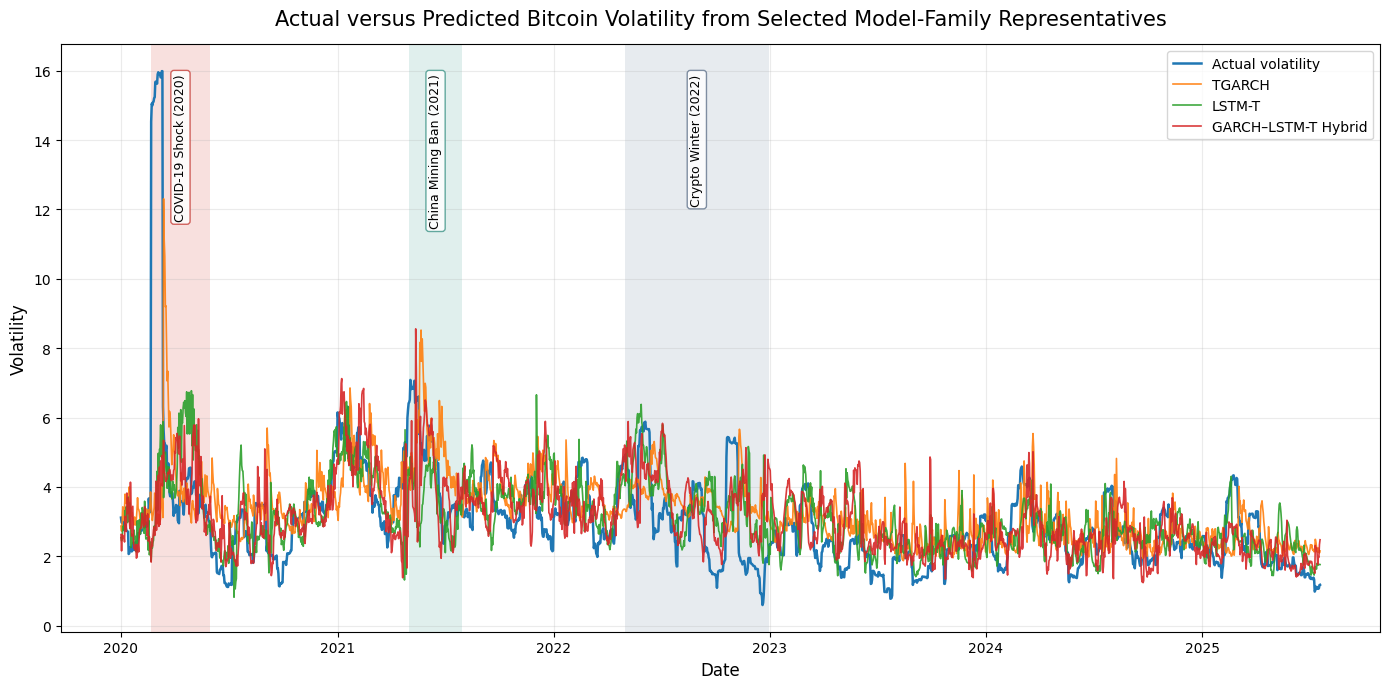

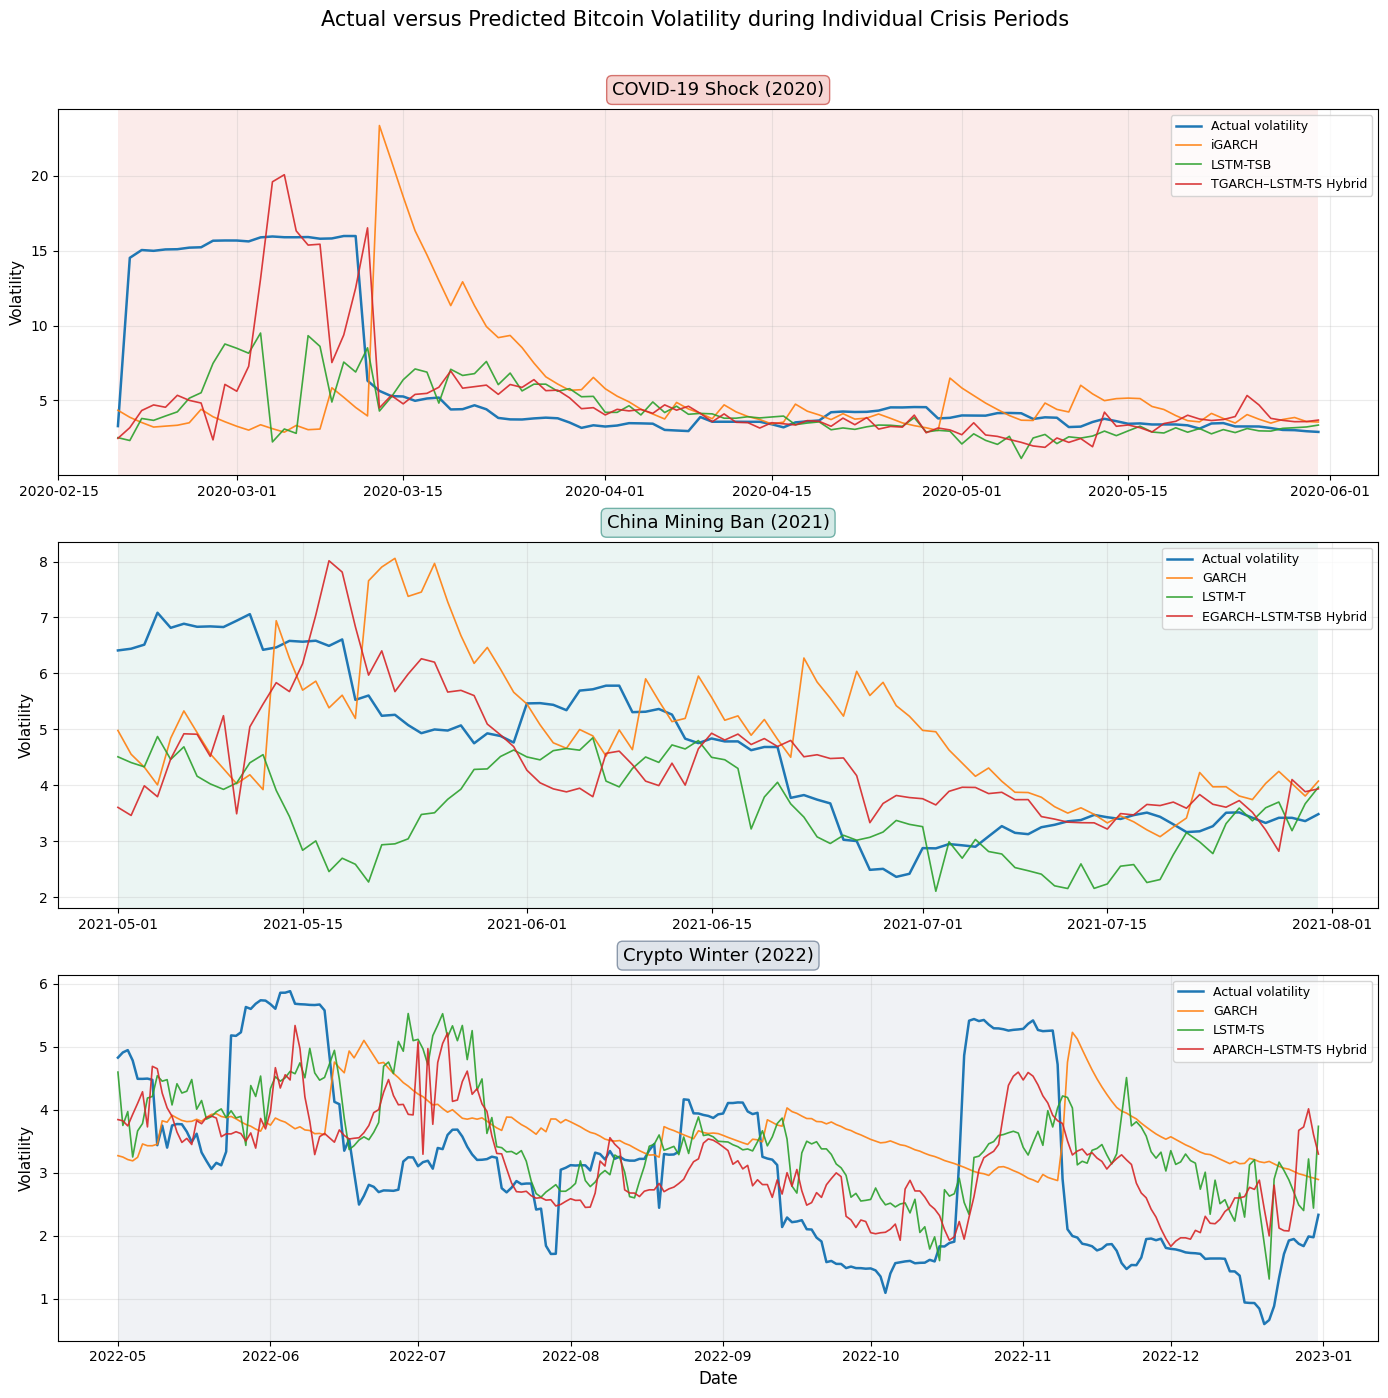

Step 10 completed successfully.

Saved figure files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Selected_Model_Family_Representatives.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Selected_Model_Family_Representatives.pdf
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Individual_Crisis_Periods.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Individual_Crisis_Periods.pdf

Saved plotted data:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Forecast_Data_Used_For_Performance_Figures.csv


In [13]:
# ============================================================
# STEP 10 — FORECAST PERFORMANCE FIGURES
# Titles and saved file names do NOT include figure numbers
# Crisis colors aligned with the descriptive volatility figure
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

FIGURES_DIR = PROJECT_DIR / "04_Figures"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"
TABLES_DIR = PROJECT_DIR / "03_Tables"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load forecasts
# ------------------------------------------------------------

traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

lstm_forecasts = pd.read_csv(
    FORECASTS_DIR / (
        "LSTM_Model_Forecasts_Daily_Rolling_"
        "Optimized_Table3.csv"
    )
)

hybrid_forecasts = pd.read_csv(
    FORECASTS_DIR / (
        "Hybrid_Model_Forecasts_Daily_Rolling_"
        "Optimized_Table4.csv"
    )
)


for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:

    frame["date"] = pd.to_datetime(
        frame["date"]
    )


# ------------------------------------------------------------
# 3. Merge forecast data
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

forecast_data = (
    traditional_forecasts[
        base_columns
        + [
            "GARCH",
            "iGARCH",
            "TGARCH"
        ]
    ]
    .merge(
        lstm_forecasts[
            base_columns
            + [
                "LSTM-T",
                "LSTM-TS",
                "LSTM-TSB"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns
            + [
                "Hybrid_GARCH_T",
                "Hybrid_TGARCH_TS",
                "Hybrid_EGARCH_TSB",
                "Hybrid_APARCH_TS"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 4. Keep common valid sample for the plotted models
# ------------------------------------------------------------

plot_model_columns = [
    "Actual_Volatility",
    "TGARCH",
    "LSTM-T",
    "Hybrid_GARCH_T",
    "iGARCH",
    "LSTM-TSB",
    "Hybrid_TGARCH_TS",
    "GARCH",
    "Hybrid_EGARCH_TSB",
    "LSTM-TS",
    "Hybrid_APARCH_TS"
]

plot_values = forecast_data[
    plot_model_columns
].to_numpy(dtype=float)

valid_plot_mask = (
    np.isfinite(plot_values).all(axis=1)
    &
    (plot_values > 0).all(axis=1)
)

forecast_data = forecast_data.loc[
    valid_plot_mask
].copy()

print("Common valid observations for Step 10 figures:", len(forecast_data))


# ------------------------------------------------------------
# 5. Crisis shading settings
# Same crisis names and colors as the descriptive volatility figure
# ------------------------------------------------------------

crisis_windows = {

    "COVID-19 Shock (2020)":
        (
            pd.Timestamp("2020-02-20"),
            pd.Timestamp("2020-05-31")
        ),

    "China Mining Ban (2021)":
        (
            pd.Timestamp("2021-05-01"),
            pd.Timestamp("2021-07-31")
        ),

    "Crypto Winter (2022)":
        (
            pd.Timestamp("2022-05-01"),
            pd.Timestamp("2022-12-31")
        )
}


# Colors aligned with the descriptive Figure 1:
# COVID-19 = light red/salmon
# China Mining Ban = light green/turquoise
# Crypto Winter = light grey-blue
crisis_colors = {

    "COVID-19 Shock (2020)":
        "#F4C7C3",

    "China Mining Ban (2021)":
        "#C7E3DF",

    "Crypto Winter (2022)":
        "#D5DCE3"
}


crisis_edge_colors = {

    "COVID-19 Shock (2020)":
        "#C94A44",

    "China Mining Ban (2021)":
        "#4A9B8F",

    "Crypto Winter (2022)":
        "#6B7C93"
}


def add_crisis_shading(axis):

    for crisis_name, (start_date, end_date) in crisis_windows.items():

        axis.axvspan(
            start_date,
            end_date,
            color=crisis_colors[crisis_name],
            alpha=0.55,
            linewidth=0
        )

        middle_date = start_date + (
            end_date - start_date
        ) / 2

        y_top = axis.get_ylim()[1]

        axis.text(
            middle_date,
            y_top * 0.95,
            crisis_name,
            ha="center",
            va="top",
            fontsize=9,
            rotation=90,
            bbox=dict(
                facecolor="white",
                edgecolor=crisis_edge_colors[crisis_name],
                boxstyle="round,pad=0.25",
                alpha=0.85
            )
        )


# ------------------------------------------------------------
# 6. Full OOS forecast comparison
# Title and file name without figure number
# ------------------------------------------------------------

full_oos_title = (
    "Actual versus Predicted Bitcoin Volatility "
    "from Selected Model-Family Representatives"
)

full_oos_file_stem = (
    "Actual_versus_Predicted_Bitcoin_Volatility_"
    "Selected_Model_Family_Representatives"
)

fig, ax = plt.subplots(
    figsize=(14, 7)
)

ax.plot(
    forecast_data["date"],
    forecast_data["Actual_Volatility"],
    label="Actual volatility",
    linewidth=1.8
)

ax.plot(
    forecast_data["date"],
    forecast_data["TGARCH"],
    label="TGARCH",
    linewidth=1.2,
    alpha=0.9
)

ax.plot(
    forecast_data["date"],
    forecast_data["LSTM-T"],
    label="LSTM-T",
    linewidth=1.2,
    alpha=0.9
)

ax.plot(
    forecast_data["date"],
    forecast_data["Hybrid_GARCH_T"],
    label="GARCH–LSTM-T Hybrid",
    linewidth=1.2,
    alpha=0.9
)

add_crisis_shading(ax)

ax.set_title(
    full_oos_title,
    fontsize=15,
    pad=14
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    "Volatility",
    fontsize=12
)

ax.legend(
    loc="upper right",
    frameon=True
)

ax.grid(
    True,
    alpha=0.25
)

fig.tight_layout()

full_oos_png = FIGURES_DIR / f"{full_oos_file_stem}.png"
full_oos_pdf = FIGURES_DIR / f"{full_oos_file_stem}.pdf"

fig.savefig(
    full_oos_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    full_oos_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Crisis-period forecast comparison
# Title and file name without figure number
# ------------------------------------------------------------

crisis_title = (
    "Actual versus Predicted Bitcoin Volatility "
    "during Individual Crisis Periods"
)

crisis_file_stem = (
    "Actual_versus_Predicted_Bitcoin_Volatility_"
    "Individual_Crisis_Periods"
)

crisis_model_map = {

    "COVID-19 Shock (2020)": {
        "Traditional": "iGARCH",
        "LSTM": "LSTM-TSB",
        "Hybrid": "Hybrid_TGARCH_TS",
        "Hybrid label": "TGARCH–LSTM-TS Hybrid"
    },

    "China Mining Ban (2021)": {
        "Traditional": "GARCH",
        "LSTM": "LSTM-T",
        "Hybrid": "Hybrid_EGARCH_TSB",
        "Hybrid label": "EGARCH–LSTM-TSB Hybrid"
    },

    "Crypto Winter (2022)": {
        "Traditional": "GARCH",
        "LSTM": "LSTM-TS",
        "Hybrid": "Hybrid_APARCH_TS",
        "Hybrid label": "APARCH–LSTM-TS Hybrid"
    }
}


fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 14),
    sharex=False
)

for axis, crisis_name in zip(
    axes,
    crisis_windows.keys()
):

    start_date, end_date = crisis_windows[
        crisis_name
    ]

    crisis_data = forecast_data.loc[
        (
            forecast_data["date"] >= start_date
        )
        &
        (
            forecast_data["date"] <= end_date
        )
    ].copy()

    model_info = crisis_model_map[
        crisis_name
    ]

    traditional_model = model_info[
        "Traditional"
    ]

    lstm_model = model_info[
        "LSTM"
    ]

    hybrid_model = model_info[
        "Hybrid"
    ]

    hybrid_label = model_info[
        "Hybrid label"
    ]

    # Same crisis color as descriptive Figure 1
    axis.axvspan(
        start_date,
        end_date,
        color=crisis_colors[crisis_name],
        alpha=0.35,
        linewidth=0
    )

    axis.plot(
        crisis_data["date"],
        crisis_data["Actual_Volatility"],
        label="Actual volatility",
        linewidth=1.8
    )

    axis.plot(
        crisis_data["date"],
        crisis_data[traditional_model],
        label=traditional_model,
        linewidth=1.2,
        alpha=0.9
    )

    axis.plot(
        crisis_data["date"],
        crisis_data[lstm_model],
        label=lstm_model,
        linewidth=1.2,
        alpha=0.9
    )

    axis.plot(
        crisis_data["date"],
        crisis_data[hybrid_model],
        label=hybrid_label,
        linewidth=1.2,
        alpha=0.9
    )

    axis.set_title(
        crisis_name,
        fontsize=13,
        pad=10,
        bbox=dict(
            facecolor=crisis_colors[crisis_name],
            edgecolor=crisis_edge_colors[crisis_name],
            boxstyle="round,pad=0.30",
            alpha=0.75
        )
    )

    axis.set_ylabel(
        "Volatility",
        fontsize=11
    )

    axis.grid(
        True,
        alpha=0.25
    )

    axis.legend(
        loc="upper right",
        frameon=True,
        fontsize=9
    )

axes[-1].set_xlabel(
    "Date",
    fontsize=12
)

fig.suptitle(
    crisis_title,
    fontsize=15,
    y=0.995
)

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.98
    ]
)

crisis_png = FIGURES_DIR / f"{crisis_file_stem}.png"
crisis_pdf = FIGURES_DIR / f"{crisis_file_stem}.pdf"

fig.savefig(
    crisis_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    crisis_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Save plotted data for transparency
# ------------------------------------------------------------

plotted_data_file = FORECASTS_DIR / (
    "Forecast_Data_Used_For_Performance_Figures.csv"
)

forecast_data.to_csv(
    plotted_data_file,
    index=False
)


# ------------------------------------------------------------
# 9. Output saved paths
# ------------------------------------------------------------

print("Step 10 completed successfully.")

print("\nSaved figure files:")
print(full_oos_png)
print(full_oos_pdf)
print(crisis_png)
print(crisis_pdf)

print("\nSaved plotted data:")
print(plotted_data_file)

Mounted at /content/drive
Common valid observations for Step 10 figures: 2021


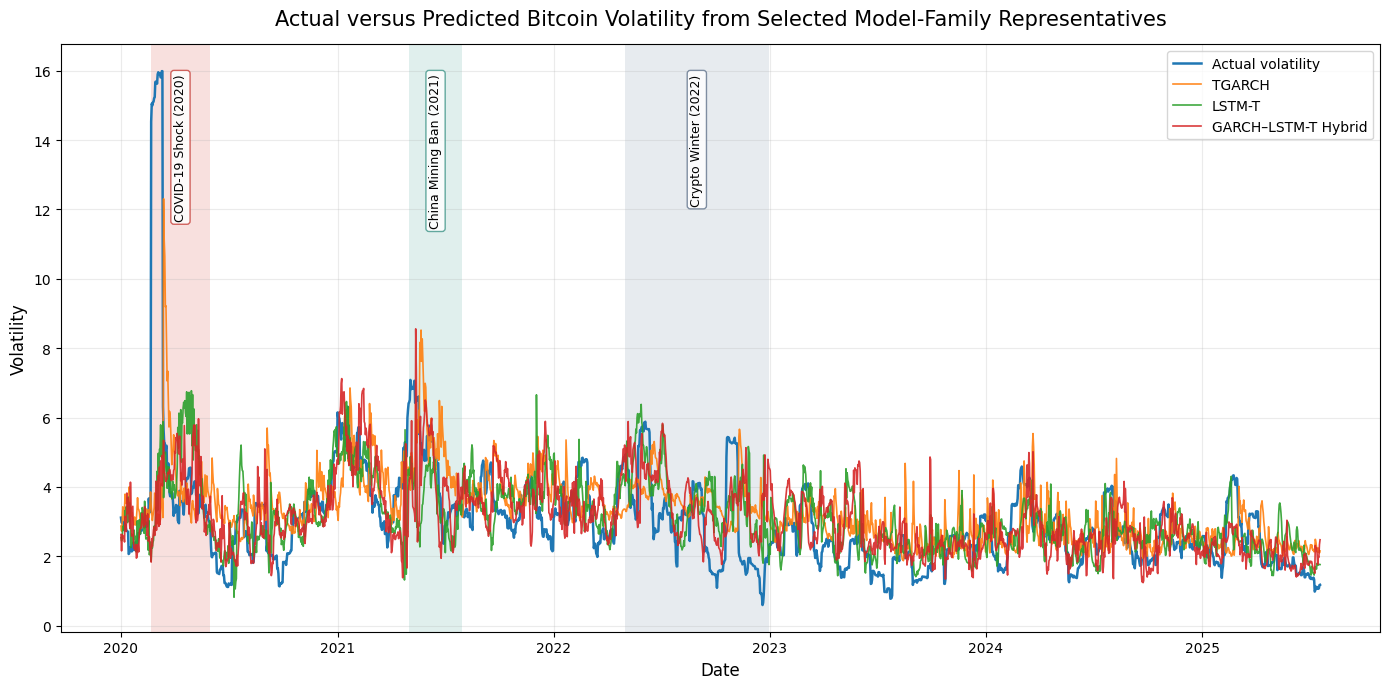

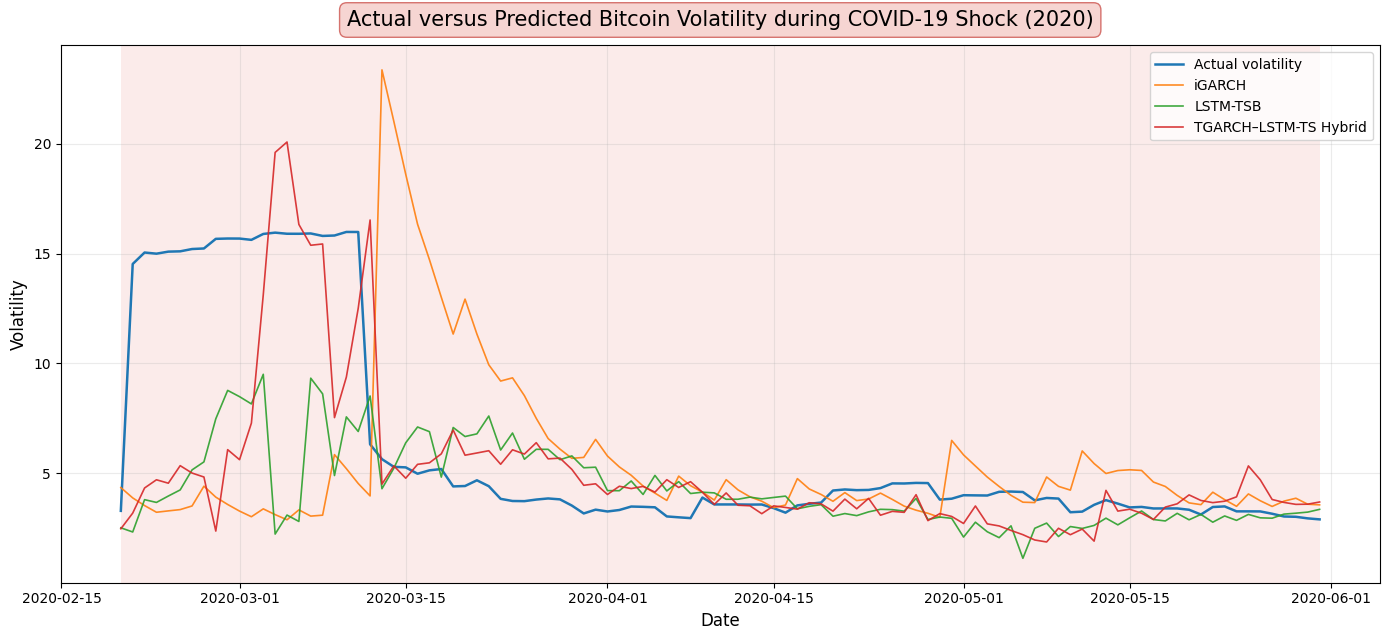

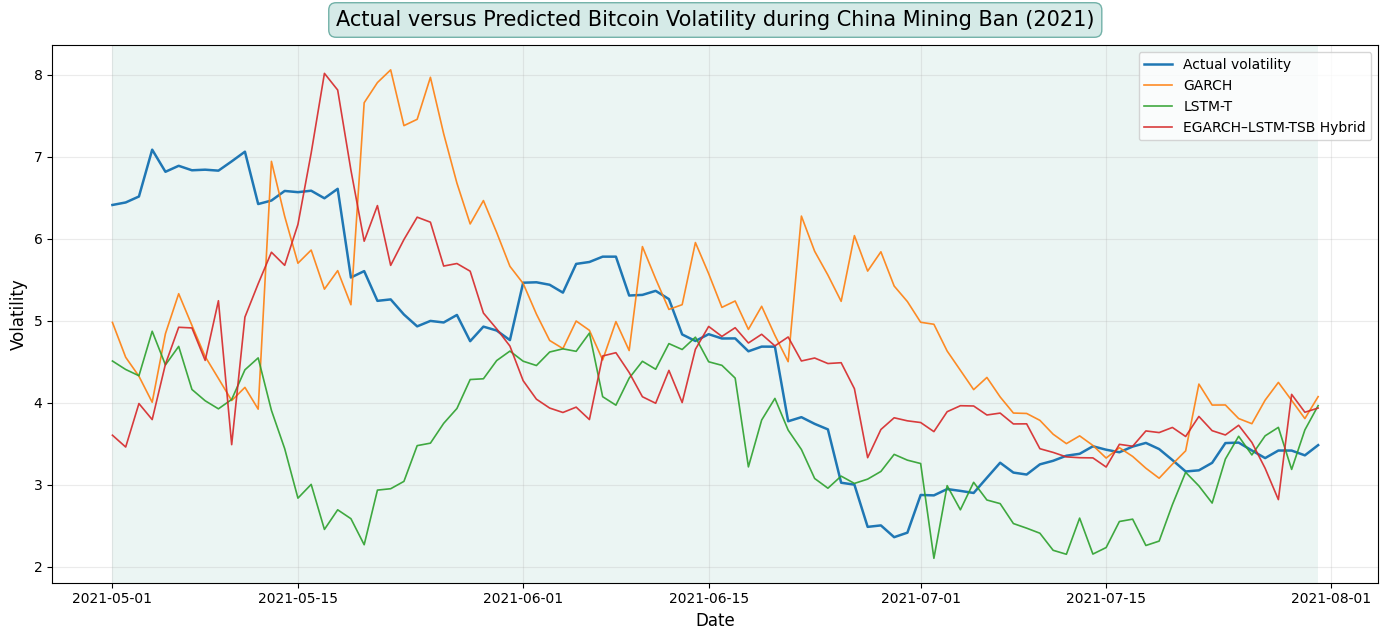

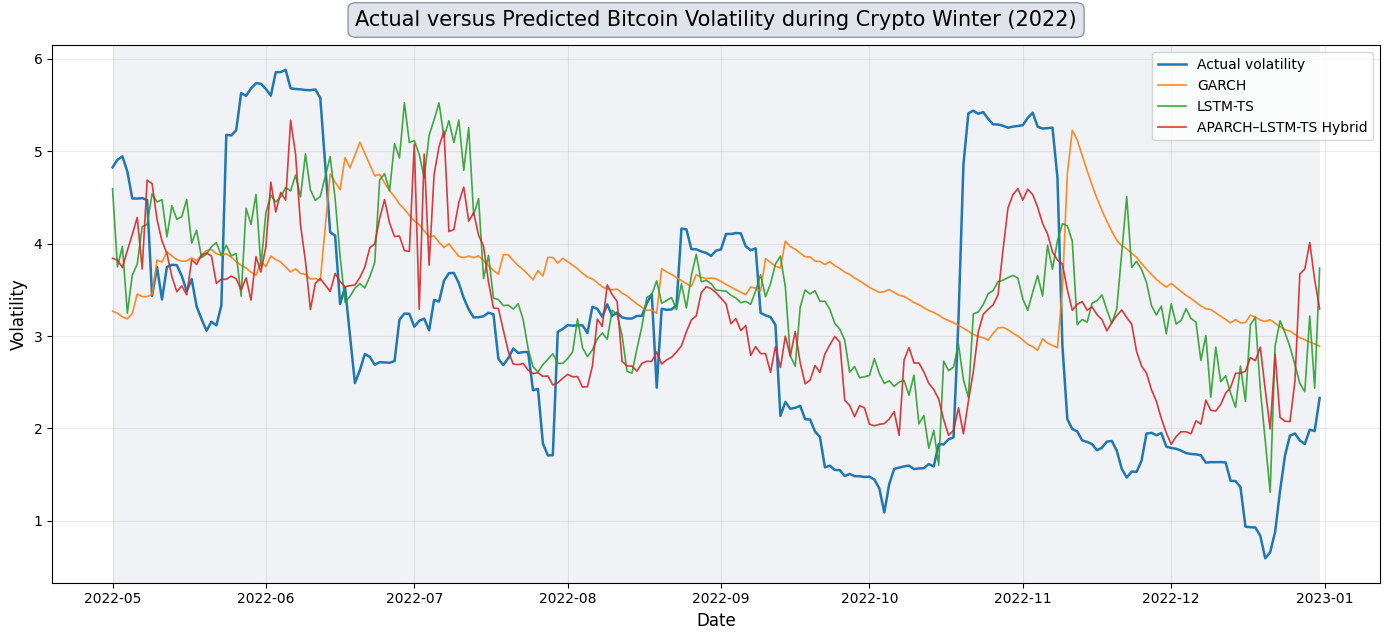

Step 10 completed successfully.

Saved full OOS figure files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Selected_Model_Family_Representatives.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_Selected_Model_Family_Representatives.pdf

Saved individual crisis figure files:

COVID-19 Shock (2020)
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_During_COVID_19_Shock_2020.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_During_COVID_19_Shock_2020.pdf

China Mining Ban (2021)
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_During_China_Mining_Ban_2021.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Actual_versus_Predicted_Bitcoin_Volatility_During_China_Mining_Ban_2021.pdf

Crypto W

In [1]:
# ============================================================
# STEP 10 — FORECAST PERFORMANCE FIGURES
# Titles and saved file names do NOT include figure numbers
# Crisis figures are saved separately by crisis period
# ============================================================

# ------------------------------------------------------------
# 0. Connect Google Drive
# ------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. Imports and paths
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

FIGURES_DIR = PROJECT_DIR / "04_Figures"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"
TABLES_DIR = PROJECT_DIR / "03_Tables"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load forecasts
# ------------------------------------------------------------

traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

lstm_forecasts = pd.read_csv(
    FORECASTS_DIR / (
        "LSTM_Model_Forecasts_Daily_Rolling_"
        "Optimized_Table3.csv"
    )
)

hybrid_forecasts = pd.read_csv(
    FORECASTS_DIR / (
        "Hybrid_Model_Forecasts_Daily_Rolling_"
        "Optimized_Table4.csv"
    )
)


for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:

    frame["date"] = pd.to_datetime(
        frame["date"]
    )


# ------------------------------------------------------------
# 3. Merge forecast data
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

forecast_data = (
    traditional_forecasts[
        base_columns
        + [
            "GARCH",
            "iGARCH",
            "TGARCH"
        ]
    ]
    .merge(
        lstm_forecasts[
            base_columns
            + [
                "LSTM-T",
                "LSTM-TS",
                "LSTM-TSB"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns
            + [
                "Hybrid_GARCH_T",
                "Hybrid_TGARCH_TS",
                "Hybrid_EGARCH_TSB",
                "Hybrid_APARCH_TS"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# 4. Keep common valid sample for plotted models
# ------------------------------------------------------------

plot_model_columns = [
    "Actual_Volatility",
    "TGARCH",
    "LSTM-T",
    "Hybrid_GARCH_T",
    "iGARCH",
    "LSTM-TSB",
    "Hybrid_TGARCH_TS",
    "GARCH",
    "Hybrid_EGARCH_TSB",
    "LSTM-TS",
    "Hybrid_APARCH_TS"
]

plot_values = forecast_data[
    plot_model_columns
].to_numpy(dtype=float)

valid_plot_mask = (
    np.isfinite(plot_values).all(axis=1)
    &
    (plot_values > 0).all(axis=1)
)

forecast_data = forecast_data.loc[
    valid_plot_mask
].copy()

print("Common valid observations for Step 10 figures:", len(forecast_data))


# ------------------------------------------------------------
# 5. Crisis settings
# Same names and colors as the descriptive volatility figure
# ------------------------------------------------------------

crisis_windows = {

    "COVID-19 Shock (2020)":
        (
            pd.Timestamp("2020-02-20"),
            pd.Timestamp("2020-05-31")
        ),

    "China Mining Ban (2021)":
        (
            pd.Timestamp("2021-05-01"),
            pd.Timestamp("2021-07-31")
        ),

    "Crypto Winter (2022)":
        (
            pd.Timestamp("2022-05-01"),
            pd.Timestamp("2022-12-31")
        )
}


crisis_colors = {

    "COVID-19 Shock (2020)":
        "#F4C7C3",

    "China Mining Ban (2021)":
        "#C7E3DF",

    "Crypto Winter (2022)":
        "#D5DCE3"
}


crisis_edge_colors = {

    "COVID-19 Shock (2020)":
        "#C94A44",

    "China Mining Ban (2021)":
        "#4A9B8F",

    "Crypto Winter (2022)":
        "#6B7C93"
}


def add_crisis_shading(axis):

    for crisis_name, (start_date, end_date) in crisis_windows.items():

        axis.axvspan(
            start_date,
            end_date,
            color=crisis_colors[crisis_name],
            alpha=0.55,
            linewidth=0
        )

        middle_date = start_date + (
            end_date - start_date
        ) / 2

        y_top = axis.get_ylim()[1]

        axis.text(
            middle_date,
            y_top * 0.95,
            crisis_name,
            ha="center",
            va="top",
            fontsize=9,
            rotation=90,
            bbox=dict(
                facecolor="white",
                edgecolor=crisis_edge_colors[crisis_name],
                boxstyle="round,pad=0.25",
                alpha=0.85
            )
        )


# ------------------------------------------------------------
# 6. Full OOS forecast comparison
# ------------------------------------------------------------

full_oos_title = (
    "Actual versus Predicted Bitcoin Volatility "
    "from Selected Model-Family Representatives"
)

full_oos_file_stem = (
    "Actual_versus_Predicted_Bitcoin_Volatility_"
    "Selected_Model_Family_Representatives"
)

fig, ax = plt.subplots(
    figsize=(14, 7)
)

ax.plot(
    forecast_data["date"],
    forecast_data["Actual_Volatility"],
    label="Actual volatility",
    linewidth=1.8
)

ax.plot(
    forecast_data["date"],
    forecast_data["TGARCH"],
    label="TGARCH",
    linewidth=1.2,
    alpha=0.9
)

ax.plot(
    forecast_data["date"],
    forecast_data["LSTM-T"],
    label="LSTM-T",
    linewidth=1.2,
    alpha=0.9
)

ax.plot(
    forecast_data["date"],
    forecast_data["Hybrid_GARCH_T"],
    label="GARCH–LSTM-T Hybrid",
    linewidth=1.2,
    alpha=0.9
)

add_crisis_shading(ax)

ax.set_title(
    full_oos_title,
    fontsize=15,
    pad=14
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    "Volatility",
    fontsize=12
)

ax.legend(
    loc="upper right",
    frameon=True
)

ax.grid(
    True,
    alpha=0.25
)

fig.tight_layout()

full_oos_png = FIGURES_DIR / f"{full_oos_file_stem}.png"
full_oos_pdf = FIGURES_DIR / f"{full_oos_file_stem}.pdf"

fig.savefig(
    full_oos_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    full_oos_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Individual crisis forecast comparison figures
# ------------------------------------------------------------

crisis_model_map = {

    "COVID-19 Shock (2020)": {
        "Traditional": "iGARCH",
        "LSTM": "LSTM-TSB",
        "Hybrid": "Hybrid_TGARCH_TS",
        "Hybrid label": "TGARCH–LSTM-TS Hybrid",
        "File stem": (
            "Actual_versus_Predicted_Bitcoin_Volatility_"
            "During_COVID_19_Shock_2020"
        )
    },

    "China Mining Ban (2021)": {
        "Traditional": "GARCH",
        "LSTM": "LSTM-T",
        "Hybrid": "Hybrid_EGARCH_TSB",
        "Hybrid label": "EGARCH–LSTM-TSB Hybrid",
        "File stem": (
            "Actual_versus_Predicted_Bitcoin_Volatility_"
            "During_China_Mining_Ban_2021"
        )
    },

    "Crypto Winter (2022)": {
        "Traditional": "GARCH",
        "LSTM": "LSTM-TS",
        "Hybrid": "Hybrid_APARCH_TS",
        "Hybrid label": "APARCH–LSTM-TS Hybrid",
        "File stem": (
            "Actual_versus_Predicted_Bitcoin_Volatility_"
            "During_Crypto_Winter_2022"
        )
    }
}


individual_crisis_paths = []

for crisis_name, (start_date, end_date) in crisis_windows.items():

    crisis_data = forecast_data.loc[
        (
            forecast_data["date"] >= start_date
        )
        &
        (
            forecast_data["date"] <= end_date
        )
    ].copy()

    model_info = crisis_model_map[
        crisis_name
    ]

    traditional_model = model_info[
        "Traditional"
    ]

    lstm_model = model_info[
        "LSTM"
    ]

    hybrid_model = model_info[
        "Hybrid"
    ]

    hybrid_label = model_info[
        "Hybrid label"
    ]

    crisis_file_stem = model_info[
        "File stem"
    ]

    crisis_title = (
        "Actual versus Predicted Bitcoin Volatility "
        "during "
        + crisis_name
    )

    fig, ax = plt.subplots(
        figsize=(14, 6.5)
    )

    ax.axvspan(
        start_date,
        end_date,
        color=crisis_colors[crisis_name],
        alpha=0.35,
        linewidth=0
    )

    ax.plot(
        crisis_data["date"],
        crisis_data["Actual_Volatility"],
        label="Actual volatility",
        linewidth=1.8
    )

    ax.plot(
        crisis_data["date"],
        crisis_data[traditional_model],
        label=traditional_model,
        linewidth=1.2,
        alpha=0.9
    )

    ax.plot(
        crisis_data["date"],
        crisis_data[lstm_model],
        label=lstm_model,
        linewidth=1.2,
        alpha=0.9
    )

    ax.plot(
        crisis_data["date"],
        crisis_data[hybrid_model],
        label=hybrid_label,
        linewidth=1.2,
        alpha=0.9
    )

    ax.set_title(
        crisis_title,
        fontsize=15,
        pad=14,
        bbox=dict(
            facecolor=crisis_colors[crisis_name],
            edgecolor=crisis_edge_colors[crisis_name],
            boxstyle="round,pad=0.35",
            alpha=0.75
        )
    )

    ax.set_xlabel(
        "Date",
        fontsize=12
    )

    ax.set_ylabel(
        "Volatility",
        fontsize=12
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        loc="upper right",
        frameon=True,
        fontsize=10
    )

    fig.tight_layout()

    crisis_png = FIGURES_DIR / f"{crisis_file_stem}.png"
    crisis_pdf = FIGURES_DIR / f"{crisis_file_stem}.pdf"

    fig.savefig(
        crisis_png,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        crisis_pdf,
        bbox_inches="tight"
    )

    individual_crisis_paths.append(
        (crisis_name, crisis_png, crisis_pdf)
    )

    plt.show()


# ------------------------------------------------------------
# 8. Save plotted data for transparency
# ------------------------------------------------------------

plotted_data_file = FORECASTS_DIR / (
    "Forecast_Data_Used_For_Performance_Figures.csv"
)

forecast_data.to_csv(
    plotted_data_file,
    index=False
)


for crisis_name, (start_date, end_date) in crisis_windows.items():

    crisis_file_name = (
        "Forecast_Data_Used_For_"
        + crisis_model_map[crisis_name]["File stem"]
        + ".csv"
    )

    crisis_data_file = FORECASTS_DIR / crisis_file_name

    crisis_data = forecast_data.loc[
        (
            forecast_data["date"] >= start_date
        )
        &
        (
            forecast_data["date"] <= end_date
        )
    ].copy()

    crisis_data.to_csv(
        crisis_data_file,
        index=False
    )


# ------------------------------------------------------------
# 9. Output saved paths
# ------------------------------------------------------------

print("Step 10 completed successfully.")

print("\nSaved full OOS figure files:")
print(full_oos_png)
print(full_oos_pdf)

print("\nSaved individual crisis figure files:")

for crisis_name, png_path, pdf_path in individual_crisis_paths:
    print("\n" + crisis_name)
    print(png_path)
    print(pdf_path)

print("\nSaved plotted data:")
print(plotted_data_file)

Common valid observations used for rolling-loss figures: 2021
Forecast sample: 2020-01-01 to 2025-07-19


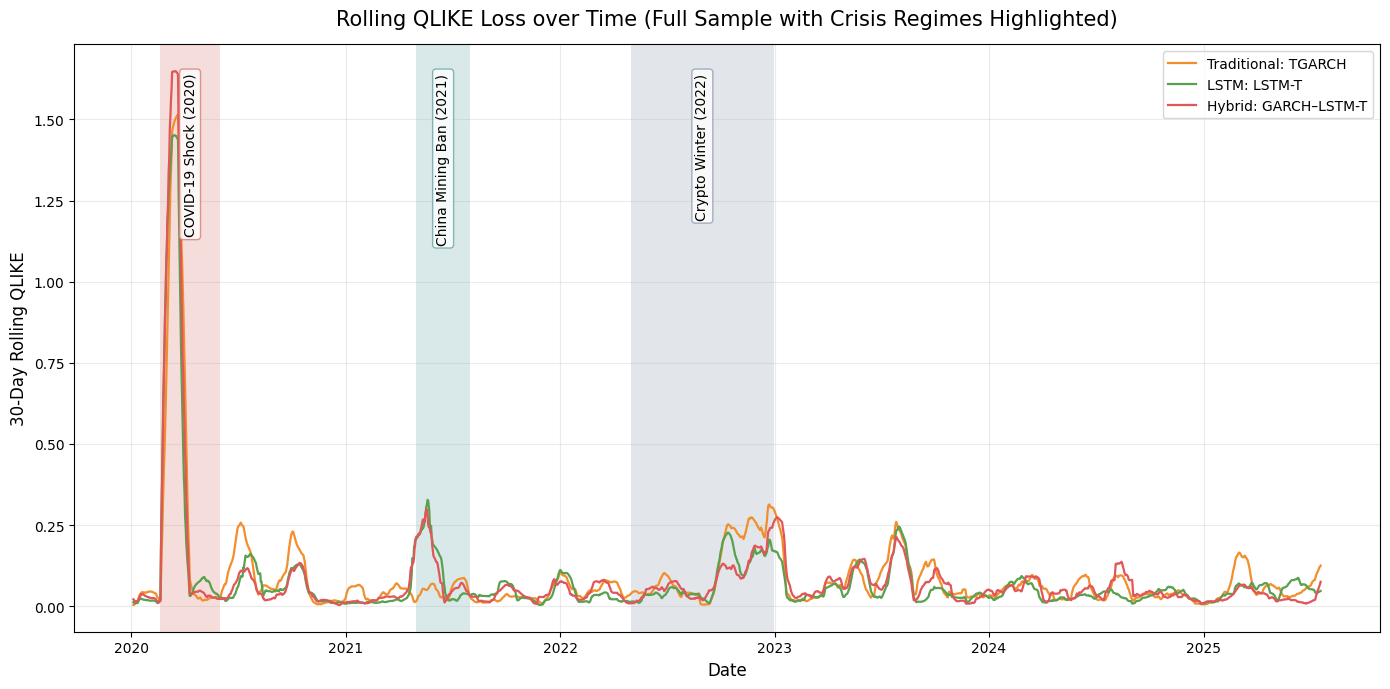


Crisis windows available for Figure 7: ['COVID-19 Shock (2020)', 'China Mining Ban (2021)', 'Crypto Winter (2022)']
Skipped crisis windows outside forecast sample: ['Post-Bubble Crash (2018)']


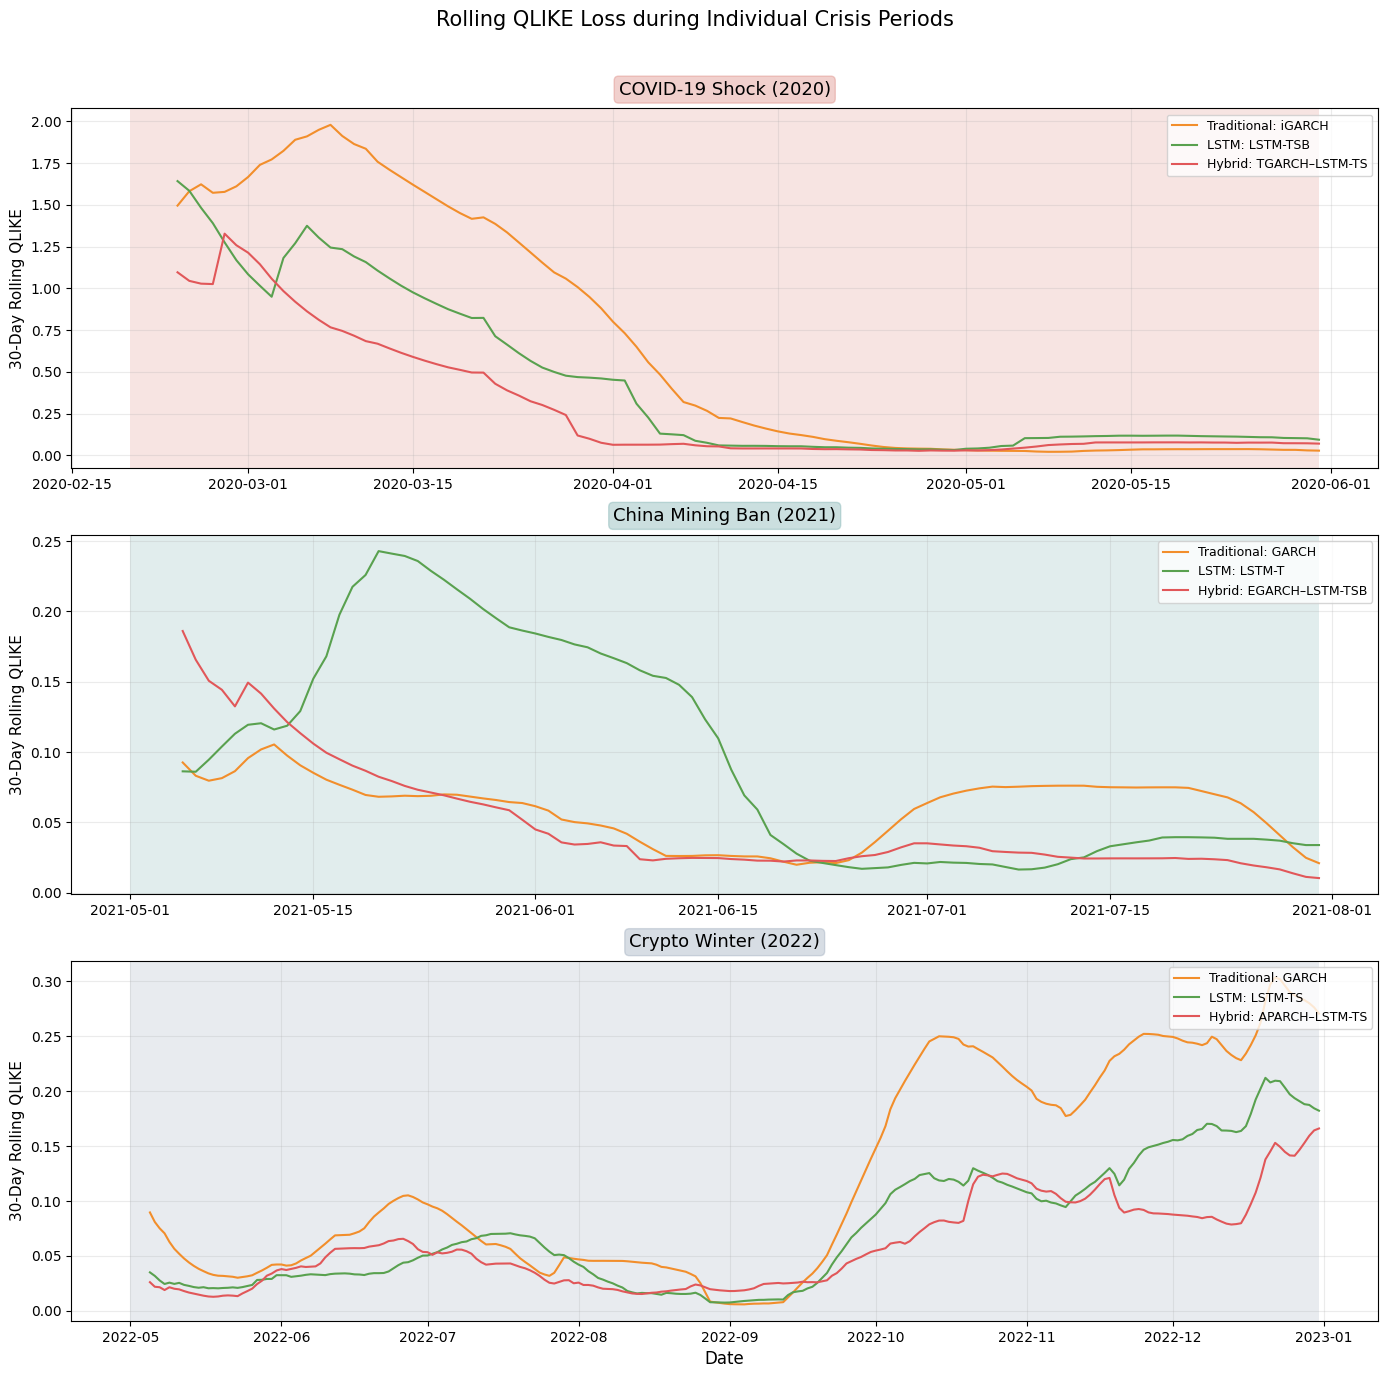


Step 11 completed successfully.

Saved figure files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_Over_Time_Full_Sample_Crisis_Regimes_Highlighted.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_Over_Time_Full_Sample_Crisis_Regimes_Highlighted.pdf
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_Individual_Crisis_Periods.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_Individual_Crisis_Periods.pdf

Saved rolling-loss data:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/06_Forecasts/Rolling_QLIKE_Data_Used_For_Figures_6_7.csv


In [14]:
# ============================================================
# STEP 11 — ROLLING QLIKE LOSS FIGURES
# Titles and saved file names do NOT include figure numbers
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

FIGURES_DIR = PROJECT_DIR / "04_Figures"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load forecast files
# ------------------------------------------------------------

traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

lstm_forecasts = pd.read_csv(
    FORECASTS_DIR / "LSTM_Model_Forecasts_Daily_Rolling_Optimized_Table3.csv"
)

hybrid_forecasts = pd.read_csv(
    FORECASTS_DIR / "Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv"
)


for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:
    frame["date"] = pd.to_datetime(frame["date"])


# ------------------------------------------------------------
# 3. Merge forecast data
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

forecast_data = (
    traditional_forecasts[
        base_columns
        + [
            "GARCH",
            "iGARCH",
            "TGARCH",
            "GJR-GARCH",
            "APARCH",
            "EGARCH"
        ]
    ]
    .merge(
        lstm_forecasts[
            base_columns
            + [
                "LSTM-T",
                "LSTM-TS",
                "LSTM-TSB"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns
            + [
                "Hybrid_GARCH_T",
                "Hybrid_TGARCH_TS",
                "Hybrid_EGARCH_TSB",
                "Hybrid_APARCH_TS"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .sort_values("date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Crisis windows and colors
# ------------------------------------------------------------

crisis_windows = {
    "Post-Bubble Crash (2018)": (
        pd.Timestamp("2018-02-01"),
        pd.Timestamp("2018-12-31")
    ),
    "COVID-19 Shock (2020)": (
        pd.Timestamp("2020-02-20"),
        pd.Timestamp("2020-05-31")
    ),
    "China Mining Ban (2021)": (
        pd.Timestamp("2021-05-01"),
        pd.Timestamp("2021-07-31")
    ),
    "Crypto Winter (2022)": (
        pd.Timestamp("2022-05-01"),
        pd.Timestamp("2022-12-31")
    )
}

crisis_colors = {
    "Post-Bubble Crash (2018)": "#d8b38a",   # beige
    "COVID-19 Shock (2020)": "#d97b72",      # soft red
    "China Mining Ban (2021)": "#6ba6a6",    # soft teal
    "Crypto Winter (2022)": "#8f9fb3"        # blue-grey
}


# ------------------------------------------------------------
# 5. Selected model sets
# ------------------------------------------------------------

# Figure 6: family representatives / best models from normal period
figure6_models = {
    "TGARCH": "Traditional: TGARCH",
    "LSTM-T": "LSTM: LSTM-T",
    "Hybrid_GARCH_T": "Hybrid: GARCH–LSTM-T"
}

# Figure 7: best model from each family within each crisis regime
figure7_models = {
    "Post-Bubble Crash (2018)": {
        "Traditional": ("TGARCH", "Traditional: TGARCH"),
        "LSTM": ("LSTM-T", "LSTM: LSTM-T"),
        "Hybrid": ("Hybrid_GARCH_T", "Hybrid: GARCH–LSTM-T")
    },
    "COVID-19 Shock (2020)": {
        "Traditional": ("iGARCH", "Traditional: iGARCH"),
        "LSTM": ("LSTM-TSB", "LSTM: LSTM-TSB"),
        "Hybrid": ("Hybrid_TGARCH_TS", "Hybrid: TGARCH–LSTM-TS")
    },
    "China Mining Ban (2021)": {
        "Traditional": ("GARCH", "Traditional: GARCH"),
        "LSTM": ("LSTM-T", "LSTM: LSTM-T"),
        "Hybrid": ("Hybrid_EGARCH_TSB", "Hybrid: EGARCH–LSTM-TSB")
    },
    "Crypto Winter (2022)": {
        "Traditional": ("GARCH", "Traditional: GARCH"),
        "LSTM": ("LSTM-TS", "LSTM: LSTM-TS"),
        "Hybrid": ("Hybrid_APARCH_TS", "Hybrid: APARCH–LSTM-TS")
    }
}


# ------------------------------------------------------------
# 6. Keep common valid sample
# ------------------------------------------------------------

all_needed_models = sorted(
    set(figure6_models.keys())
    |
    {
        model_name
        for crisis_info in figure7_models.values()
        for model_name, _ in crisis_info.values()
    }
)

required_columns = ["Actual_Volatility"] + all_needed_models

valid_values = forecast_data[required_columns].to_numpy(dtype=float)

valid_mask = (
    np.isfinite(valid_values).all(axis=1)
    &
    (valid_values > 0).all(axis=1)
)

forecast_data = forecast_data.loc[valid_mask].copy()

print("Common valid observations used for rolling-loss figures:", len(forecast_data))
print(
    "Forecast sample:",
    forecast_data["date"].min().date(),
    "to",
    forecast_data["date"].max().date()
)


# ------------------------------------------------------------
# 7. QLIKE function and rolling settings
# ------------------------------------------------------------

ROLLING_LOSS_WINDOW = 30
MIN_PERIODS = 5
EPSILON = 1e-10

def qlike_loss(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    actual = np.maximum(actual, EPSILON)
    forecast = np.maximum(forecast, EPSILON)
    ratio = actual / forecast
    return ratio - np.log(ratio) - 1.0


# ------------------------------------------------------------
# 8. Compute daily QLIKE loss for all relevant models
# ------------------------------------------------------------

for model_name in all_needed_models:
    forecast_data[f"{model_name}_QLIKE"] = qlike_loss(
        forecast_data["Actual_Volatility"],
        forecast_data[model_name]
    )


# ------------------------------------------------------------
# 9. Helper functions for crisis shading and labels
# ------------------------------------------------------------

def add_crisis_shading_full_sample(axis, sample_start, sample_end):
    for crisis_name, (start_date, end_date) in crisis_windows.items():

        if end_date < sample_start or start_date > sample_end:
            continue

        shade_start = max(start_date, sample_start)
        shade_end = min(end_date, sample_end)

        axis.axvspan(
            shade_start,
            shade_end,
            color=crisis_colors[crisis_name],
            alpha=0.25,
            linewidth=0
        )

        middle_date = shade_start + (shade_end - shade_start) / 2
        y_top = axis.get_ylim()[1]

        axis.text(
            middle_date,
            y_top * 0.95,
            crisis_name,
            ha="center",
            va="top",
            fontsize=10,
            rotation=90,
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor=crisis_colors[crisis_name],
                alpha=0.80
            )
        )


def style_single_crisis_panel(axis, crisis_name, start_date, end_date):
    axis.axvspan(
        start_date,
        end_date,
        color=crisis_colors[crisis_name],
        alpha=0.20,
        linewidth=0
    )

    axis.set_title(
        crisis_name,
        fontsize=13,
        pad=10,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor=crisis_colors[crisis_name],
            edgecolor=crisis_colors[crisis_name],
            alpha=0.35
        )
    )


# ------------------------------------------------------------
# 10. Figure 6 — Rolling QLIKE over the full sample
# ------------------------------------------------------------

figure6_title = (
    "Rolling QLIKE Loss over Time "
    "(Full Sample with Crisis Regimes Highlighted)"
)

figure6_file_stem = (
    "Rolling_QLIKE_Loss_Over_Time_Full_Sample_"
    "Crisis_Regimes_Highlighted"
)

figure6_data = forecast_data[["date"]].copy()

for model_name in figure6_models:
    figure6_data[f"{model_name}_Rolling_QLIKE"] = (
        forecast_data[f"{model_name}_QLIKE"]
        .rolling(
            window=ROLLING_LOSS_WINDOW,
            min_periods=MIN_PERIODS
        )
        .mean()
    )

fig, ax = plt.subplots(figsize=(14, 7))

line_colors = {
    "TGARCH": "#f28e2b",          # orange
    "LSTM-T": "#59a14f",          # green
    "Hybrid_GARCH_T": "#e15759"  # red
}

for model_name, label in figure6_models.items():
    ax.plot(
        figure6_data["date"],
        figure6_data[f"{model_name}_Rolling_QLIKE"],
        label=label,
        linewidth=1.6,
        color=line_colors[model_name]
    )

ax.set_title(
    figure6_title,
    fontsize=15,
    pad=14
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    f"{ROLLING_LOSS_WINDOW}-Day Rolling QLIKE",
    fontsize=12
)

ax.grid(
    True,
    alpha=0.25
)

sample_start = figure6_data["date"].min()
sample_end = figure6_data["date"].max()

add_crisis_shading_full_sample(
    ax,
    sample_start,
    sample_end
)

ax.legend(
    loc="upper right",
    frameon=True
)

fig.tight_layout()

figure6_png = FIGURES_DIR / f"{figure6_file_stem}.png"
figure6_pdf = FIGURES_DIR / f"{figure6_file_stem}.pdf"

fig.savefig(
    figure6_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure6_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Figure 7 — Rolling QLIKE during individual crisis periods
# ------------------------------------------------------------

figure7_title = "Rolling QLIKE Loss during Individual Crisis Periods"

figure7_file_stem = "Rolling_QLIKE_Loss_During_Individual_Crisis_Periods"

# Keep only crisis windows that overlap with forecast sample
available_crises = []
skipped_crises = []

for crisis_name, (start_date, end_date) in crisis_windows.items():
    crisis_mask = (
        (forecast_data["date"] >= start_date)
        &
        (forecast_data["date"] <= end_date)
    )

    if crisis_mask.sum() > 0:
        available_crises.append(crisis_name)
    else:
        skipped_crises.append(crisis_name)

print("\nCrisis windows available for Figure 7:", available_crises)
if skipped_crises:
    print("Skipped crisis windows outside forecast sample:", skipped_crises)

fig, axes = plt.subplots(
    nrows=len(available_crises),
    ncols=1,
    figsize=(14, 4.6 * len(available_crises)),
    sharex=False
)

if len(available_crises) == 1:
    axes = [axes]

for axis, crisis_name in zip(axes, available_crises):

    start_date, end_date = crisis_windows[crisis_name]

    crisis_slice = forecast_data.loc[
        (
            forecast_data["date"] >= start_date
        )
        &
        (
            forecast_data["date"] <= end_date
        )
    ].copy()

    crisis_info = figure7_models[crisis_name]

    model_triplet = [
        crisis_info["Traditional"],
        crisis_info["LSTM"],
        crisis_info["Hybrid"]
    ]

    crisis_line_colors = {
        "Traditional": "#f28e2b",
        "LSTM": "#59a14f",
        "Hybrid": "#e15759"
    }

    for family_name, (model_name, label) in zip(
        ["Traditional", "LSTM", "Hybrid"],
        model_triplet
    ):

        crisis_slice[f"{model_name}_Rolling_QLIKE"] = (
            crisis_slice[f"{model_name}_QLIKE"]
            .rolling(
                window=ROLLING_LOSS_WINDOW,
                min_periods=MIN_PERIODS
            )
            .mean()
        )

        axis.plot(
            crisis_slice["date"],
            crisis_slice[f"{model_name}_Rolling_QLIKE"],
            label=label,
            linewidth=1.5,
            color=crisis_line_colors[family_name]
        )

    style_single_crisis_panel(
        axis,
        crisis_name,
        start_date,
        end_date
    )

    axis.set_ylabel(
        f"{ROLLING_LOSS_WINDOW}-Day Rolling QLIKE",
        fontsize=11
    )

    axis.grid(
        True,
        alpha=0.25
    )

    axis.legend(
        loc="upper right",
        frameon=True,
        fontsize=9
    )

axes[-1].set_xlabel(
    "Date",
    fontsize=12
)

fig.suptitle(
    figure7_title,
    fontsize=15,
    y=0.995
)

fig.tight_layout(
    rect=[0, 0, 1, 0.98]
)

figure7_png = FIGURES_DIR / f"{figure7_file_stem}.png"
figure7_pdf = FIGURES_DIR / f"{figure7_file_stem}.pdf"

fig.savefig(
    figure7_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure7_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 12. Save rolling-loss data for transparency
# ------------------------------------------------------------

rolling_loss_data_file = FORECASTS_DIR / "Rolling_QLIKE_Data_Used_For_Figures_6_7.csv"

rolling_output = forecast_data.copy()

for model_name in all_needed_models:
    rolling_output[f"{model_name}_Rolling_QLIKE_30"] = (
        rolling_output[f"{model_name}_QLIKE"]
        .rolling(
            window=ROLLING_LOSS_WINDOW,
            min_periods=MIN_PERIODS
        )
        .mean()
    )

rolling_output.to_csv(
    rolling_loss_data_file,
    index=False
)


# ------------------------------------------------------------
# 13. Output saved paths
# ------------------------------------------------------------

print("\nStep 11 completed successfully.")
print("\nSaved figure files:")
print(figure6_png)
print(figure6_pdf)
print(figure7_png)
print(figure7_pdf)

print("\nSaved rolling-loss data:")
print(rolling_loss_data_file)

Common valid observations used for rolling-loss figures: 2021
Forecast sample: 2020-01-01 to 2025-07-19


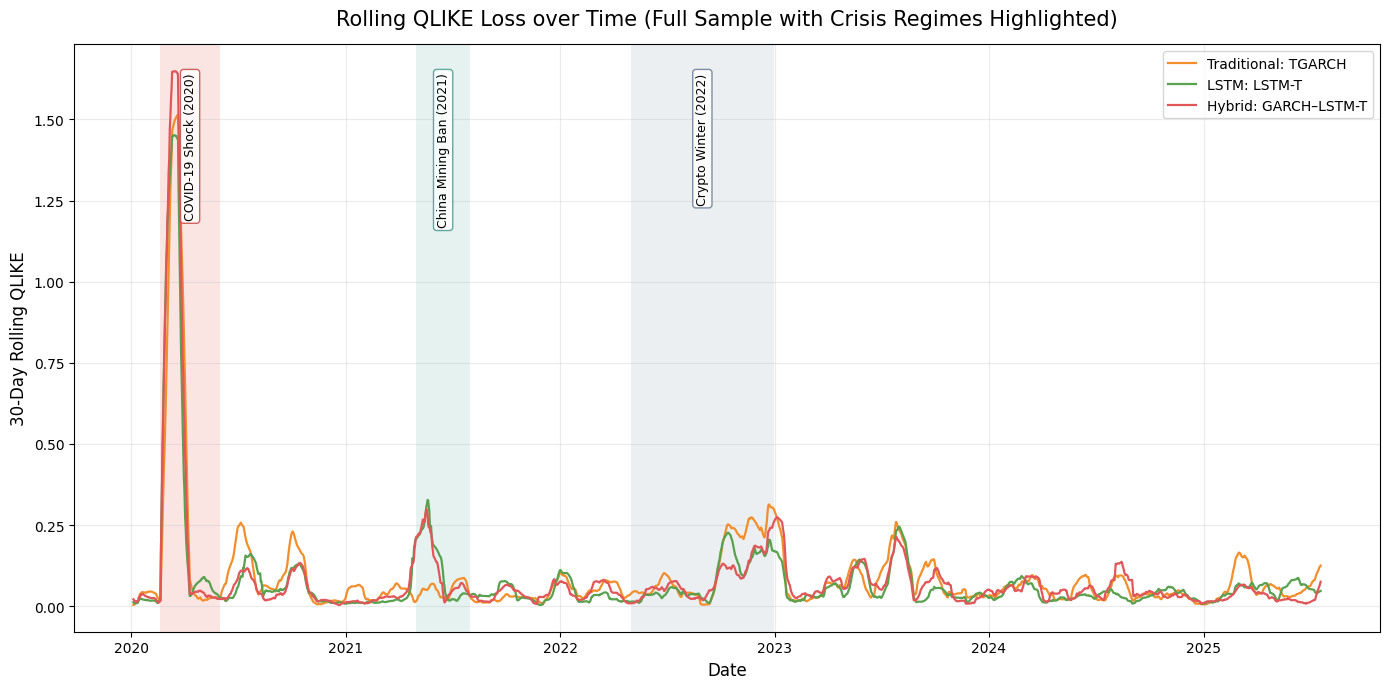


Crisis windows available for individual rolling QLIKE figures:
['COVID-19 Shock (2020)', 'China Mining Ban (2021)', 'Crypto Winter (2022)']

Skipped crisis windows outside forecast sample:
['Post-Bubble Crash (2018)']


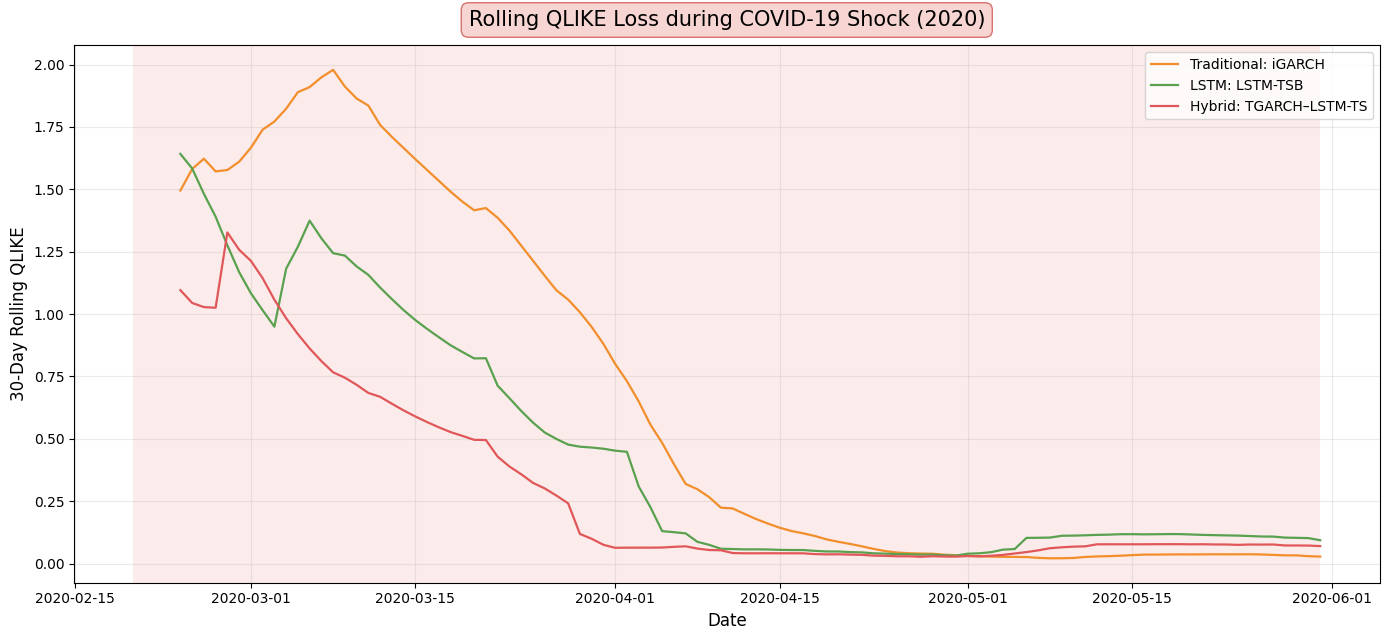

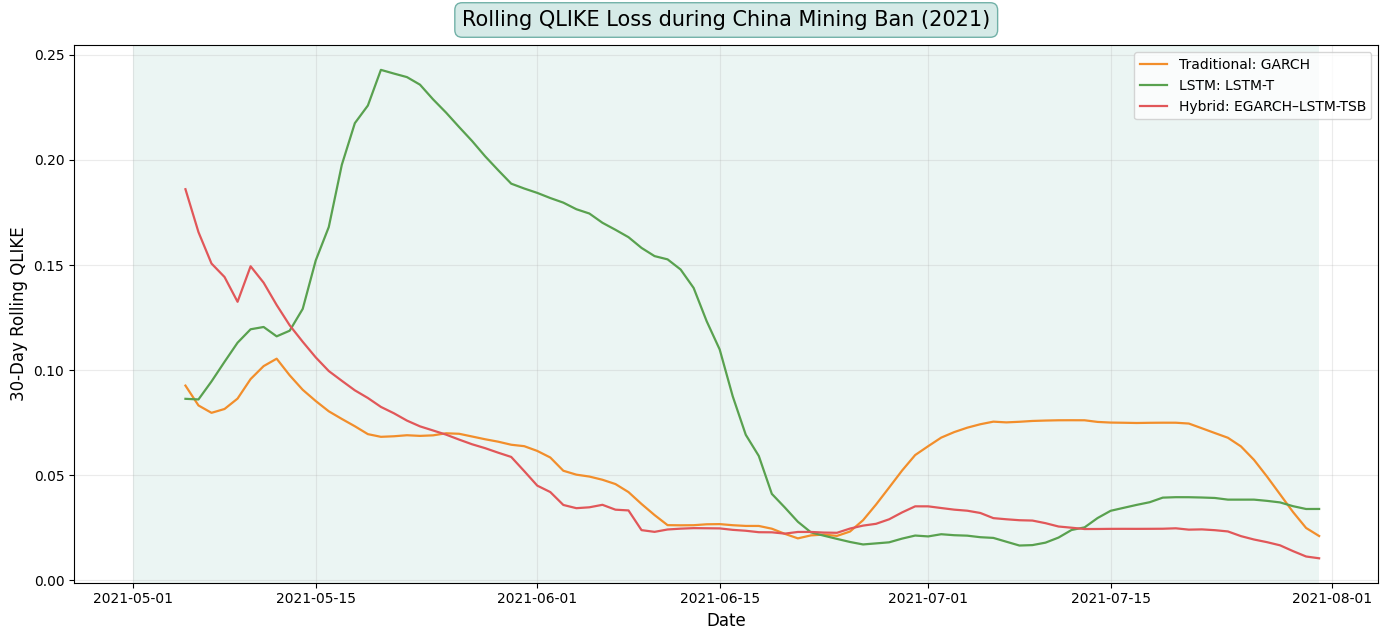

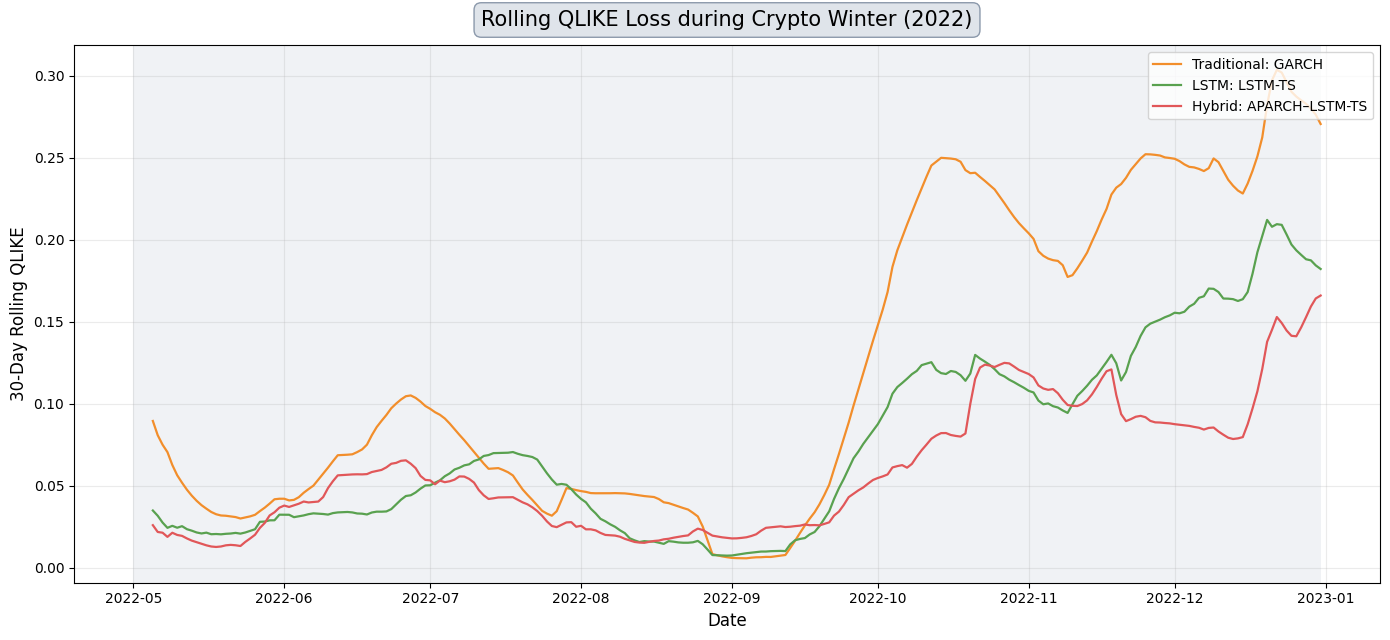


Step 11 completed successfully.

Saved full-sample rolling QLIKE figure files:
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_Over_Time_Full_Sample_Crisis_Regimes_Highlighted.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_Over_Time_Full_Sample_Crisis_Regimes_Highlighted.pdf

Saved individual crisis rolling QLIKE figure files:

COVID-19 Shock (2020)
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_COVID_19_Shock_2020.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_COVID_19_Shock_2020.pdf

China Mining Ban (2021)
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_China_Mining_Ban_2021.png
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_Loss_During_China_Mining_Ban_2021.pdf

Crypto Winter (2022)
/content/drive/MyDrive/BTC_Master_Final_Reanalysis/04_Figures/Rolling_QLIKE_L

In [2]:
# ============================================================
# STEP 11 — ROLLING QLIKE LOSS FIGURES
# Titles and saved file names do NOT include figure numbers
# Crisis-period rolling QLIKE figures are saved separately
# ============================================================


# ------------------------------------------------------------
# 1. Imports and paths
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


PROJECT_DIR = Path("/content/drive/MyDrive/BTC_Master_Final_Reanalysis")

FIGURES_DIR = PROJECT_DIR / "04_Figures"
FORECASTS_DIR = PROJECT_DIR / "06_Forecasts"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load forecast files
# ------------------------------------------------------------

traditional_forecasts = pd.read_csv(
    FORECASTS_DIR / "Traditional_Model_Forecasts.csv"
)

lstm_forecasts = pd.read_csv(
    FORECASTS_DIR / "LSTM_Model_Forecasts_Daily_Rolling_Optimized_Table3.csv"
)

hybrid_forecasts = pd.read_csv(
    FORECASTS_DIR / "Hybrid_Model_Forecasts_Daily_Rolling_Optimized_Table4.csv"
)


for frame in [
    traditional_forecasts,
    lstm_forecasts,
    hybrid_forecasts
]:
    frame["date"] = pd.to_datetime(
        frame["date"]
    )


# ------------------------------------------------------------
# 3. Merge forecast data
# ------------------------------------------------------------

base_columns = [
    "date",
    "Forecast_Regime",
    "Actual_Volatility"
]

forecast_data = (
    traditional_forecasts[
        base_columns
        + [
            "GARCH",
            "iGARCH",
            "TGARCH",
            "GJR-GARCH",
            "APARCH",
            "EGARCH"
        ]
    ]
    .merge(
        lstm_forecasts[
            base_columns
            + [
                "LSTM-T",
                "LSTM-TS",
                "LSTM-TSB"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        hybrid_forecasts[
            base_columns
            + [
                "Hybrid_GARCH_T",
                "Hybrid_TGARCH_TS",
                "Hybrid_EGARCH_TSB",
                "Hybrid_APARCH_TS"
            ]
        ],
        on=base_columns,
        how="inner",
        validate="one_to_one"
    )
    .sort_values("date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Crisis windows and colors
# Same style as the descriptive volatility figure
# ------------------------------------------------------------

crisis_windows = {

    "Post-Bubble Crash (2018)":
        (
            pd.Timestamp("2018-02-01"),
            pd.Timestamp("2018-12-31")
        ),

    "COVID-19 Shock (2020)":
        (
            pd.Timestamp("2020-02-20"),
            pd.Timestamp("2020-05-31")
        ),

    "China Mining Ban (2021)":
        (
            pd.Timestamp("2021-05-01"),
            pd.Timestamp("2021-07-31")
        ),

    "Crypto Winter (2022)":
        (
            pd.Timestamp("2022-05-01"),
            pd.Timestamp("2022-12-31")
        )
}


crisis_colors = {

    "Post-Bubble Crash (2018)":
        "#E8D2B3",

    "COVID-19 Shock (2020)":
        "#F4C7C3",

    "China Mining Ban (2021)":
        "#C7E3DF",

    "Crypto Winter (2022)":
        "#D5DCE3"
}


crisis_edge_colors = {

    "Post-Bubble Crash (2018)":
        "#B47A3C",

    "COVID-19 Shock (2020)":
        "#C94A44",

    "China Mining Ban (2021)":
        "#4A9B8F",

    "Crypto Winter (2022)":
        "#6B7C93"
}


# ------------------------------------------------------------
# 5. Selected model sets
# ------------------------------------------------------------

# Full-sample rolling QLIKE model-family representatives
figure6_models = {

    "TGARCH":
        "Traditional: TGARCH",

    "LSTM-T":
        "LSTM: LSTM-T",

    "Hybrid_GARCH_T":
        "Hybrid: GARCH–LSTM-T"
}


# Crisis-specific family-best models
figure7_models = {

    "Post-Bubble Crash (2018)": {
        "Traditional": ("TGARCH", "Traditional: TGARCH"),
        "LSTM": ("LSTM-T", "LSTM: LSTM-T"),
        "Hybrid": ("Hybrid_GARCH_T", "Hybrid: GARCH–LSTM-T"),
        "File stem": "Rolling_QLIKE_Loss_During_Post_Bubble_Crash_2018"
    },

    "COVID-19 Shock (2020)": {
        "Traditional": ("iGARCH", "Traditional: iGARCH"),
        "LSTM": ("LSTM-TSB", "LSTM: LSTM-TSB"),
        "Hybrid": ("Hybrid_TGARCH_TS", "Hybrid: TGARCH–LSTM-TS"),
        "File stem": "Rolling_QLIKE_Loss_During_COVID_19_Shock_2020"
    },

    "China Mining Ban (2021)": {
        "Traditional": ("GARCH", "Traditional: GARCH"),
        "LSTM": ("LSTM-T", "LSTM: LSTM-T"),
        "Hybrid": ("Hybrid_EGARCH_TSB", "Hybrid: EGARCH–LSTM-TSB"),
        "File stem": "Rolling_QLIKE_Loss_During_China_Mining_Ban_2021"
    },

    "Crypto Winter (2022)": {
        "Traditional": ("GARCH", "Traditional: GARCH"),
        "LSTM": ("LSTM-TS", "LSTM: LSTM-TS"),
        "Hybrid": ("Hybrid_APARCH_TS", "Hybrid: APARCH–LSTM-TS"),
        "File stem": "Rolling_QLIKE_Loss_During_Crypto_Winter_2022"
    }
}


# ------------------------------------------------------------
# 6. Keep common valid sample
# ------------------------------------------------------------

all_needed_models = sorted(
    set(figure6_models.keys())
    |
    {
        model_name
        for crisis_info in figure7_models.values()
        for key, value in crisis_info.items()
        if key in ["Traditional", "LSTM", "Hybrid"]
        for model_name, _ in [value]
    }
)

required_columns = [
    "Actual_Volatility"
] + all_needed_models

valid_values = forecast_data[
    required_columns
].to_numpy(dtype=float)

valid_mask = (
    np.isfinite(valid_values).all(axis=1)
    &
    (valid_values > 0).all(axis=1)
)

forecast_data = forecast_data.loc[
    valid_mask
].copy()

print("Common valid observations used for rolling-loss figures:", len(forecast_data))
print(
    "Forecast sample:",
    forecast_data["date"].min().date(),
    "to",
    forecast_data["date"].max().date()
)


# ------------------------------------------------------------
# 7. QLIKE function and rolling settings
# ------------------------------------------------------------

ROLLING_LOSS_WINDOW = 30
MIN_PERIODS = 5
EPSILON = 1e-10


def qlike_loss(actual, forecast):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    actual = np.maximum(
        actual,
        EPSILON
    )

    forecast = np.maximum(
        forecast,
        EPSILON
    )

    ratio = actual / forecast

    return ratio - np.log(ratio) - 1.0


# ------------------------------------------------------------
# 8. Compute daily QLIKE loss for all relevant models
# ------------------------------------------------------------

for model_name in all_needed_models:

    forecast_data[f"{model_name}_QLIKE"] = qlike_loss(
        forecast_data["Actual_Volatility"],
        forecast_data[model_name]
    )


# ------------------------------------------------------------
# 9. Helper function for full-sample crisis shading
# ------------------------------------------------------------

def add_crisis_shading_full_sample(axis, sample_start, sample_end):

    for crisis_name, (start_date, end_date) in crisis_windows.items():

        if end_date < sample_start or start_date > sample_end:
            continue

        shade_start = max(
            start_date,
            sample_start
        )

        shade_end = min(
            end_date,
            sample_end
        )

        axis.axvspan(
            shade_start,
            shade_end,
            color=crisis_colors[crisis_name],
            alpha=0.45,
            linewidth=0
        )

        middle_date = shade_start + (
            shade_end - shade_start
        ) / 2

        y_top = axis.get_ylim()[1]

        axis.text(
            middle_date,
            y_top * 0.95,
            crisis_name,
            ha="center",
            va="top",
            fontsize=9,
            rotation=90,
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor=crisis_edge_colors[crisis_name],
                alpha=0.85
            )
        )


# ------------------------------------------------------------
# 10. Full-sample rolling QLIKE figure
# ------------------------------------------------------------

full_rolling_title = (
    "Rolling QLIKE Loss over Time "
    "(Full Sample with Crisis Regimes Highlighted)"
)

full_rolling_file_stem = (
    "Rolling_QLIKE_Loss_Over_Time_"
    "Full_Sample_Crisis_Regimes_Highlighted"
)

full_rolling_data = forecast_data[
    ["date"]
].copy()

for model_name in figure6_models:

    full_rolling_data[f"{model_name}_Rolling_QLIKE"] = (
        forecast_data[f"{model_name}_QLIKE"]
        .rolling(
            window=ROLLING_LOSS_WINDOW,
            min_periods=MIN_PERIODS
        )
        .mean()
    )


fig, ax = plt.subplots(
    figsize=(14, 7)
)

line_colors = {

    "TGARCH":
        "#f28e2b",

    "LSTM-T":
        "#59a14f",

    "Hybrid_GARCH_T":
        "#e15759"
}


for model_name, label in figure6_models.items():

    ax.plot(
        full_rolling_data["date"],
        full_rolling_data[f"{model_name}_Rolling_QLIKE"],
        label=label,
        linewidth=1.6,
        color=line_colors[model_name]
    )


ax.set_title(
    full_rolling_title,
    fontsize=15,
    pad=14
)

ax.set_xlabel(
    "Date",
    fontsize=12
)

ax.set_ylabel(
    f"{ROLLING_LOSS_WINDOW}-Day Rolling QLIKE",
    fontsize=12
)

ax.grid(
    True,
    alpha=0.25
)

sample_start = full_rolling_data["date"].min()
sample_end = full_rolling_data["date"].max()

add_crisis_shading_full_sample(
    ax,
    sample_start,
    sample_end
)

ax.legend(
    loc="upper right",
    frameon=True
)

fig.tight_layout()

full_rolling_png = FIGURES_DIR / f"{full_rolling_file_stem}.png"
full_rolling_pdf = FIGURES_DIR / f"{full_rolling_file_stem}.pdf"

fig.savefig(
    full_rolling_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    full_rolling_pdf,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. Individual crisis-period rolling QLIKE figures
# ------------------------------------------------------------

available_crises = []
skipped_crises = []

for crisis_name, (start_date, end_date) in crisis_windows.items():

    crisis_mask = (
        (forecast_data["date"] >= start_date)
        &
        (forecast_data["date"] <= end_date)
    )

    if crisis_mask.sum() > 0:
        available_crises.append(crisis_name)
    else:
        skipped_crises.append(crisis_name)


print("\nCrisis windows available for individual rolling QLIKE figures:")
print(available_crises)

if skipped_crises:
    print("\nSkipped crisis windows outside forecast sample:")
    print(skipped_crises)


individual_crisis_paths = []

crisis_line_colors = {

    "Traditional":
        "#f28e2b",

    "LSTM":
        "#59a14f",

    "Hybrid":
        "#e15759"
}


for crisis_name in available_crises:

    start_date, end_date = crisis_windows[
        crisis_name
    ]

    crisis_slice = forecast_data.loc[
        (
            forecast_data["date"] >= start_date
        )
        &
        (
            forecast_data["date"] <= end_date
        )
    ].copy()

    crisis_info = figure7_models[
        crisis_name
    ]

    model_triplet = [
        ("Traditional", crisis_info["Traditional"]),
        ("LSTM", crisis_info["LSTM"]),
        ("Hybrid", crisis_info["Hybrid"])
    ]

    fig, ax = plt.subplots(
        figsize=(14, 6.5)
    )

    ax.axvspan(
        start_date,
        end_date,
        color=crisis_colors[crisis_name],
        alpha=0.35,
        linewidth=0
    )

    for family_name, (model_name, label) in model_triplet:

        crisis_slice[f"{model_name}_Rolling_QLIKE"] = (
            crisis_slice[f"{model_name}_QLIKE"]
            .rolling(
                window=ROLLING_LOSS_WINDOW,
                min_periods=MIN_PERIODS
            )
            .mean()
        )

        ax.plot(
            crisis_slice["date"],
            crisis_slice[f"{model_name}_Rolling_QLIKE"],
            label=label,
            linewidth=1.6,
            color=crisis_line_colors[family_name]
        )

    crisis_title = (
        "Rolling QLIKE Loss during "
        + crisis_name
    )

    ax.set_title(
        crisis_title,
        fontsize=15,
        pad=14,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor=crisis_colors[crisis_name],
            edgecolor=crisis_edge_colors[crisis_name],
            alpha=0.75
        )
    )

    ax.set_xlabel(
        "Date",
        fontsize=12
    )

    ax.set_ylabel(
        f"{ROLLING_LOSS_WINDOW}-Day Rolling QLIKE",
        fontsize=12
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        loc="upper right",
        frameon=True,
        fontsize=10
    )

    fig.tight_layout()

    crisis_file_stem = crisis_info[
        "File stem"
    ]

    crisis_png = FIGURES_DIR / f"{crisis_file_stem}.png"
    crisis_pdf = FIGURES_DIR / f"{crisis_file_stem}.pdf"

    fig.savefig(
        crisis_png,
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        crisis_pdf,
        bbox_inches="tight"
    )

    individual_crisis_paths.append(
        (
            crisis_name,
            crisis_png,
            crisis_pdf
        )
    )

    plt.show()


# ------------------------------------------------------------
# 12. Save rolling-loss data for transparency
# ------------------------------------------------------------

rolling_loss_data_file = FORECASTS_DIR / (
    "Rolling_QLIKE_Data_Used_For_Rolling_Loss_Figures.csv"
)

rolling_output = forecast_data.copy()

for model_name in all_needed_models:

    rolling_output[f"{model_name}_Rolling_QLIKE_30"] = (
        rolling_output[f"{model_name}_QLIKE"]
        .rolling(
            window=ROLLING_LOSS_WINDOW,
            min_periods=MIN_PERIODS
        )
        .mean()
    )

rolling_output.to_csv(
    rolling_loss_data_file,
    index=False
)


for crisis_name in available_crises:

    start_date, end_date = crisis_windows[
        crisis_name
    ]

    crisis_info = figure7_models[
        crisis_name
    ]

    crisis_data_file = FORECASTS_DIR / (
        "Rolling_QLIKE_Data_Used_For_"
        + crisis_info["File stem"]
        + ".csv"
    )

    crisis_output = rolling_output.loc[
        (
            rolling_output["date"] >= start_date
        )
        &
        (
            rolling_output["date"] <= end_date
        )
    ].copy()

    crisis_output.to_csv(
        crisis_data_file,
        index=False
    )


# ------------------------------------------------------------
# 13. Output saved paths
# ------------------------------------------------------------

print("\nStep 11 completed successfully.")

print("\nSaved full-sample rolling QLIKE figure files:")
print(full_rolling_png)
print(full_rolling_pdf)

print("\nSaved individual crisis rolling QLIKE figure files:")

for crisis_name, png_path, pdf_path in individual_crisis_paths:

    print("\n" + crisis_name)
    print(png_path)
    print(pdf_path)

print("\nSaved rolling-loss data:")
print(rolling_loss_data_file)